In [1]:
pip install rasterio numpy matplotlib pandas tqdm

Could not fetch URL https://pypi.org/simple/pip/: There was a problem confirming the ssl certificate: HTTPSConnectionPool(host='pypi.org', port=443): Max retries exceeded with url: /simple/pip/ (Caused by SSLError(SSLEOFError(8, '[SSL: UNEXPECTED_EOF_WHILE_READING] EOF occurred in violation of protocol (_ssl.c:1017)'))) - skipping
Note: you may need to restart the kernel to use updated packages.



--- Processing Index: VCI ---


Loading VCI: 100%|███████████████████████████████████████████████████████████████████| 140/140 [00:04<00:00, 33.21it/s]



--- Processing Index: TVDI ---


Loading TVDI: 100%|██████████████████████████████████████████████████████████████████| 140/140 [00:01<00:00, 84.64it/s]



--- Processing Index: SMDI ---


Loading SMDI: 100%|██████████████████████████████████████████████████████████████████| 140/140 [00:06<00:00, 21.20it/s]



--- Processing Index: SPEI-3 ---


Loading SPEI-3: 100%|████████████████████████████████████████████████████████████████| 140/140 [00:03<00:00, 42.02it/s]



--- Processing Index: SPEI-6 ---


Loading SPEI-6: 100%|████████████████████████████████████████████████████████████████| 140/140 [00:03<00:00, 36.92it/s]


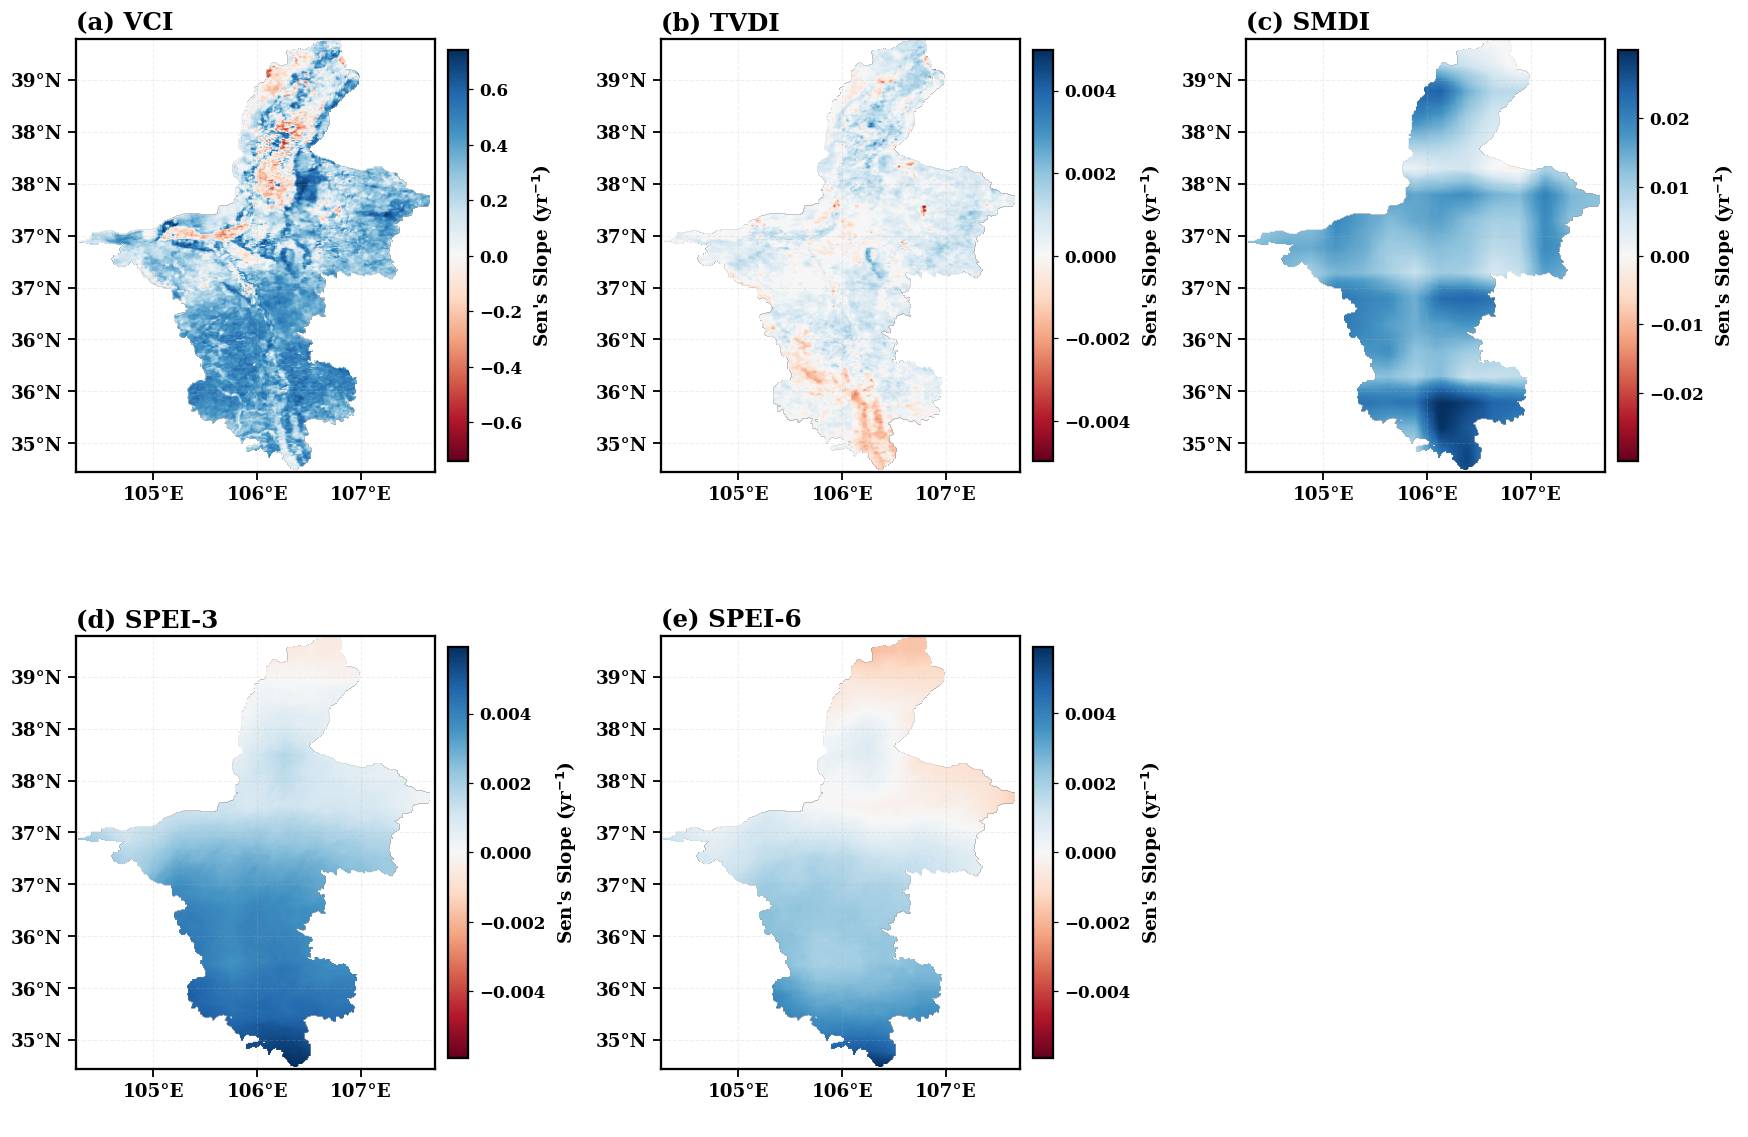


             TABLE: SPATIAL TREND STATISTICAL SUMMARY FOR JOURNAL PUBLICATION          
Index    | Active Pixels | Mean Slope (yr⁻¹)  | Positive (%)   | Negative (%)   | Sig. (p<0.05) %
-------------------------------------------------------------------------------------
VCI      | 57,002        | 0.275445           | 90.25          | 9.61           | 85.38          
TVDI     | 56,451        | 0.000355           | 74.11          | 20.57          | 41.16          
SMDI     | 57,009        | 0.014111           | 99.37          | 0.63           | 89.79          
SPEI-3   | 56,986        | 0.002417           | 95.26          | 4.74           | 15.32          
SPEI-6   | 56,986        | 0.001191           | 75.88          | 24.12          | 4.87           
Multi-panel figure successfully saved to: E:\2_Contribution\Final\Preprocess\3. Trend\Ningxia_All_Indices_Sens_Slope_Multipanel.png


In [12]:
import os
import glob
import re
import numpy as np
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy.stats import kendalltau
from tqdm import tqdm

# ---- Paths Configuration ----------------------------------------------------
BASE_DIR = r"E:\2_Contribution\Final\Preprocess"
INDICES_DIRS = {
    'VCI'   : os.path.join(BASE_DIR, "VCI"),
    'TVDI'  : os.path.join(BASE_DIR, "TVDI"),
    'SMDI'  : os.path.join(BASE_DIR, "SMDI"),
    'SPEI-3': os.path.join(BASE_DIR, "SPEI_3"),
    'SPEI-6': os.path.join(BASE_DIR, "SPEI_6")
}
FIG_DIR = os.path.join(BASE_DIR, "3. Trend")
os.makedirs(FIG_DIR, exist_ok=True)

# Define growing season months (April to October: 4 to 10)
GROWING_MONTHS = [4, 5, 6, 7, 8, 9, 10]
TARGET_CRS = "EPSG:4326"

# ---- Style reset, bold-everywhere defaults ----------------------------------
plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor'   : 'white',
    'axes.facecolor'     : 'white',
    'savefig.facecolor'  : 'white',
    'axes.edgecolor'     : 'black',
    'axes.linewidth'     : 1.5,
    'axes.labelcolor'    : 'black',
    'text.color'         : 'black',
    'axes.titlecolor'    : 'black',
    'xtick.color'        : 'black',
    'ytick.color'        : 'black',
    'figure.dpi'         : 110,
    'savefig.dpi'        : 400,
    'font.family'        : 'serif',
    'font.weight'        : 'bold',
    'axes.labelweight'   : 'bold',
    'axes.titleweight'   : 'bold',
})

# ---- Coordinate tick formatters (For Geographic Degrees) --------------------
def lat_fmt(v, pos):
    if v == 0:
        return "0\u00b0"
    return f"{abs(int(v))}\u00b0{'N' if v > 0 else 'S'}"

def lon_fmt(v, pos):
    if v == 0:
        return "0\u00b0"
    return f"{abs(int(v))}\u00b0{'E' if v > 0 else 'W'}"

# Storage for final multi-panel results
results_summary = []
trend_maps = {}
bounds_global = None

# -----------------------------------------------------------------------------
# 1. Loop Through Each Index, Process Rasters, and Compute Trends
# -----------------------------------------------------------------------------
for name, input_dir in INDICES_DIRS.items():
    print(f"\n--- Processing Index: {name} ---")
    search_pattern = os.path.join(input_dir, "*.tif")
    file_paths = glob.glob(search_pattern)
    
    if not file_paths:
        print(f"Warning: No TIFF files found in {input_dir}. Skipping...")
        continue

    file_data = []
    for fp in file_paths:
        filename = os.path.basename(fp)
        match = re.search(r"(\d{4})[_-]?(\d{2})\.tif", filename)
        if match:
            year, month = int(match.group(1)), int(match.group(2))
            if month in GROWING_MONTHS:
                file_data.append((year, month, fp))

    file_data.sort(key=lambda x: (x[0], x[1]))
    sorted_paths = [item[2] for item in file_data]

    if not sorted_paths:
        print(f"Warning: No files matched growing season months for {name}. Skipping...")
        continue

    # Load and reproject stack
    raster_stack = []
    sample_meta = None
    bounds = None

    for fp in tqdm(sorted_paths, desc=f"Loading {name}"):
        with rasterio.open(fp) as src:
            src_array = src.read(1).astype(np.float32)
            nodata = src.nodata
            if nodata is not None:
                src_array[src_array == nodata] = np.nan
            else:
                src_array[src_array <= -9999] = np.nan

            if src.crs and src.crs.to_string() != TARGET_CRS:
                dst_transform, width, height = calculate_default_transform(
                    src.crs, TARGET_CRS, src.width, src.height, *src.bounds
                )
                dst_array = np.empty((height, width), dtype=np.float32)
                reproject(
                    source=src_array, destination=dst_array,
                    src_transform=src.transform, src_crs=src.crs,
                    dst_transform=dst_transform, dst_crs=TARGET_CRS,
                    resampling=Resampling.nearest, dst_nodata=np.nan
                )
                if sample_meta is None:
                    sample_meta = src.meta.copy()
                    bounds = rasterio.transform.array_bounds(height, width, dst_transform)
                raster_stack.append(dst_array)
            else:
                if sample_meta is None:
                    sample_meta = src.meta.copy()
                    bounds = src.bounds
                raster_stack.append(src_array)

    stack = np.array(raster_stack)
    time_steps, height, width = stack.shape
    if bounds_global is None:
        bounds_global = bounds

    # Pixel-wise Sen's Slope and Mann-Kendall
    trend_map = np.full((height, width), np.nan, dtype=np.float32)
    pvalue_map = np.full((height, width), np.nan, dtype=np.float32)
    x = np.arange(time_steps)

    for i in range(height):
        for j in range(width):
            y = stack[:, i, j]
            mask = ~np.isnan(y)
            if np.sum(mask) > (time_steps * 0.4):
                valid_x = x[mask]
                valid_y = y[mask]
                try:
                    _, p_val = kendalltau(valid_x, valid_y)
                    pvalue_map[i, j] = p_val
                except Exception:
                    continue
                
                dx = valid_x[:, None] - valid_x
                dy = valid_y[:, None] - valid_y
                with np.errstate(divide='ignore', invalid='ignore'):
                    slopes = dy[dx > 0] / dx[dx > 0]
                if slopes.size > 0:
                    trend_map[i, j] = np.median(slopes)

    trend_maps[name] = trend_map

    # Compute statistics for summary table
    valid_vals = trend_map[~np.isnan(trend_map)]
    valid_pvals = pvalue_map[~np.isnan(pvalue_map)]
    mean_trend = np.mean(valid_vals) if valid_vals.size > 0 else 0
    pos_pct = (np.sum(valid_vals > 0) / valid_vals.size) * 100 if valid_vals.size > 0 else 0
    neg_pct = (np.sum(valid_vals < 0) / valid_vals.size) * 100 if valid_vals.size > 0 else 0
    sig_pct = (np.sum(valid_pvals < 0.05) / valid_pvals.size) * 100 if valid_pvals.size > 0 else 0

    results_summary.append({
        'Index': name,
        'Pixels': valid_vals.size,
        'Mean_Slope': mean_trend,
        'Pos_Pct': pos_pct,
        'Neg_Pct': neg_pct,
        'Sig_Pct': sig_pct
    })

# -----------------------------------------------------------------------------
# 2. Plotting Multi-Panel Figure (a, b, c, d, e)
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 11), facecolor='white')
axes = axes.flatten()
extent = [bounds_global[0], bounds_global[2], bounds_global[1], bounds_global[3]] if bounds_global else None

labels = ['(a) VCI', '(b) TVDI', '(c) SMDI', '(d) SPEI-3', '(e) SPEI-6']
index_keys = ['VCI', 'TVDI', 'SMDI', 'SPEI-3', 'SPEI-6']

for idx, key in enumerate(index_keys):
    ax = axes[idx]
    if key not in trend_maps:
        ax.axis('off')
        continue
        
    tmap = trend_maps[key]
    vmax = max(abs(np.nanmin(tmap)), abs(np.nanmax(tmap)))
    if np.isnan(vmax) or vmax == 0:
        vmax = 0.05

    im = ax.imshow(tmap, cmap='RdBu', vmin=-vmax, vmax=vmax, extent=extent, origin='upper')
    
    ax.set_title(labels[idx], fontsize=16, fontweight='bold', loc='left', pad=6)
    ax.set_xlim(extent[0], extent[1])
    ax.set_ylim(extent[2], extent[3])
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lon_fmt))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lat_fmt))
    ax.tick_params(axis='both', labelsize=12, width=1.2, length=5)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')
    ax.grid(alpha=0.2, linestyle='--', linewidth=0.7)
    
    # Add individual colorbar per subplot
    cbar = fig.colorbar(im, ax=ax, shrink=0.75, orientation='vertical', pad=0.03)
    cbar.set_label('Sen\'s Slope (yr$^{-1}$)', fontsize=12, fontweight='bold', labelpad=6)
    cbar.ax.tick_params(labelsize=11)

# Hide the 6th unused subplot slot
axes[5].axis('off')

plt.tight_layout()
out_fig = os.path.join(FIG_DIR, 'Ningxia_All_Indices_Sens_Slope_Multipanel.png')
plt.savefig(out_fig, bbox_inches='tight', dpi=400, facecolor='white')
plt.show()

# -----------------------------------------------------------------------------
# 3. Print Journal-Ready Table Summary
# -----------------------------------------------------------------------------
print("\n" + "="*85)
print("             TABLE: SPATIAL TREND STATISTICAL SUMMARY FOR JOURNAL PUBLICATION          ")
print("="*85)
print(f"{'Index':<8} | {'Active Pixels':<13} | {'Mean Slope (yr⁻¹)':<18} | {'Positive (%)':<14} | {'Negative (%)':<14} | {'Sig. (p<0.05) %':<15}")
print("-" * 85)
for res in results_summary:
    print(f"{res['Index']:<8} | {res['Pixels']:<13,d} | {res['Mean_Slope']:<18.6f} | {res['Pos_Pct']:<14.2f} | {res['Neg_Pct']:<14.2f} | {res['Sig_Pct']:<15.2f}")
print("="*85)
print(f"Multi-panel figure successfully saved to: {out_fig}")


--- Processing Index: VCI ---
Common 1 km grid: 396 × 476 pixels
Bounds: (104.20165081526194, 35.16475099962936, 107.76107668411836, 39.447371653008716)


Loading VCI:   0%|                                                                              | 0/20 [00:00<?, ?it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading VCI:   5%|███▌                                                                  | 1/20 [00:00<00:02,  7.60it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading VCI:  10%|███████                                                               | 2/20 [00:00<00:02,  7.76it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading VCI:  15%|██████████▌                                                           | 3/20 [00:00<00:02,  7.43i


--- Processing Index: TVDI ---


Loading TVDI:   0%|                                                                             | 0/20 [00:00<?, ?it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading TVDI:   5%|███▍                                                                 | 1/20 [00:00<00:02,  7.52it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading TVDI:  10%|██████▉                                                              | 2/20 [00:00<00:02,  7.32it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading TVDI:  15%|██████████▎                                                          | 3/20 [00:00<00:02,  7.10i


--- Processing Index: SMDI ---


Loading SMDI:   0%|                                                                             | 0/20 [00:00<?, ?it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SMDI:   5%|███▍                                                                 | 1/20 [00:00<00:02,  8.34it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SMDI:  10%|██████▉                                                              | 2/20 [00:00<00:02,  7.91it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SMDI:  15%|██████████▎                                                          | 3/20 [00:00<00:02,  7.95i


--- Processing Index: SPEI-3 ---


Loading SPEI-3:   0%|                                                                           | 0/20 [00:00<?, ?it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SPEI-3:   5%|███▎                                                               | 1/20 [00:00<00:02,  7.36it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SPEI-3:  10%|██████▋                                                            | 2/20 [00:00<00:02,  7.56it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SPEI-3:  15%|██████████                                                         | 3/20 [00:00<00:02,  7.82i

  → Applying final Gaussian smoothing (σ=4.0) to SPEI-3

--- Processing Index: SPEI-6 ---


Loading SPEI-6:   0%|                                                                           | 0/20 [00:00<?, ?it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SPEI-6:   5%|███▎                                                               | 1/20 [00:00<00:02,  7.74it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SPEI-6:  10%|██████▋                                                            | 2/20 [00:00<00:02,  7.97it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_4280\1564542442.py:142: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SPEI-6:  15%|██████████                                                         | 3/20 [00:00<00:02,  7.89i

  → Applying final Gaussian smoothing (σ=4.0) to SPEI-6


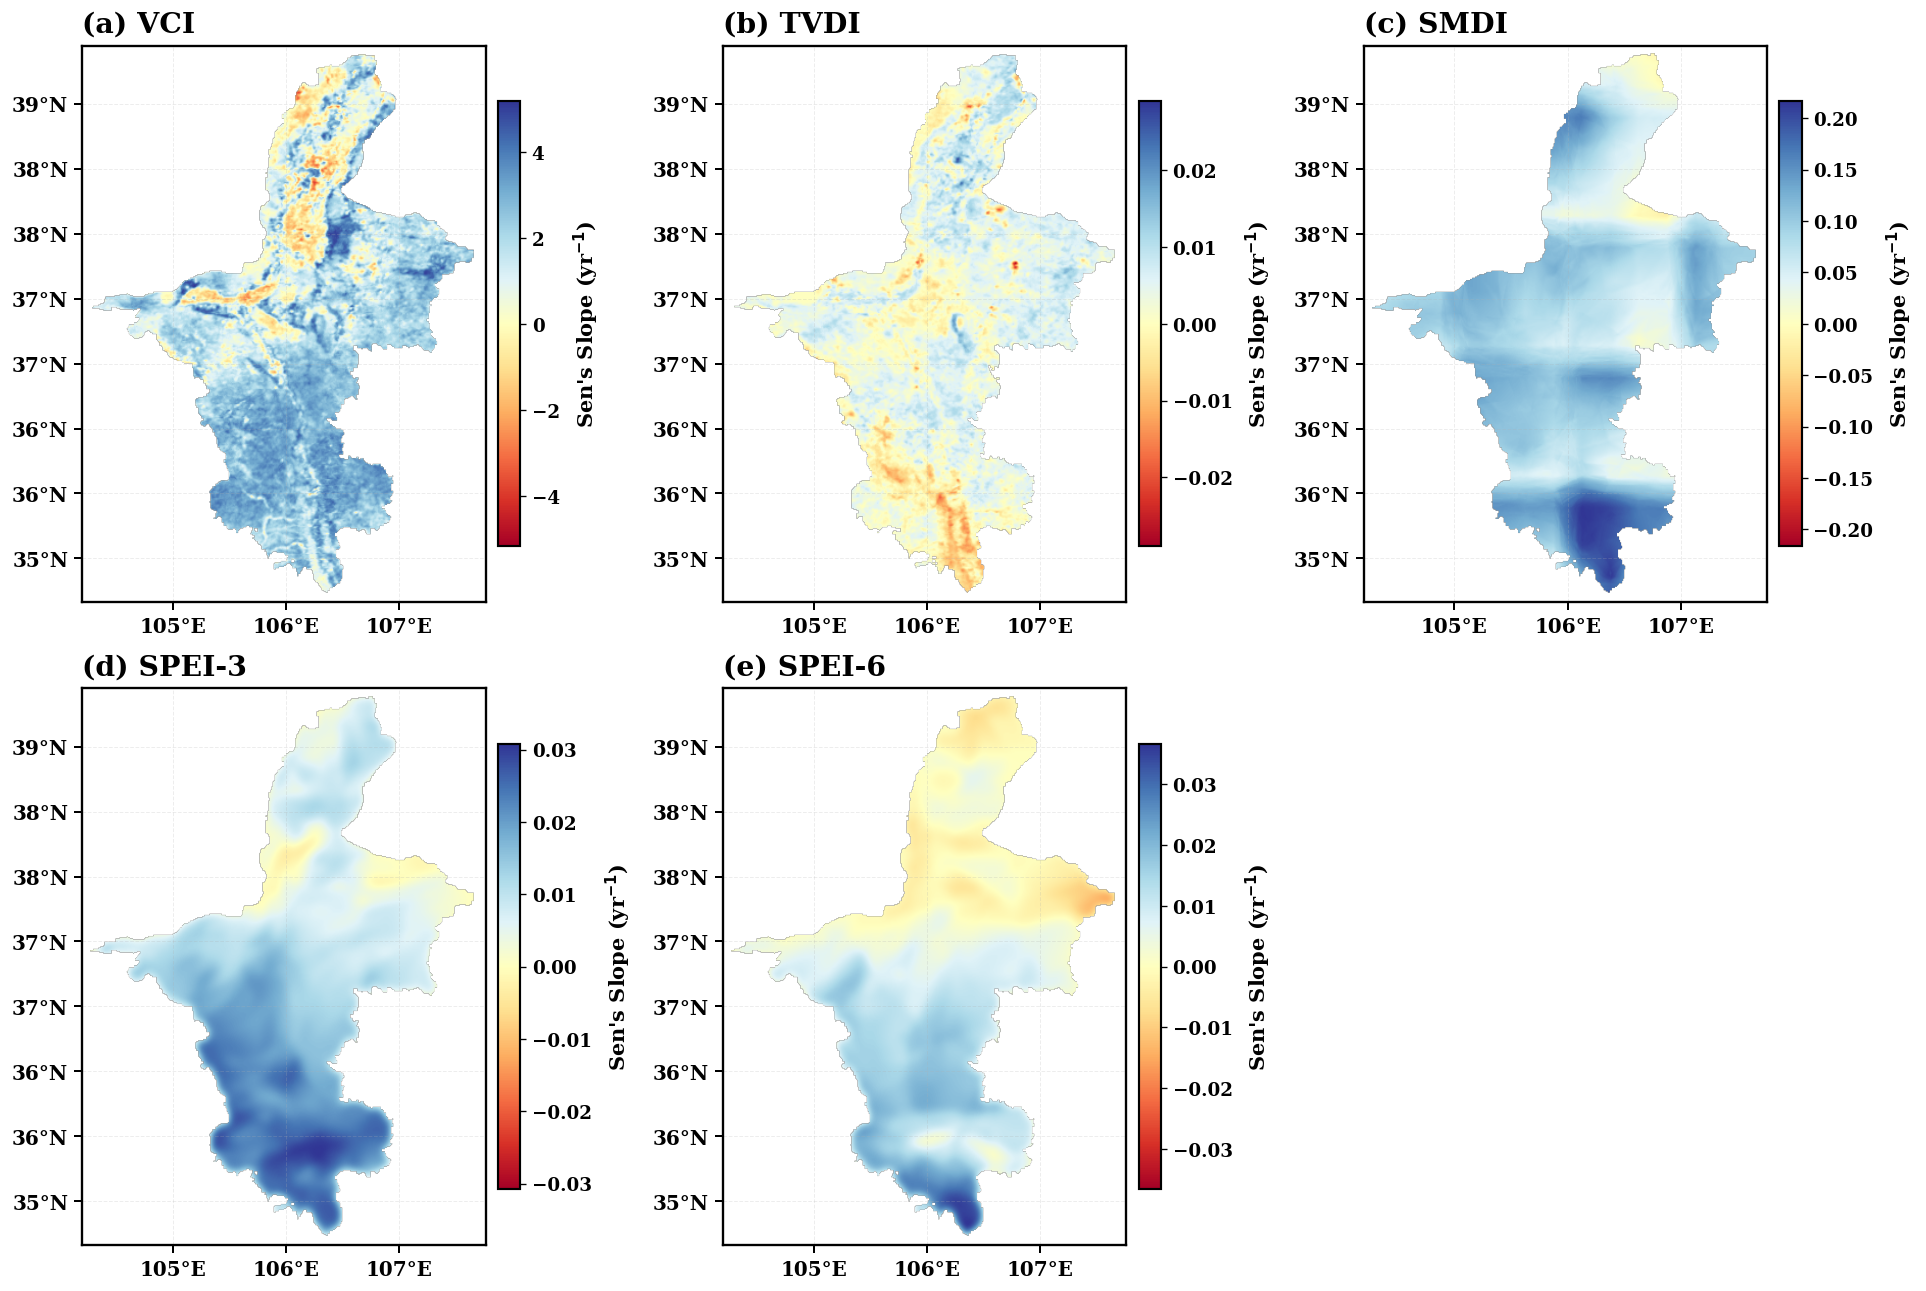


Final journal-ready figure saved → E:\2_Contribution\Final\Preprocess\3. Trend\Ningxia_All_Indices_Sens_Slope_FINAL_Journal.png


In [46]:
import os
import glob
import re
import numpy as np
import rasterio
from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.transform import from_origin
from scipy.ndimage import gaussian_filter
from scipy.stats import kendalltau, linregress
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from tqdm import tqdm

# ---- Paths ------------------------------------------------------------------
BASE_DIR = r"E:\2_Contribution\Final\Preprocess"
INDICES_DIRS = {
    'VCI'   : os.path.join(BASE_DIR, "VCI"),
    'TVDI'  : os.path.join(BASE_DIR, "TVDI"),
    'SMDI'  : os.path.join(BASE_DIR, "SMDI"),
    'SPEI-3': os.path.join(BASE_DIR, "SPEI_3"),
    'SPEI-6': os.path.join(BASE_DIR, "SPEI_6")
}
FIG_DIR = os.path.join(BASE_DIR, "3. Trend")
os.makedirs(FIG_DIR, exist_ok=True)

GROWING_MONTHS = [4, 5, 6, 7, 8, 9, 10]
TARGET_CRS = "EPSG:4326"
TARGET_RES = 0.009

SMOOTH_INDICES = {'SPEI-3', 'SPEI-6'}
SMOOTH_SIGMA   = 4.0        # slightly stronger for final clean look

# ---- Style ------------------------------------------------------------------
plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor'   : 'white',
    'axes.facecolor'     : 'white',
    'savefig.facecolor'  : 'white',
    'axes.edgecolor'     : 'black',
    'axes.linewidth'     : 1.4,
    'axes.labelcolor'    : 'black',
    'text.color'         : 'black',
    'axes.titlecolor'    : 'black',
    'xtick.color'        : 'black',
    'ytick.color'        : 'black',
    'figure.dpi'         : 120,
    'savefig.dpi'        : 400,
    'font.family'        : 'serif',
    'font.weight'        : 'bold',
    'axes.labelweight'   : 'bold',
    'axes.titleweight'   : 'bold',
})

def lat_fmt(v, pos):
    if v == 0: return "0°"
    return f"{abs(int(v))}°{'N' if v > 0 else 'S'}"

def lon_fmt(v, pos):
    if v == 0: return "0°"
    return f"{abs(int(v))}°{'E' if v > 0 else 'W'}"

results_summary = []
consistency_check = []
trend_maps = {}
pvalue_maps = {}
bounds_global = None
ref_transform = None
ref_width = None
ref_height = None

def load_and_reproject(fp, ref_transform, ref_width, ref_height):
    with rasterio.open(fp) as src:
        arr = src.read(1).astype(np.float32)
        nodata = src.nodata
        if nodata is not None:
            arr[arr == nodata] = np.nan
        else:
            arr[(arr <= -9999) | (arr > 1e10)] = np.nan

        dst = np.full((ref_height, ref_width), np.nan, dtype=np.float32)
        src_crs = src.crs if src.crs else TARGET_CRS

        reproject(
            source=arr,
            destination=dst,
            src_transform=src.transform,
            src_crs=src_crs,
            dst_transform=ref_transform,
            dst_crs=TARGET_CRS,
            resampling=Resampling.bilinear,
            dst_nodata=np.nan
        )
        return dst

# -----------------------------------------------------------------------------
for name, input_dir in INDICES_DIRS.items():
    print(f"\n--- Processing Index: {name} ---")
    file_paths = glob.glob(os.path.join(input_dir, "*.tif"))
    if not file_paths:
        print(f"Warning: No TIFF files found in {input_dir}. Skipping...")
        continue

    yearly_files = {}
    for fp in file_paths:
        match = re.search(r"(\d{4})[_-]?(\d{2})\.tif", os.path.basename(fp))
        if match:
            year, month = int(match.group(1)), int(match.group(2))
            if month in GROWING_MONTHS:
                yearly_files.setdefault(year, []).append(fp)

    years_sorted = sorted(yearly_files.keys())
    if not years_sorted:
        print(f"Warning: No growing-season files for {name}. Skipping...")
        continue

    if ref_transform is None:
        first_fp = yearly_files[years_sorted[0]][0]
        with rasterio.open(first_fp) as src:
            src_crs = src.crs if src.crs else TARGET_CRS
            left, bottom, right, top = transform_bounds(src_crs, TARGET_CRS, *src.bounds)

        left   -= 0.05
        right  += 0.05
        bottom -= 0.05
        top    += 0.05

        if (right - left) > 10 or (top - bottom) > 10:
            raise ValueError(f"Bounds look wrong: ({left:.3f}, {bottom:.3f}, {right:.3f}, {top:.3f})")

        ref_width  = int(np.ceil((right - left)  / TARGET_RES))
        ref_height = int(np.ceil((top   - bottom)/ TARGET_RES))
        ref_transform = from_origin(left, top, TARGET_RES, TARGET_RES)
        bounds_global = (left, bottom, right, top)
        print(f"Common 1 km grid: {ref_width} × {ref_height} pixels")
        print(f"Bounds: {bounds_global}")

    annual_stack = []
    for yr in tqdm(years_sorted, desc=f"Loading {name}"):
        monthly = [load_and_reproject(fp, ref_transform, ref_width, ref_height)
                   for fp in yearly_files[yr]]
        if monthly:
            annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))

    if len(annual_stack) < 5:
        print(f"Too few years for {name}. Skipping...")
        continue

    stack = np.array(annual_stack)
    time_steps, height, width = stack.shape
    x = np.array(years_sorted, dtype=np.float64)

    trend_map  = np.full((height, width), np.nan, dtype=np.float32)
    pvalue_map = np.full((height, width), np.nan, dtype=np.float32)

    for i in range(height):
        for j in range(width):
            y = stack[:, i, j]
            mask = ~np.isnan(y)
            if np.sum(mask) <= time_steps * 0.4:
                continue
            valid_x = x[mask]
            valid_y = y[mask]

            try:
                _, p_val = kendalltau(valid_x, valid_y)
                pvalue_map[i, j] = p_val
            except Exception:
                continue

            dx = valid_x[:, None] - valid_x
            dy = valid_y[:, None] - valid_y
            with np.errstate(divide='ignore', invalid='ignore'):
                slopes = dy[dx > 0] / dx[dx > 0]
            if slopes.size > 0:
                trend_map[i, j] = np.median(slopes)

    if name in SMOOTH_INDICES:
        print(f"  → Applying final Gaussian smoothing (σ={SMOOTH_SIGMA}) to {name}")
        valid_mask = ~np.isnan(trend_map)
        filled = np.where(valid_mask, trend_map, 0.0)
        smoothed = gaussian_filter(filled, sigma=SMOOTH_SIGMA)
        trend_map = np.where(valid_mask, smoothed, np.nan)

    trend_maps[name]  = trend_map
    pvalue_maps[name] = pvalue_map

    valid = ~np.isnan(trend_map)
    valid_vals  = trend_map[valid]
    valid_pvals = pvalue_map[valid]

    mean_trend  = float(np.mean(valid_vals)) if valid_vals.size else 0.0
    pos_pct     = 100 * np.mean(valid_vals > 0) if valid_vals.size else 0.0
    neg_pct     = 100 * np.mean(valid_vals < 0) if valid_vals.size else 0.0
    sig_pct     = 100 * np.mean(valid_pvals < 0.05) if valid_pvals.size else 0.0
    pos_sig_pct = 100 * np.mean((valid_vals > 0) & (valid_pvals < 0.05)) if valid_vals.size else 0.0
    neg_sig_pct = 100 * np.mean((valid_vals < 0) & (valid_pvals < 0.05)) if valid_vals.size else 0.0

    results_summary.append({
        'Index': name, 'Pixels': int(valid_vals.size),
        'Mean_Slope': mean_trend,
        'Pos_Pct': pos_pct, 'Neg_Pct': neg_pct,
        'Sig_Pct': sig_pct,
        'Pos_Sig_Pct': pos_sig_pct, 'Neg_Sig_Pct': neg_sig_pct
    })

    regional_series = np.nanmean(stack, axis=(1, 2))
    ols_slope, _, ols_r, ols_p, _ = linregress(x, regional_series)

    dx_r = x[:, None] - x
    dy_r = regional_series[:, None] - regional_series
    with np.errstate(divide='ignore', invalid='ignore'):
        slopes_r = dy_r[dx_r > 0] / dx_r[dx_r > 0]
    sen_slope_regional = float(np.median(slopes_r)) if slopes_r.size else np.nan
    _, mk_p_regional = kendalltau(x, regional_series)

    consistency_check.append({
        'Index': name,
        'OLS_slope_regional': ols_slope,
        'OLS_r': ols_r,
        'OLS_p': ols_p,
        'Sen_slope_regional': sen_slope_regional,
        'MK_p_regional': mk_p_regional,
        'Mean_of_pixel_Sen_slopes': mean_trend
    })

# -----------------------------------------------------------------------------
# Final polished figure
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16.5, 11.2), facecolor='white')
axes = axes.flatten()

left, bottom, right, top = bounds_global
extent = [left, right, bottom, top]

labels     = ['(a) VCI', '(b) TVDI', '(c) SMDI', '(d) SPEI-3', '(e) SPEI-6']
index_keys = ['VCI', 'TVDI', 'SMDI', 'SPEI-3', 'SPEI-6']

for idx, key in enumerate(index_keys):
    ax = axes[idx]
    if key not in trend_maps:
        ax.axis('off')
        continue

    tmap = trend_maps[key]
    vmax = np.nanmax(np.abs(tmap))
    if np.isnan(vmax) or vmax == 0:
        vmax = 0.05

    im = ax.imshow(
        tmap,
        cmap='RdYlBu',
        vmin=-vmax, vmax=vmax,
        extent=extent,
        origin='upper',
        interpolation='bilinear',
        aspect='auto'
    )

    # Improved title style
    ax.set_title(labels[idx], fontsize=17, fontweight='bold', loc='left', pad=8)

    ax.set_xlim(left, right)
    ax.set_ylim(bottom, top)

    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lon_fmt))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lat_fmt))
    ax.tick_params(axis='both', labelsize=12, width=1.2, length=5)
    for lab in ax.get_xticklabels() + ax.get_yticklabels():
        lab.set_fontweight('bold')
    ax.grid(alpha=0.22, linestyle='--', linewidth=0.6)

    cbar = fig.colorbar(im, ax=ax, shrink=0.80, orientation='vertical', pad=0.025)
    cbar.set_label("Sen's Slope (yr$^{-1}$)", fontsize=12.5, fontweight='bold', labelpad=7)
    cbar.ax.tick_params(labelsize=11)
    cbar.outline.set_linewidth(1.3)

axes[5].axis('off')

plt.tight_layout(rect=[0.01, 0.01, 0.99, 0.98])
out_fig = os.path.join(FIG_DIR, 'Ningxia_All_Indices_Sens_Slope_FINAL_Journal.png')
plt.savefig(out_fig, bbox_inches='tight', dpi=400, facecolor='white')
plt.show()
print(f"\nFinal journal-ready figure saved → {out_fig}")


COMMON GRID
CRS: EPSG:4326
Resolution: 0.009
Dimensions: 396 × 476
Bounds: (104.20165081526194, 35.16337165300872, 107.76565081526194, 39.447371653008716)

PROCESSING: VCI

Preparing VCI
Available years: 20
Year range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend analysis: 100%|█████████████████████████████████████████████████████| 476/476 [00:32<00:00, 14.73it/s]



Summary: VCI
Index: VCI
Valid_Pixels: 66436
Mean_Sen_Slope: 1.869464415536176
Increasing_Area_Pct: 90.15194930591454
Decreasing_Area_Pct: 9.848050694085462
FDR_Significant_Area_Pct: 69.50046197409455
FDR_Sig_Increasing_Area_Pct: 66.64057017157518
FDR_Sig_Decreasing_Area_Pct: 2.859891802519362
Median_Q_Value: 0.004677082411944866

PROCESSING: TVDI

Preparing TVDI
Available years: 20
Year range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend analysis: 100%|█████████████████████████████████████████████████████| 476/476 [00:33<00:00, 14.24it/s]



Summary: TVDI
Index: TVDI
Valid_Pixels: 65838
Mean_Sen_Slope: 0.0030182239651891105
Increasing_Area_Pct: 79.47043491219989
Decreasing_Area_Pct: 20.37720706738668
FDR_Significant_Area_Pct: 30.834221953258638
FDR_Sig_Increasing_Area_Pct: 27.319870328192785
FDR_Sig_Decreasing_Area_Pct: 3.514351625065856
Median_Q_Value: 0.16583967208862305

PROCESSING: SMDI

Preparing SMDI
Available years: 20
Year range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend analysis: 100%|█████████████████████████████████████████████████████| 476/476 [00:33<00:00, 14.31it/s]



Summary: SMDI
Index: SMDI
Valid_Pixels: 66461
Mean_Sen_Slope: 0.09270007430637968
Increasing_Area_Pct: 99.15036182784256
Decreasing_Area_Pct: 0.8496381721574223
FDR_Significant_Area_Pct: 12.40891950531906
FDR_Sig_Increasing_Area_Pct: 12.40891950531906
FDR_Sig_Decreasing_Area_Pct: 0.0
Median_Q_Value: 0.10624125599861145

PROCESSING: SPEI-3

Preparing SPEI-3
Available years: 20
Year range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend analysis: 100%|█████████████████████████████████████████████████████| 476/476 [00:32<00:00, 14.43it/s]



Summary: SPEI-3
Index: SPEI-3
Valid_Pixels: 66436
Mean_Sen_Slope: 0.01364903524002824
Increasing_Area_Pct: 96.75865271305882
Decreasing_Area_Pct: 3.241347286941169
FDR_Significant_Area_Pct: 0.0
FDR_Sig_Increasing_Area_Pct: 0.0
FDR_Sig_Decreasing_Area_Pct: 0.0
Median_Q_Value: 1.0

PROCESSING: SPEI-6

Preparing SPEI-6
Available years: 20
Year range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend analysis: 100%|█████████████████████████████████████████████████████| 476/476 [00:32<00:00, 14.46it/s]



Summary: SPEI-6
Index: SPEI-6
Valid_Pixels: 66436
Mean_Sen_Slope: 0.007821389761106193
Increasing_Area_Pct: 77.0445720411777
Decreasing_Area_Pct: 22.955427958822295
FDR_Significant_Area_Pct: 0.0
FDR_Sig_Increasing_Area_Pct: 0.0
FDR_Sig_Decreasing_Area_Pct: 0.0
Median_Q_Value: 1.0


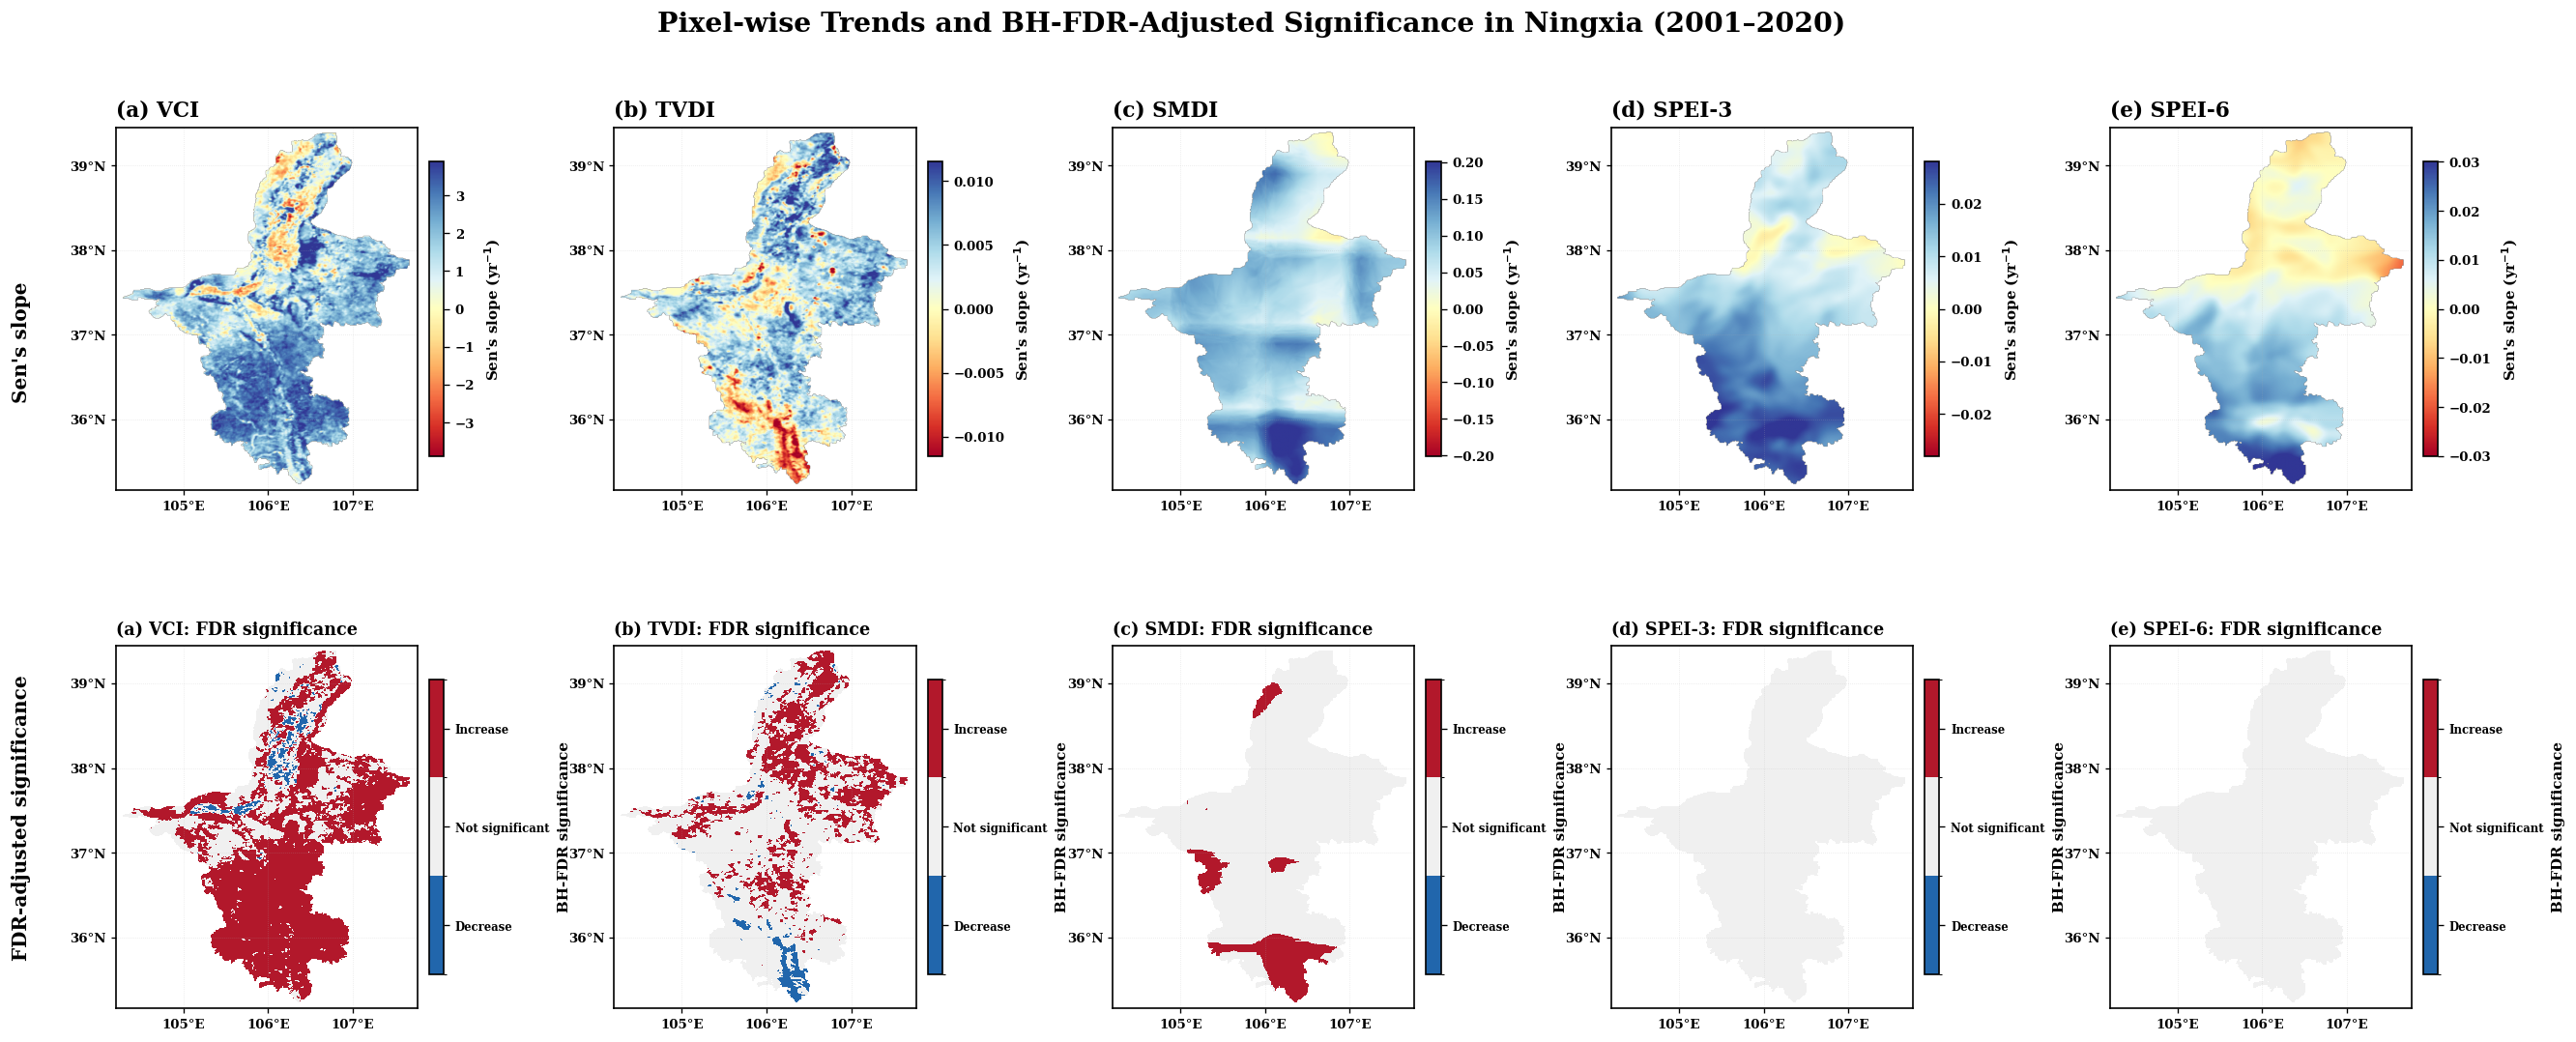


Figure saved:
E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Spatio_pixelwise\Ningxia_Spatial_Trends_Sen_Slope_BH_FDR_FINAL.png

Summary saved:
E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Spatio_pixelwise\Ningxia_Spatio_Pixelwise_Trend_FDR_Summary.txt

PROCESSING COMPLETED
Output folder: E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Spatio_pixelwise


In [5]:
import os
import re
import glob
import warnings

import numpy as np
import rasterio
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.transform import from_origin

from scipy.ndimage import gaussian_filter
from scipy.stats import kendalltau, theilslopes
from matplotlib.colors import ListedColormap, BoundaryNorm
from tqdm import tqdm


# =============================================================================
# 1. PATHS AND SETTINGS
# =============================================================================

BASE_DIR = r"E:\2_Contribution\Final\Preprocess"

INDICES_DIRS = {
    "VCI": os.path.join(BASE_DIR, "VCI"),
    "TVDI": os.path.join(BASE_DIR, "TVDI"),
    "SMDI": os.path.join(BASE_DIR, "SMDI"),
    "SPEI-3": os.path.join(BASE_DIR, "SPEI_3"),
    "SPEI-6": os.path.join(BASE_DIR, "SPEI_6")
}

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "3. Trend",
    "Update result",
    "with FDR",
    "Spatio_pixelwise"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

START_YEAR = 2001
END_YEAR = 2020

GROWING_MONTHS = [4, 5, 6, 7, 8, 9, 10]

TARGET_CRS = "EPSG:4326"
TARGET_RES = 0.009

FDR_ALPHA = 0.05

MIN_VALID_YEARS = 15
MIN_VALID_FRACTION = 0.75

REQUIRE_ALL_MONTHS = True

# Visual smoothing ONLY for SPEI slope maps.
# Does not alter analytical slope, p-value, q-value or significance rasters.
SMOOTH_SPEI_FOR_DISPLAY = True
SPEI_DISPLAY_SIGMA = 4.0

# Coordinate intervals.
LON_INTERVAL = 1.0
LAT_INTERVAL = 1.0


# =============================================================================
# 2. FIGURE STYLE
# =============================================================================

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.linewidth": 1.0,

    "font.family": "serif",
    "font.size": 9,
    "font.weight": "bold",

    "axes.labelweight": "bold",
    "axes.titleweight": "bold",

    "xtick.color": "black",
    "ytick.color": "black",

    "savefig.dpi": 400
})


def longitude_formatter(value, position):
    return f"{abs(value):.0f}°{'E' if value >= 0 else 'W'}"


def latitude_formatter(value, position):
    return f"{abs(value):.0f}°{'N' if value >= 0 else 'S'}"


# =============================================================================
# 3. BENJAMINI-HOCHBERG FDR
# =============================================================================

def benjamini_hochberg(p_values):

    p_values = np.asarray(p_values, dtype=np.float64)

    q_values = np.full(
        p_values.shape,
        np.nan,
        dtype=np.float64
    )

    valid = np.isfinite(p_values)

    p = p_values[valid]

    if p.size == 0:
        return q_values

    m = len(p)

    order = np.argsort(p)

    sorted_p = p[order]

    ranks = np.arange(1, m + 1, dtype=np.float64)

    adjusted = sorted_p * m / ranks

    adjusted = np.minimum.accumulate(
        adjusted[::-1]
    )[::-1]

    adjusted = np.clip(adjusted, 0, 1)

    sorted_q = np.empty_like(adjusted)

    sorted_q[order] = adjusted

    q_values[valid] = sorted_q

    return q_values


# =============================================================================
# 4. FIND MONTHLY FILES
# =============================================================================

def find_monthly_files(folder):

    files = glob.glob(
        os.path.join(folder, "*.tif")
    )

    yearly_files = {}

    for fp in files:

        filename = os.path.basename(fp)

        match = re.search(
            r"(\d{4})[_-](\d{2})\.tif$",
            filename,
            re.IGNORECASE
        )

        if not match:
            continue

        year = int(match.group(1))
        month = int(match.group(2))

        if (
            START_YEAR <= year <= END_YEAR
            and month in GROWING_MONTHS
        ):

            yearly_files.setdefault(
                year, {}
            )[month] = fp

    return yearly_files


# =============================================================================
# 5. FIND ANNUAL TVDI FILES
# =============================================================================

def find_annual_tvdi_files(folder):

    candidate_dirs = [
        os.path.join(folder, "annual"),
        os.path.join(folder, "Annual"),
        os.path.join(folder, "annaul"),
        os.path.join(folder, "Annual_GS"),
        folder
    ]

    annual_files = {}

    for candidate in candidate_dirs:

        if not os.path.isdir(candidate):
            continue

        for fp in glob.glob(
            os.path.join(candidate, "*.tif")
        ):

            filename = os.path.basename(fp)

            match = re.search(
                r"(\d{4})\.tif$",
                filename,
                re.IGNORECASE
            )

            if match:

                year = int(match.group(1))

                if START_YEAR <= year <= END_YEAR:
                    annual_files[year] = fp

        if annual_files:
            break

    return annual_files


# =============================================================================
# 6. CREATE COMMON GRID
# =============================================================================

def create_reference_grid(vci_folder):

    vci_files = find_monthly_files(vci_folder)

    if not vci_files:
        raise FileNotFoundError(
            "Monthly VCI files were not found."
        )

    first_year = min(vci_files.keys())

    first_month = min(vci_files[first_year].keys())

    first_fp = vci_files[first_year][first_month]

    with rasterio.open(first_fp) as src:

        source_crs = src.crs if src.crs else TARGET_CRS

        left, bottom, right, top = transform_bounds(
            source_crs,
            TARGET_CRS,
            *src.bounds,
            densify_pts=21
        )

    left -= 0.05
    right += 0.05
    bottom -= 0.05
    top += 0.05

    width = int(np.ceil(
        (right - left) / TARGET_RES
    ))

    height = int(np.ceil(
        (top - bottom) / TARGET_RES
    ))

    transform = from_origin(
        left,
        top,
        TARGET_RES,
        TARGET_RES
    )

    actual_right = left + width * TARGET_RES
    actual_bottom = top - height * TARGET_RES

    bounds = (
        left,
        actual_bottom,
        actual_right,
        top
    )

    print("\nCOMMON GRID")
    print("CRS:", TARGET_CRS)
    print("Resolution:", TARGET_RES)
    print("Dimensions:", width, "×", height)
    print("Bounds:", bounds)

    return transform, width, height, bounds


# =============================================================================
# 7. LOAD AND REPROJECT RASTER
# =============================================================================

def load_and_reproject(
    filepath,
    ref_transform,
    ref_width,
    ref_height
):

    with rasterio.open(filepath) as src:

        source = src.read(1).astype(np.float32)

        if src.nodata is not None:
            source[source == src.nodata] = np.nan

        source[~np.isfinite(source)] = np.nan

        source_crs = src.crs if src.crs else TARGET_CRS

        destination = np.full(
            (ref_height, ref_width),
            np.nan,
            dtype=np.float32
        )

        reproject(
            source=source,
            destination=destination,

            src_transform=src.transform,
            src_crs=source_crs,
            src_nodata=np.nan,

            dst_transform=ref_transform,
            dst_crs=TARGET_CRS,
            dst_nodata=np.nan,

            resampling=Resampling.bilinear
        )

        return destination


# =============================================================================
# 8. BUILD ANNUAL GROWING-SEASON STACK
# =============================================================================

def build_annual_stack(
    index_name,
    input_folder,
    ref_transform,
    ref_width,
    ref_height
):

    print(f"\nPreparing {index_name}")

    monthly_files = find_monthly_files(input_folder)

    use_annual_tvdi = False
    annual_tvdi_files = {}

    if index_name == "TVDI" and not monthly_files:

        annual_tvdi_files = find_annual_tvdi_files(
            input_folder
        )

        if annual_tvdi_files:
            use_annual_tvdi = True
            print("Using existing annual TVDI rasters.")

    annual_data = {}
    missing_years = []

    for year in range(START_YEAR, END_YEAR + 1):

        if use_annual_tvdi:

            if year not in annual_tvdi_files:
                missing_years.append(year)
                continue

            annual_data[year] = load_and_reproject(
                annual_tvdi_files[year],
                ref_transform,
                ref_width,
                ref_height
            )

        else:

            month_dict = monthly_files.get(year, {})

            available_months = sorted(
                month_dict.keys()
            )

            if REQUIRE_ALL_MONTHS:

                if not all(
                    m in available_months
                    for m in GROWING_MONTHS
                ):
                    missing_years.append(year)
                    continue

            elif len(available_months) == 0:

                missing_years.append(year)
                continue

            selected_files = [
                month_dict[m]
                for m in GROWING_MONTHS
                if m in month_dict
            ]

            monthly_arrays = []

            for fp in selected_files:

                monthly_arrays.append(
                    load_and_reproject(
                        fp,
                        ref_transform,
                        ref_width,
                        ref_height
                    )
                )

            monthly_stack = np.stack(
                monthly_arrays,
                axis=0
            )

            with warnings.catch_warnings():

                warnings.simplefilter(
                    "ignore",
                    RuntimeWarning
                )

                annual_mean = np.nanmean(
                    monthly_stack,
                    axis=0
                )

            if REQUIRE_ALL_MONTHS:

                valid_month_count = np.sum(
                    np.isfinite(monthly_stack),
                    axis=0
                )

                annual_mean[
                    valid_month_count != len(GROWING_MONTHS)
                ] = np.nan

            annual_data[year] = annual_mean

    years = sorted(annual_data.keys())

    if len(years) < MIN_VALID_YEARS:

        raise ValueError(
            f"{index_name}: only {len(years)} valid years. "
            f"Minimum required: {MIN_VALID_YEARS}."
        )

    stack = np.stack(
        [annual_data[y] for y in years],
        axis=0
    )

    print("Available years:", len(years))
    print("Year range:", years[0], "-", years[-1])

    if missing_years:
        print("Missing years:", missing_years)

    return np.asarray(years, dtype=np.float64), stack


# =============================================================================
# 9. PIXEL-WISE MANN-KENDALL AND SEN'S SLOPE
# =============================================================================

def calculate_pixelwise_trends(years, stack):

    n_years, height, width = stack.shape

    slope_map = np.full(
        (height, width),
        np.nan,
        dtype=np.float32
    )

    pvalue_map = np.full(
        (height, width),
        np.nan,
        dtype=np.float32
    )

    required_valid = max(
        MIN_VALID_YEARS,
        int(np.ceil(
            n_years * MIN_VALID_FRACTION
        ))
    )

    print(
        "Minimum valid observations per pixel:",
        required_valid
    )

    for row in tqdm(
        range(height),
        desc="Pixel-wise trend analysis"
    ):

        for col in range(width):

            values = stack[:, row, col]

            valid = np.isfinite(values)

            if np.sum(valid) < required_valid:
                continue

            valid_years = years[valid]
            valid_values = values[valid]

            try:

                _, p_value = kendalltau(
                    valid_years,
                    valid_values
                )

                if not np.isfinite(p_value):
                    continue

                pvalue_map[row, col] = p_value

                slope = theilslopes(
                    valid_values,
                    valid_years
                ).slope

                if np.isfinite(slope):
                    slope_map[row, col] = slope

            except Exception:
                continue

    return slope_map, pvalue_map


# =============================================================================
# 10. APPLY FDR
# =============================================================================

def apply_pixelwise_fdr(
    slope_map,
    pvalue_map
):

    valid = (
        np.isfinite(slope_map) &
        np.isfinite(pvalue_map)
    )

    qvalue_map = np.full(
        pvalue_map.shape,
        np.nan,
        dtype=np.float32
    )

    qvalue_map[valid] = benjamini_hochberg(
        pvalue_map[valid]
    ).astype(np.float32)

    # -1 = significant decrease
    #  0 = not significant
    # +1 = significant increase
    # NaN = no valid observation

    significance_map = np.full(
        slope_map.shape,
        np.nan,
        dtype=np.float32
    )

    significance_map[valid] = 0

    significant = (
        valid &
        (qvalue_map <= FDR_ALPHA)
    )

    significance_map[
        significant & (slope_map > 0)
    ] = 1

    significance_map[
        significant & (slope_map < 0)
    ] = -1

    return qvalue_map, significance_map


# =============================================================================
# 11. MASK-AWARE GAUSSIAN SMOOTHING FOR DISPLAY ONLY
# =============================================================================

def smooth_for_display(array, sigma):

    """
    Normalized Gaussian smoothing.

    This function is used only for visual display.
    It does not modify the original analytical raster.
    """

    valid = np.isfinite(array)

    if not np.any(valid):
        return array.copy()

    values = np.where(
        valid,
        array,
        0.0
    )

    weights = valid.astype(np.float32)

    numerator = gaussian_filter(
        values,
        sigma=sigma,
        mode="nearest"
    )

    denominator = gaussian_filter(
        weights,
        sigma=sigma,
        mode="nearest"
    )

    result = np.full(
        array.shape,
        np.nan,
        dtype=np.float32
    )

    good = denominator > 1e-6

    result[good] = (
        numerator[good] /
        denominator[good]
    )

    # Preserve the original valid-data footprint.
    result[~valid] = np.nan

    return result


# =============================================================================
# 12. AREA-WEIGHTED SUMMARY
# =============================================================================

def calculate_summary(
    index_name,
    slope_map,
    pvalue_map,
    qvalue_map,
    significance_map,
    bounds
):

    valid = (
        np.isfinite(slope_map) &
        np.isfinite(qvalue_map)
    )

    if not np.any(valid):
        return None

    slopes = slope_map[valid]
    q_values = qvalue_map[valid]

    significance = significance_map[valid]

    top = bounds[3]

    height = slope_map.shape[0]

    latitudes = (
        top -
        (np.arange(height) + 0.5) * TARGET_RES
    )

    row_weights = np.cos(
        np.deg2rad(latitudes)
    )

    weights = np.broadcast_to(
        row_weights[:, None],
        slope_map.shape
    )[valid]

    total_weight = np.sum(weights)

    mean_slope = np.sum(
        slopes * weights
    ) / total_weight

    significant = q_values <= FDR_ALPHA

    increasing = slopes > 0
    decreasing = slopes < 0

    sig_increasing = significant & increasing
    sig_decreasing = significant & decreasing

    def weighted_pct(mask):

        return (
            100 *
            np.sum(weights[mask]) /
            total_weight
        )

    return {
        "Index": index_name,
        "Valid_Pixels": int(np.sum(valid)),
        "Mean_Sen_Slope": float(mean_slope),

        "Increasing_Area_Pct": float(
            weighted_pct(increasing)
        ),

        "Decreasing_Area_Pct": float(
            weighted_pct(decreasing)
        ),

        "FDR_Significant_Area_Pct": float(
            weighted_pct(significant)
        ),

        "FDR_Sig_Increasing_Area_Pct": float(
            weighted_pct(sig_increasing)
        ),

        "FDR_Sig_Decreasing_Area_Pct": float(
            weighted_pct(sig_decreasing)
        ),

        "Median_Q_Value": float(
            np.nanmedian(q_values)
        )
    }


# =============================================================================
# 13. SAVE GEOTIFF
# =============================================================================

def save_geotiff(
    filepath,
    array,
    ref_transform,
    ref_width,
    ref_height
):

    nodata = -9999.0

    output_array = np.where(
        np.isfinite(array),
        array,
        nodata
    ).astype(np.float32)

    profile = {
        "driver": "GTiff",
        "height": ref_height,
        "width": ref_width,
        "count": 1,
        "dtype": "float32",
        "crs": TARGET_CRS,
        "transform": ref_transform,
        "nodata": nodata,
        "compress": "lzw"
    }

    with rasterio.open(
        filepath,
        "w",
        **profile
    ) as dst:

        dst.write(output_array, 1)


# =============================================================================
# 14. PROCESS ALL INDICES
# =============================================================================

ref_transform, ref_width, ref_height, bounds = (
    create_reference_grid(
        INDICES_DIRS["VCI"]
    )
)

trend_results = {}
summary_results = []

for index_name, input_folder in INDICES_DIRS.items():

    print("\n" + "=" * 70)
    print("PROCESSING:", index_name)
    print("=" * 70)

    years, stack = build_annual_stack(
        index_name,
        input_folder,
        ref_transform,
        ref_width,
        ref_height
    )

    slope_map, pvalue_map = calculate_pixelwise_trends(
        years,
        stack
    )

    qvalue_map, significance_map = apply_pixelwise_fdr(
        slope_map,
        pvalue_map
    )

    summary = calculate_summary(
        index_name,
        slope_map,
        pvalue_map,
        qvalue_map,
        significance_map,
        bounds
    )

    if summary is None:
        print("No valid pixels:", index_name)
        continue

    trend_results[index_name] = {
        "slope": slope_map,
        "pvalue": pvalue_map,
        "qvalue": qvalue_map,
        "significance": significance_map
    }

    summary_results.append(summary)

    # Save ORIGINAL analytical rasters.
    save_geotiff(
        os.path.join(
            OUTPUT_DIR,
            f"{index_name}_Sen_Slope.tif"
        ),
        slope_map,
        ref_transform,
        ref_width,
        ref_height
    )

    save_geotiff(
        os.path.join(
            OUTPUT_DIR,
            f"{index_name}_FDR_qvalue.tif"
        ),
        qvalue_map,
        ref_transform,
        ref_width,
        ref_height
    )

    save_geotiff(
        os.path.join(
            OUTPUT_DIR,
            f"{index_name}_FDR_Significance.tif"
        ),
        significance_map,
        ref_transform,
        ref_width,
        ref_height
    )

    print("\nSummary:", index_name)

    for key, value in summary.items():
        print(f"{key}: {value}")


# =============================================================================
# 15. FIGURE GENERATION
# =============================================================================

index_order = [
    "VCI",
    "TVDI",
    "SMDI",
    "SPEI-3",
    "SPEI-6"
]

panel_labels = [
    "(a) VCI",
    "(b) TVDI",
    "(c) SMDI",
    "(d) SPEI-3",
    "(e) SPEI-6"
]

left, bottom, right, top = bounds

extent = [
    left,
    right,
    bottom,
    top
]

# Significance map colors.
sig_cmap = ListedColormap([
    "#2166AC",  # Significant decrease
    "#F0F0F0",  # Not significant
    "#B2182B"   # Significant increase
])

sig_norm = BoundaryNorm(
    [-1.5, -0.5, 0.5, 1.5],
    sig_cmap.N
)

fig, axes = plt.subplots(
    2,
    5,
    figsize=(22, 10),
    facecolor="white"
)

# Keep consistent map dimensions and spacing.
fig.subplots_adjust(
    left=0.055,
    right=0.965,
    bottom=0.09,
    top=0.88,
    wspace=0.52,
    hspace=0.30
)

for col, index_name in enumerate(index_order):

    ax_slope = axes[0, col]
    ax_sig = axes[1, col]

    if index_name not in trend_results:

        ax_slope.axis("off")
        ax_sig.axis("off")
        continue

    slope_map = trend_results[index_name]["slope"]

    significance_map = trend_results[index_name][
        "significance"
    ]

    # ---------------------------------------------------------
    # DISPLAY-ONLY SMOOTHING FOR SPEI
    # ---------------------------------------------------------

    display_slope = slope_map.copy()

    if (
        index_name in ["SPEI-3", "SPEI-6"]
        and SMOOTH_SPEI_FOR_DISPLAY
    ):

        display_slope = smooth_for_display(
            slope_map,
            sigma=SPEI_DISPLAY_SIGMA
        )

    valid_values = display_slope[
        np.isfinite(display_slope)
    ]

    if valid_values.size == 0:
        ax_slope.axis("off")
        ax_sig.axis("off")
        continue

    # Symmetric scale around zero.
    max_abs = np.nanpercentile(
        np.abs(valid_values),
        98
    )

    if not np.isfinite(max_abs) or max_abs == 0:
        max_abs = 0.05

    # ---------------------------------------------------------
    # TOP ROW: SEN'S SLOPE
    # ---------------------------------------------------------

    im1 = ax_slope.imshow(
        display_slope,
        cmap="RdYlBu",
        vmin=-max_abs,
        vmax=max_abs,
        extent=extent,
        origin="upper",
        interpolation="bilinear",
        aspect="equal"
    )

    ax_slope.set_title(
        panel_labels[col],
        fontsize=13,
        fontweight="bold",
        loc="left",
        pad=7
    )

    cb1 = fig.colorbar(
        im1,
        ax=ax_slope,
        orientation="vertical",
        fraction=0.045,
        pad=0.035,
        shrink=0.88
    )

    cb1.set_label(
        "Sen's slope (yr$^{-1}$)",
        fontsize=9,
        fontweight="bold",
        labelpad=5
    )

    cb1.ax.tick_params(labelsize=8)

    # ---------------------------------------------------------
    # BOTTOM ROW: FDR SIGNIFICANCE
    # ---------------------------------------------------------

    im2 = ax_sig.imshow(
        significance_map,
        cmap=sig_cmap,
        norm=sig_norm,
        extent=extent,
        origin="upper",
        interpolation="nearest",
        aspect="equal"
    )

    ax_sig.set_title(
        panel_labels[col] + ": FDR significance",
        fontsize=10.5,
        fontweight="bold",
        loc="left",
        pad=7
    )

    cb2 = fig.colorbar(
        im2,
        ax=ax_sig,
        orientation="vertical",
        fraction=0.045,
        pad=0.035,
        shrink=0.88,
        ticks=[-1, 0, 1]
    )

    cb2.ax.set_yticklabels([
        "Decrease",
        "Not significant",
        "Increase"
    ])

    cb2.set_label(
        "BH-FDR significance",
        fontsize=9,
        fontweight="bold",
        labelpad=5
    )

    cb2.ax.tick_params(labelsize=7)

    # ---------------------------------------------------------
    # COMMON COORDINATE SETTINGS
    # ---------------------------------------------------------

    for ax in [ax_slope, ax_sig]:

        ax.set_xlim(left, right)
        ax.set_ylim(bottom, top)

        # Fixed coordinate intervals: every 1 degree.
        ax.xaxis.set_major_locator(
            mticker.MultipleLocator(LON_INTERVAL)
        )

        ax.yaxis.set_major_locator(
            mticker.MultipleLocator(LAT_INTERVAL)
        )

        ax.xaxis.set_major_formatter(
            mticker.FuncFormatter(
                longitude_formatter
            )
        )

        ax.yaxis.set_major_formatter(
            mticker.FuncFormatter(
                latitude_formatter
            )
        )

        ax.tick_params(
            axis="both",
            which="major",
            labelsize=8,
            width=0.8,
            length=3,
            pad=3
        )

        ax.grid(
            visible=True,
            linestyle=":",
            linewidth=0.45,
            alpha=0.35
        )

        for label in (
            ax.get_xticklabels() +
            ax.get_yticklabels()
        ):
            label.set_fontweight("bold")

        ax.set_aspect("equal", adjustable="box")


# Row labels.
fig.text(
    0.018,
    0.68,
    "Sen's slope",
    rotation=90,
    va="center",
    ha="center",
    fontsize=12,
    fontweight="bold"
)

fig.text(
    0.018,
    0.27,
    "FDR-adjusted significance",
    rotation=90,
    va="center",
    ha="center",
    fontsize=12,
    fontweight="bold"
)

fig.suptitle(
    "Pixel-wise Trends and BH-FDR-Adjusted Significance "
    "in Ningxia (2001–2020)",
    fontsize=17,
    fontweight="bold",
    y=0.965
)

figure_path = os.path.join(
    OUTPUT_DIR,
    "Ningxia_Spatial_Trends_Sen_Slope_BH_FDR_FINAL.png"
)

plt.savefig(
    figure_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("\nFigure saved:")
print(figure_path)


# =============================================================================
# 16. SAVE SUMMARY AS TXT
# =============================================================================

summary_path = os.path.join(
    OUTPUT_DIR,
    "Ningxia_Spatio_Pixelwise_Trend_FDR_Summary.txt"
)

with open(
    summary_path,
    "w",
    encoding="utf-8"
) as file:

    file.write("=" * 110 + "\n")

    file.write(
        "SPATIAL PIXEL-WISE TREND ANALYSIS AND BH-FDR SUMMARY\n"
    )

    file.write(
        "Ningxia, China | 2001–2020 | April–October\n"
    )

    file.write("=" * 110 + "\n\n")

    file.write("METHODOLOGY\n")
    file.write("-" * 110 + "\n")

    file.write(
        "Annual growing-season means were calculated from April to October. "
        "Pixel-wise trends were evaluated using the Mann-Kendall test, "
        "and trend magnitudes were estimated using Sen's slope.\n\n"
    )

    file.write(
        "Benjamini-Hochberg false discovery rate correction was applied "
        "separately to valid pixel-wise p-values for each index. "
        "Significance was determined using q <= 0.05.\n\n"
    )

    file.write(
        f"Minimum valid observations: {MIN_VALID_YEARS} years, "
        f"and {MIN_VALID_FRACTION * 100:.0f}% of available years.\n\n"
    )

    file.write(
        "Area percentages use latitude-dependent weights proportional "
        "to cos(latitude).\n\n"
    )

    file.write(
        "IMPORTANT: SPEI visual smoothing, where enabled, was applied "
        "only to the displayed Sen's slope image. Original analytical "
        "slope rasters, p-values, q-values, significance maps, and "
        "summary statistics were not smoothed.\n\n"
    )

    file.write("SUMMARY TABLE\n")
    file.write("-" * 110 + "\n")

    file.write(
        f"{'Index':<12}"
        f"{'Pixels':>12}"
        f"{'Mean slope':>16}"
        f"{'Increasing %':>16}"
        f"{'Decreasing %':>16}"
        f"{'FDR significant %':>20}"
        f"{'Sig. increase %':>18}"
        f"{'Sig. decrease %':>18}\n"
    )

    file.write("-" * 130 + "\n")

    for item in summary_results:

        file.write(
            f"{item['Index']:<12}"
            f"{item['Valid_Pixels']:>12}"
            f"{item['Mean_Sen_Slope']:>16.6f}"
            f"{item['Increasing_Area_Pct']:>15.2f}%"
            f"{item['Decreasing_Area_Pct']:>15.2f}%"
            f"{item['FDR_Significant_Area_Pct']:>19.2f}%"
            f"{item['FDR_Sig_Increasing_Area_Pct']:>17.2f}%"
            f"{item['FDR_Sig_Decreasing_Area_Pct']:>17.2f}%\n"
        )

    file.write("\nINTERPRETATION\n")
    file.write("-" * 110 + "\n")

    file.write(
        "Positive Sen's slopes indicate increasing index values, "
        "whereas negative slopes indicate decreasing index values. "
        "The FDR significance map identifies pixels that remain "
        "statistically significant after multiple-testing correction.\n\n"
    )

    file.write(
        "BH-FDR correction does not eliminate spatial autocorrelation. "
        "This limitation should be acknowledged when interpreting "
        "pixel-wise significance patterns.\n\n"
    )

    file.write(
        "SMDI and SPEI have coarser native spatial resolutions than "
        "the common output grid. Resampling does not create additional "
        "spatial information; their patterns should be interpreted "
        "according to their native spatial support.\n"
    )

print("\nSummary saved:")
print(summary_path)

print("\n" + "=" * 70)
print("PROCESSING COMPLETED")
print("=" * 70)

print("Output folder:", OUTPUT_DIR)


##############################################################################
# PART A: REGIONAL TEMPORAL TREND ANALYSIS
##############################################################################

Processing VCI
Input directory: E:\2_Contribution\Final\Preprocess\VCI
  2001: 7/7 months; regional mean = 16.69235
  2002: 7/7 months; regional mean = 39.71896
  2003: 7/7 months; regional mean = 46.80870
  2004: 7/7 months; regional mean = 40.48759
  2005: 7/7 months; regional mean = 27.42866
  2006: 7/7 months; regional mean = 26.34321
  2007: 7/7 months; regional mean = 42.31726
  2008: 7/7 months; regional mean = 38.53520
  2009: 7/7 months; regional mean = 40.62129
  2010: 7/7 months; regional mean = 47.95918
  2011: 7/7 months; regional mean = 43.94534
  2012: 7/7 months; regional mean = 65.79643
  2013: 7/7 months; regional mean = 59.15799
  2014: 7/7 months; regional mean = 51.55450
  2015: 7/7 months; regional mean = 49.42619
  2016: 7/7 months; regional mean = 52.10653
  2017

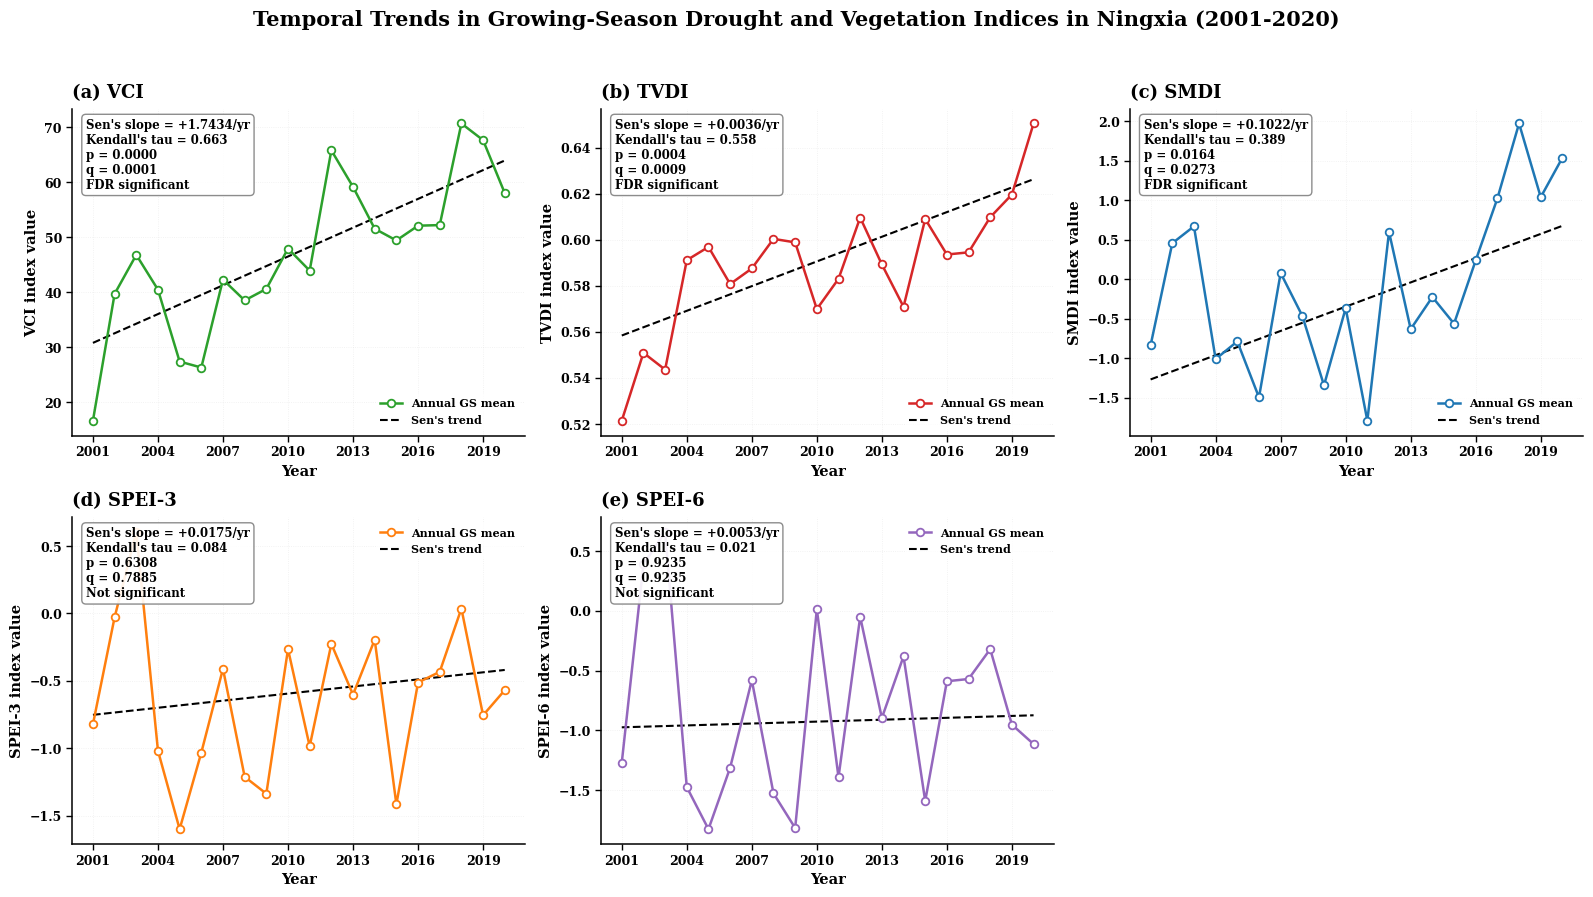


Regional summary saved:
E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Regional_Trend_Analysis_Summary_with_FDR.txt

##############################################################################
# PART B: SPATIAL PIXEL-WISE TREND ANALYSIS
##############################################################################

COMMON GRID
CRS: EPSG:4326
Resolution: 0.009
Dimensions: 396 x 476
Bounds: (104.20165081526194, 35.16337165300872, 107.76565081526194, 39.447371653008716)

PROCESSING: VCI

Preparing VCI
Available years: 20 | range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend: 100%|██████████████████████████████████████████████████████████████| 476/476 [00:35<00:00, 13.39it/s]



Summary: VCI
Index: VCI
Valid_Pixels: 66436
Mean_Sen_Slope: 1.869464415536176
Increasing_Area_Pct: 90.15194930591454
Decreasing_Area_Pct: 9.848050694085462
Raw_p_LT_0.05_Area_Pct: 72.04104801608214
FDR_Significant_Area_Pct: 69.50046197409455
FDR_Sig_Increasing_Area_Pct: 66.64057017157518
FDR_Sig_Decreasing_Area_Pct: 2.859891802519362
Median_Q_Value: 0.004677082411944866

PROCESSING: TVDI

Preparing TVDI
Available years: 20 | range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend: 100%|██████████████████████████████████████████████████████████████| 476/476 [00:34<00:00, 13.89it/s]



Summary: TVDI
Index: TVDI
Valid_Pixels: 66491
Mean_Sen_Slope: 0.0034957946702779694
Increasing_Area_Pct: 70.0308844862274
Decreasing_Area_Pct: 29.437230243144352
Raw_p_LT_0.05_Area_Pct: 40.36479455456505
FDR_Significant_Area_Pct: 27.75356628874398
FDR_Sig_Increasing_Area_Pct: 22.99690580471265
FDR_Sig_Decreasing_Area_Pct: 4.756660484031327
Median_Q_Value: 0.21304260194301605

PROCESSING: SMDI

Preparing SMDI
Available years: 20 | range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend: 100%|██████████████████████████████████████████████████████████████| 476/476 [00:34<00:00, 13.90it/s]



Summary: SMDI
Index: SMDI
Valid_Pixels: 66461
Mean_Sen_Slope: 0.09270691121506781
Increasing_Area_Pct: 99.17405792287893
Decreasing_Area_Pct: 0.8259420771210387
Raw_p_LT_0.05_Area_Pct: 49.5829541289997
FDR_Significant_Area_Pct: 12.41349147768368
FDR_Sig_Increasing_Area_Pct: 12.41349147768368
FDR_Sig_Decreasing_Area_Pct: 0.0
Median_Q_Value: 0.10625056177377701

PROCESSING: SPEI-3

Preparing SPEI-3
Available years: 20 | range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend: 100%|██████████████████████████████████████████████████████████████| 476/476 [00:35<00:00, 13.36it/s]



Summary: SPEI-3
Index: SPEI-3
Valid_Pixels: 66436
Mean_Sen_Slope: 0.013652206195590433
Increasing_Area_Pct: 96.74235146953716
Decreasing_Area_Pct: 3.2576485304628267
Raw_p_LT_0.05_Area_Pct: 0.0
FDR_Significant_Area_Pct: 0.0
FDR_Sig_Increasing_Area_Pct: 0.0
FDR_Sig_Decreasing_Area_Pct: 0.0
Median_Q_Value: 1.0

PROCESSING: SPEI-6

Preparing SPEI-6
Available years: 20 | range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend: 100%|██████████████████████████████████████████████████████████████| 476/476 [00:33<00:00, 14.29it/s]



Summary: SPEI-6
Index: SPEI-6
Valid_Pixels: 66436
Mean_Sen_Slope: 0.007822159925402184
Increasing_Area_Pct: 77.10440727540485
Decreasing_Area_Pct: 22.895592724595126
Raw_p_LT_0.05_Area_Pct: 0.0
FDR_Significant_Area_Pct: 0.0
FDR_Sig_Increasing_Area_Pct: 0.0
FDR_Sig_Decreasing_Area_Pct: 0.0
Median_Q_Value: 1.0


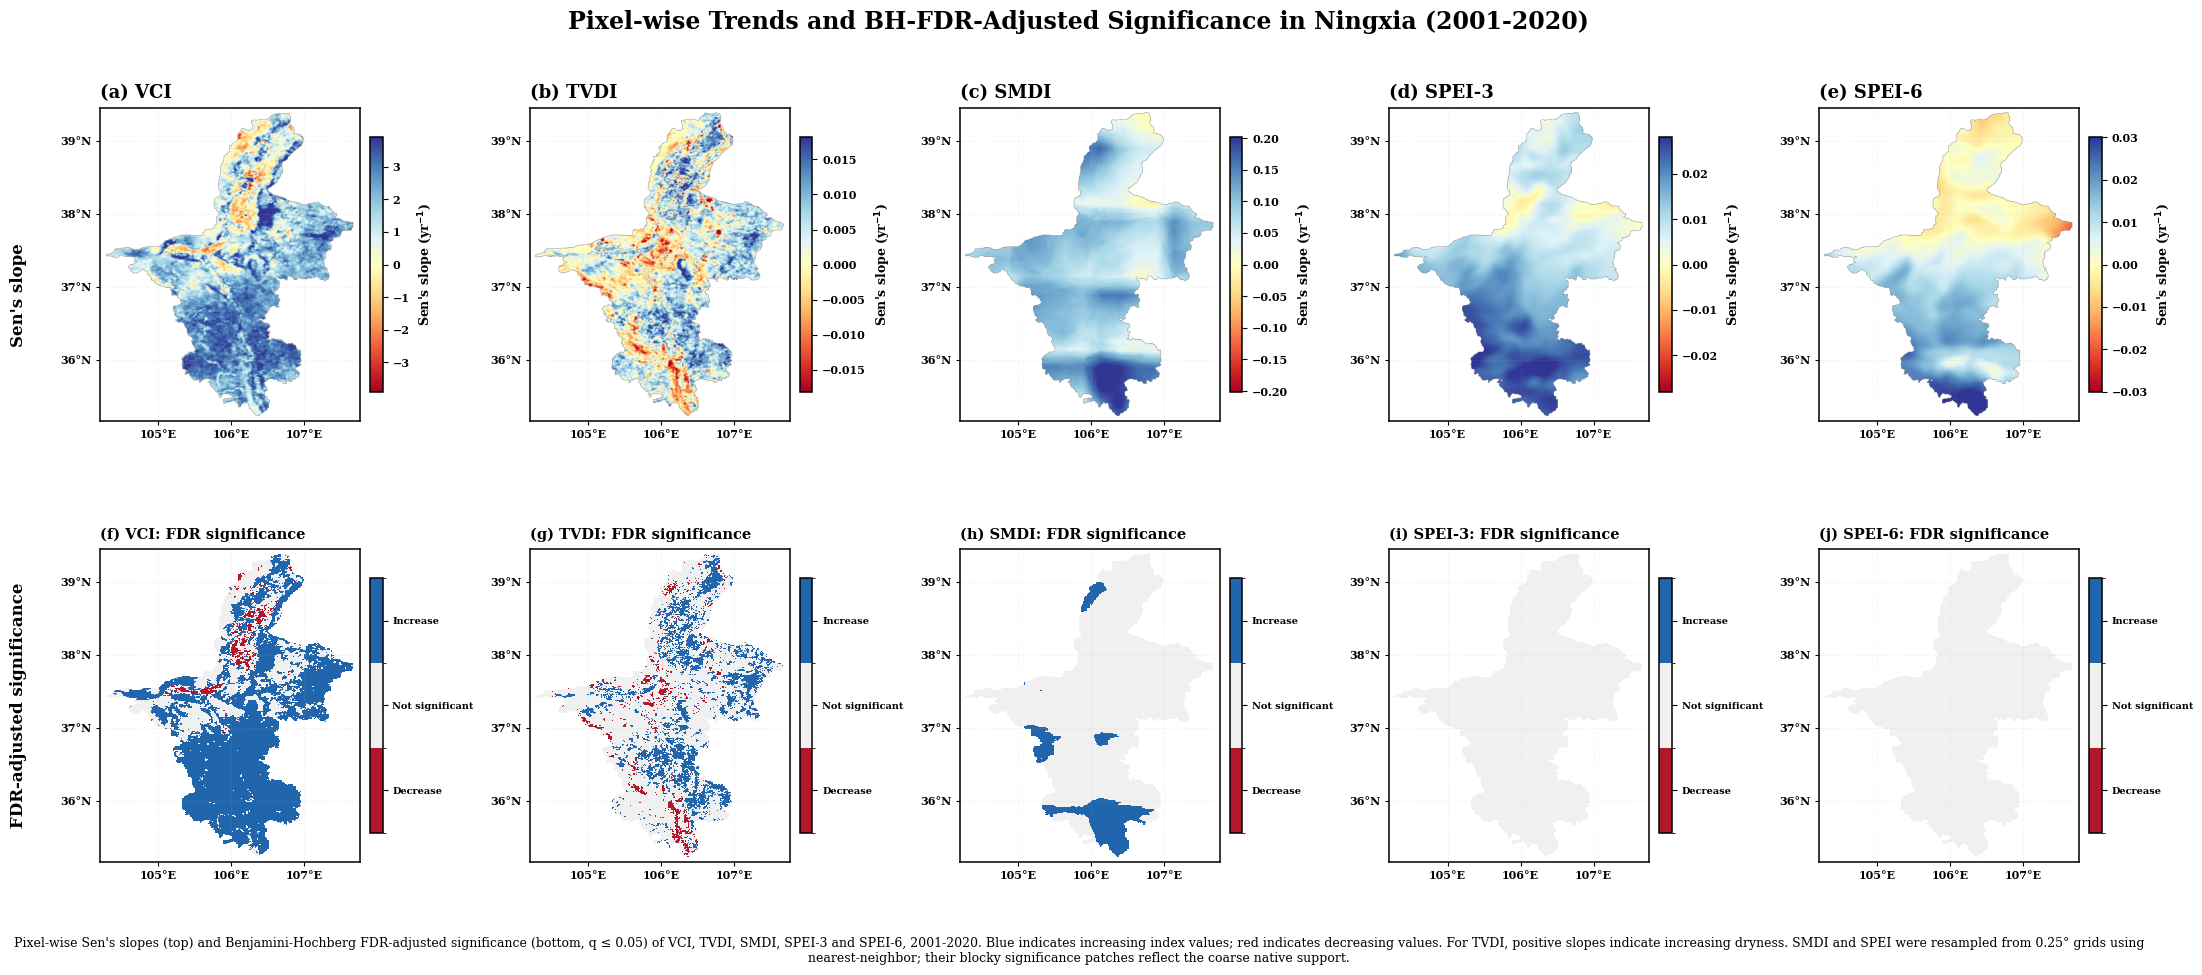


Figure saved: E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Spatio_pixelwise\Ningxia_Spatial_Trends_Sen_Slope_BH_FDR_FINAL.png

Spatial summary saved: E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Spatio_pixelwise\Ningxia_Spatio_Pixelwise_Trend_FDR_Summary.txt

COMBINED ANALYSIS COMPLETED

Output directory: E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined

Generated files:
  [Regional]   E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Ningxia_All_Indices_Timeseries_MK_Sen_FDR.png
  [Regional]   E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Annual_Growing_Season_Regional_Means.csv
  [Regional]   E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Regional_TimeSeries_MK_Sen_FDR_Results.csv
  [Regional]   E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Regional_Trend_Analysis_Summary_with_FDR.t

In [8]:
# =============================================================================
# COMBINED REGIONAL (TEMPORAL) + SPATIAL (PIXEL-WISE) TREND ANALYSIS
# Ningxia, China | 2001-2020 | Growing season April-October
# Indices: VCI, TVDI, SMDI, SPEI-3, SPEI-6
# Mann-Kendall + Sen's slope + Benjamini-Hochberg FDR (q <= 0.05)
# =============================================================================

import os
import re
import glob
import warnings

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.transform import from_origin

from scipy.ndimage import gaussian_filter
from scipy import stats
from scipy.stats import kendalltau, theilslopes
from matplotlib.colors import ListedColormap, BoundaryNorm
from tqdm import tqdm


# =============================================================================
# 1. PATHS AND GLOBAL SETTINGS
# =============================================================================

BASE_DIR = r"E:\2_Contribution\Final\Preprocess"

INDICES_DIRS = {
    "VCI":    os.path.join(BASE_DIR, "VCI"),
    "TVDI":   os.path.join(BASE_DIR, "TVDI"),
    "SMDI":   os.path.join(BASE_DIR, "SMDI"),
    "SPEI-3": os.path.join(BASE_DIR, "SPEI_3"),
    "SPEI-6": os.path.join(BASE_DIR, "SPEI_6"),
}

OUTPUT_DIR  = os.path.join(BASE_DIR, "3. Trend", "Update result", "with FDR", "Combined")
SPATIAL_DIR = os.path.join(OUTPUT_DIR, "Spatio_pixelwise")
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(SPATIAL_DIR, exist_ok=True)

START_YEAR = 2001
END_YEAR   = 2020
GROWING_MONTHS = [4, 5, 6, 7, 8, 9, 10]

REQUIRE_ALL_MONTHS = True
ALPHA = 0.05

# --- spatial settings --------------------------------------------------------
TARGET_CRS = "EPSG:4326"
TARGET_RES = 0.009

MIN_VALID_YEARS    = 15
MIN_VALID_FRACTION = 0.75

# Turned ON to make SPEI slope maps smooth as requested
SMOOTH_SPEI_FOR_DISPLAY = True
SPEI_DISPLAY_SIGMA      = 4.0

LON_INTERVAL = 1.0
LAT_INTERVAL = 1.0

# Coarse resolution indices (0.25 deg) to apply nearest-neighbor resampling
# This prevents artificial "circle" artifacts in the FDR significance maps
COARSE_INDICES = ["SMDI", "SPEI-3", "SPEI-6"]

INDEX_ORDER = ["VCI", "TVDI", "SMDI", "SPEI-3", "SPEI-6"]

INDEX_LABELS_TS = {
    "VCI": "(a) VCI", "TVDI": "(b) TVDI", "SMDI": "(c) SMDI",
    "SPEI-3": "(d) SPEI-3", "SPEI-6": "(e) SPEI-6",
}

INDEX_COLORS = {
    "VCI": "#2ca02c", "TVDI": "#d62728", "SMDI": "#1f77b4",
    "SPEI-3": "#ff7f0e", "SPEI-6": "#9467bd",
}

PANEL_TOP    = ["(a) VCI", "(b) TVDI", "(c) SMDI", "(d) SPEI-3", "(e) SPEI-6"]
PANEL_BOTTOM = ["(f) VCI", "(g) TVDI", "(h) SMDI", "(i) SPEI-3", "(j) SPEI-6"]


# =============================================================================
# 2. FIGURE STYLE
# =============================================================================

plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "axes.edgecolor": "black",
    "axes.linewidth": 1.1,
    "axes.labelcolor": "black", "text.color": "black", "axes.titlecolor": "black",
    "xtick.color": "black", "ytick.color": "black",
    "font.family": "serif", "font.size": 9, "font.weight": "bold",
    "axes.labelweight": "bold", "axes.titleweight": "bold",
    "savefig.dpi": 400,
})


def longitude_formatter(value, position):
    return f"{abs(value):.0f}\u00b0{'E' if value >= 0 else 'W'}"


def latitude_formatter(value, position):
    return f"{abs(value):.0f}\u00b0{'N' if value >= 0 else 'S'}"


# =============================================================================
# 3. BENJAMINI-HOCHBERG FDR
# =============================================================================

def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=np.float64)
    adjusted = np.full(p_values.shape, np.nan, dtype=np.float64)
    valid = np.isfinite(p_values)
    p = p_values[valid]
    if p.size == 0:
        return adjusted
    m = len(p)
    order = np.argsort(p)
    sorted_p = p[order]
    ranks = np.arange(1, m + 1, dtype=np.float64)
    q = sorted_p * m / ranks
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)
    restored = np.empty(m, dtype=np.float64)
    restored[order] = q
    adjusted[valid] = restored
    return adjusted


# =============================================================================
# 4. RASTER DISCOVERY / READING
# =============================================================================

def find_monthly_files(input_dir):
    files = glob.glob(os.path.join(input_dir, "*.tif"))
    monthly = {}
    for fp in files:
        filename = os.path.basename(fp)
        m = re.search(r"(20\d{2})[_-]?(\d{2})\.tif$", filename, flags=re.IGNORECASE)
        if not m:
            continue
        year, month = int(m.group(1)), int(m.group(2))
        if START_YEAR <= year <= END_YEAR and month in GROWING_MONTHS:
            key = (year, month)
            if key in monthly:
                raise ValueError(f"Duplicate monthly raster for {key}:\n"
                                 f"{monthly[key]}\n{fp}")
            monthly[key] = fp
    return monthly


def find_annual_tvdi_files(folder):
    candidate_dirs = [
        os.path.join(folder, "annaul"),
        os.path.join(folder, "annual"),
        os.path.join(folder, "Annual"),
        os.path.join(folder, "Annual_GS"),
        folder,
    ]
    annual_files = {}
    for candidate in candidate_dirs:
        if not os.path.isdir(candidate):
            continue
        for fp in glob.glob(os.path.join(candidate, "*.tif")):
            filename = os.path.basename(fp)
            m = re.search(r"TVDI_Ningxia_GS_(\d{4})\.tif$", filename, flags=re.IGNORECASE)
            if not m:
                m = re.search(r"(\d{4})\.tif$", filename, flags=re.IGNORECASE)
            if not m:
                continue
            year = int(m.group(1))
            if START_YEAR <= year <= END_YEAR and year not in annual_files:
                annual_files[year] = fp
    return annual_files


def read_raster(fp):
    with rasterio.open(fp) as src:
        data = src.read(1, masked=True).astype(np.float32).filled(np.nan)
        profile = {
            "crs": src.crs, "transform": src.transform,
            "width": src.width, "height": src.height, "nodata": src.nodata,
        }
    data[~np.isfinite(data)] = np.nan
    return data, profile


def check_same_grid(reference, current, filename):
    same = (
        reference["crs"] == current["crs"]
        and reference["transform"] == current["transform"]
        and reference["width"] == current["width"]
        and reference["height"] == current["height"]
    )
    if not same:
        raise ValueError(f"Raster grid mismatch detected:\n{filename}\n"
                         "Please align the raster grids before running this analysis.")


ANNUAL_TVDI_FILES = find_annual_tvdi_files(INDICES_DIRS["TVDI"])
if not ANNUAL_TVDI_FILES:
    warnings.warn("No annual TVDI rasters found - TVDI will be skipped.")


# =============================================================================
# PART A. REGIONAL TEMPORAL TRENDS
# =============================================================================

print("\n" + "#" * 78)
print("# PART A: REGIONAL TEMPORAL TREND ANALYSIS")
print("#" * 78)

annual_data = {}
annual_file_counts = {}

for index_name in INDEX_ORDER:

    input_dir = INDICES_DIRS[index_name]
    print("\n" + "=" * 70)
    print(f"Processing {index_name}")
    print(f"Input directory: {input_dir}")
    print("=" * 70)

    if not os.path.isdir(input_dir):
        warnings.warn(f"Directory not found for {index_name}: {input_dir}")
        continue

    annual_means = {}
    annual_counts = {}

    if index_name == "TVDI":
        if not ANNUAL_TVDI_FILES:
            continue
        for year in range(START_YEAR, END_YEAR + 1):
            if year not in ANNUAL_TVDI_FILES:
                print(f"  Missing TVDI annual raster: {year}")
                continue
            arr, _ = read_raster(ANNUAL_TVDI_FILES[year])
            arr[(arr < 0) | (arr > 1)] = np.nan
            if np.isfinite(arr).any():
                annual_means[year] = float(np.nanmean(arr))
                annual_counts[year] = 1
                print(f"  {year}: regional mean = {annual_means[year]:.5f}")
    else:
        monthly_files = find_monthly_files(input_dir)
        for year in range(START_YEAR, END_YEAR + 1):
            available_months = [m for m in GROWING_MONTHS if (year, m) in monthly_files]
            if REQUIRE_ALL_MONTHS and len(available_months) != 7:
                print(f"  Excluding {year}: only {len(available_months)}/7 months available")
                continue
            if len(available_months) == 0:
                print(f"  Excluding {year}: no monthly files available")
                continue

            arrays = []
            reference_profile = None
            for month in available_months:
                fp = monthly_files[(year, month)]
                arr, profile = read_raster(fp)
                if reference_profile is None:
                    reference_profile = profile
                else:
                    check_same_grid(reference_profile, profile, fp)
                arrays.append(arr)

            monthly_stack = np.stack(arrays, axis=0)

            if REQUIRE_ALL_MONTHS:
                valid_count = np.sum(np.isfinite(monthly_stack), axis=0)
                annual_raster = np.full(monthly_stack.shape[1:], np.nan, dtype=np.float32)
                valid_pixels = valid_count == 7
                annual_raster[valid_pixels] = np.nanmean(monthly_stack[:, valid_pixels], axis=0)
            else:
                annual_raster = np.nanmean(monthly_stack, axis=0)

            if not np.isfinite(annual_raster).any():
                print(f"  Excluding {year}: no valid annual pixels")
                continue

            regional_mean = float(np.nanmean(annual_raster))
            annual_means[year] = regional_mean
            annual_counts[year] = len(available_months)
            print(f"  {year}: {len(available_months)}/7 months; regional mean = {regional_mean:.5f}")

    if annual_means:
        sorted_years = sorted(annual_means.keys())
        annual_data[index_name] = {
            "years": np.array(sorted_years, dtype=int),
            "means": np.array([annual_means[y] for y in sorted_years], dtype=float),
        }
        annual_file_counts[index_name] = annual_counts
    else:
        print(f"WARNING: No usable annual data for {index_name}")


# --- 5. Save annual regional means ------------------------------------------
annual_records = []
for index_name, data in annual_data.items():
    for year, value in zip(data["years"], data["means"]):
        annual_records.append({"Index": index_name, "Year": int(year),
                               "Growing_Season_Mean": float(value)})

annual_df = pd.DataFrame(annual_records)
annual_csv = os.path.join(OUTPUT_DIR, "Annual_Growing_Season_Regional_Means.csv")
annual_df.to_csv(annual_csv, index=False, float_format="%.8f")
print(f"\nAnnual regional mean data saved:\n{annual_csv}")


# --- 6. Mann-Kendall + Sen's slope (regional) -------------------------------
trend_results = {}
for index_name in INDEX_ORDER:
    if index_name not in annual_data:
        continue
    years = annual_data[index_name]["years"]
    values = annual_data[index_name]["means"]
    valid = np.isfinite(years) & np.isfinite(values)
    years, values = years[valid], values[valid]
    if len(values) < 3:
        print(f"Insufficient observations for {index_name}")
        continue

    mk = stats.kendalltau(years, values, alternative="two-sided", method="auto")
    sen = stats.theilslopes(values, years, alpha=0.95, method="separate")

    trend_results[index_name] = {
        "n": len(values), "start_year": int(years.min()), "end_year": int(years.max()),
        "tau": float(mk.statistic),
        "sen_slope": float(sen.slope), "sen_intercept": float(sen.intercept),
        "low_slope": float(sen.low_slope), "high_slope": float(sen.high_slope),
        "p_raw": float(mk.pvalue), "years": years, "values": values,
    }


# --- 7. BH-FDR across the five regional tests -------------------------------
available_indices = list(trend_results.keys())
raw_p_values = [trend_results[n]["p_raw"] for n in available_indices]
adjusted_q = benjamini_hochberg(raw_p_values)

for name, q_value in zip(available_indices, adjusted_q):
    trend_results[name]["p_fdr"] = float(q_value)
    trend_results[name]["fdr_significant"] = bool(q_value < ALPHA)
    slope = trend_results[name]["sen_slope"]
    if q_value < ALPHA:
        trend_results[name]["fdr_direction"] = (
            "Significant increase" if slope > 0 else
            "Significant decrease" if slope < 0 else "No directional trend")
    else:
        trend_results[name]["fdr_direction"] = "Not significant"


# --- 8. Save regional table --------------------------------------------------
result_records = []
for name in INDEX_ORDER:
    if name not in trend_results:
        continue
    r = trend_results[name]
    result_records.append({
        "Index": name, "Number_of_Years": r["n"],
        "Start_Year": r["start_year"], "End_Year": r["end_year"],
        "Kendall_Tau": r["tau"], "Sen_Slope_per_Year": r["sen_slope"],
        "Sen_Slope_CI_Lower": r["low_slope"], "Sen_Slope_CI_Upper": r["high_slope"],
        "Original_MK_p_value": r["p_raw"],
        "BH_FDR_adjusted_p_value": r["p_fdr"],
        "FDR_Significant": r["fdr_significant"],
        "Trend_Direction": r["fdr_direction"],
    })
results_df = pd.DataFrame(result_records)
results_csv = os.path.join(OUTPUT_DIR, "Regional_TimeSeries_MK_Sen_FDR_Results.csv")
results_df.to_csv(results_csv, index=False, float_format="%.8f")


# --- 9. Regional time-series figure -----------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9), facecolor="white")
axes = axes.flatten()

for idx, index_name in enumerate(INDEX_ORDER):
    ax = axes[idx]
    if index_name not in trend_results:
        ax.axis("off")
        continue
    r = trend_results[index_name]
    years, values = r["years"], r["values"]
    fitted = r["sen_slope"] * years + r["sen_intercept"]

    ax.plot(years, values, marker="o", color=INDEX_COLORS[index_name],
            linewidth=1.8, markersize=5.5, markerfacecolor="white",
            markeredgewidth=1.3, label="Annual GS mean", zorder=3)
    ax.plot(years, fitted, linestyle="--", color="black",
            linewidth=1.5, label="Sen's trend", zorder=2)

    sig_label = "FDR significant" if r["p_fdr"] < ALPHA else "Not significant"
    annotation = (f"Sen's slope = {r['sen_slope']:+.4f}/yr\n"
                  f"Kendall's tau = {r['tau']:.3f}\n"
                  f"p = {r['p_raw']:.4f}\nq = {r['p_fdr']:.4f}\n{sig_label}")
    ax.text(0.03, 0.97, annotation, transform=ax.transAxes, va="top", ha="left",
            fontsize=8.5,
            bbox={"boxstyle": "round,pad=0.35", "facecolor": "white",
                  "edgecolor": "gray", "alpha": 0.9})

    ax.set_title(INDEX_LABELS_TS[index_name], fontsize=13, fontweight="bold",
                 loc="left", pad=8)
    ax.set_xlabel("Year", fontsize=10.5, fontweight="bold")
    ax.set_ylabel(f"{index_name} index value", fontsize=10.5, fontweight="bold")
    ax.set_xticks(np.arange(START_YEAR, END_YEAR + 1, 3))
    ax.tick_params(axis="both", labelsize=9, width=1.0, length=4)
    ax.grid(alpha=0.20, linestyle=":", linewidth=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=True, facecolor="white", edgecolor="none",
              fontsize=8, loc="best")

axes[5].axis("off")
fig.suptitle("Temporal Trends in Growing-Season Drought and Vegetation Indices "
             "in Ningxia (2001-2020)",
             fontsize=15, fontweight="bold", y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.96])
ts_figure = os.path.join(OUTPUT_DIR, "Ningxia_All_Indices_Timeseries_MK_Sen_FDR.png")
plt.savefig(ts_figure, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()


# --- 10. Regional summary text ----------------------------------------------
summary_ts_path = os.path.join(OUTPUT_DIR, "Regional_Trend_Analysis_Summary_with_FDR.txt")
with open(summary_ts_path, "w", encoding="utf-8") as f:
    f.write("=" * 90 + "\n")
    f.write("REGIONAL TEMPORAL TREND ANALYSIS: NINGXIA, CHINA\n")
    f.write("=" * 90 + "\n\n")
    f.write("Study period: 2001-2020\nGrowing season: April-October\n")
    f.write("Indices: VCI, TVDI, SMDI, SPEI-3, SPEI-6\n\n")
    f.write("ANALYTICAL PROCEDURE\n" + "-" * 90 + "\n")
    f.write("1. Monthly raster data were aggregated into annual April-October growing-season means.\n")
    f.write("2. For monthly indices, annual growing-season values were calculated pixel by pixel before computing the regional mean.\n")
    f.write("3. Only years with all seven growing-season monthly rasters were retained.\n")
    f.write("4. TVDI was analysed using the existing annual growing-season rasters (TVDI_Ningxia_GS_YYYY.tif), clipped to [0, 1].\n")
    f.write("5. Monotonic temporal trends were evaluated using Kendall's tau (two-sided Mann-Kendall test).\n")
    f.write("6. Trend magnitude was estimated using Sen's slope in index units per year.\n")
    f.write("7. Benjamini-Hochberg FDR correction was applied across the available regional index-level p-values (one family of tests).\n\n")
    f.write("STATISTICAL RESULTS\n" + "-" * 90 + "\n\n")
    f.write(f"{'Index':<10}{'N':>5}{'Tau':>11}{'Sen slope/yr':>16}"
            f"{'Raw p':>13}{'FDR q':>13}{'FDR result':>22}\n")
    f.write("-" * 90 + "\n")
    for name in INDEX_ORDER:
        if name not in trend_results:
            f.write(f"{name:<10} No valid data available\n"); continue
        r = trend_results[name]
        f.write(f"{name:<10}{r['n']:>5d}{r['tau']:>11.4f}{r['sen_slope']:>16.6f}"
                f"{r['p_raw']:>13.6f}{r['p_fdr']:>13.6f}{r['fdr_direction']:>22}\n")
    f.write("\n" + "=" * 90 + "\nINTERPRETATION AND STATISTICAL NOTES\n" + "=" * 90 + "\n\n")
    f.write("A positive Sen's slope indicates an increasing index value over time, whereas a "
            "negative slope indicates a decreasing index value. The ecological or drought "
            "interpretation depends on the index definition (for TVDI, a positive slope "
            "indicates increasing dryness).\n\n")
    f.write("Original p-values are reported alongside BH-FDR adjusted q-values. Regional "
            "index-level statistical significance is determined using q < 0.05.\n\n")
    f.write("The BH correction in this file applies only to the regional time-series tests for "
            "the available indices. It does not replace the separate pixel-wise BH-FDR "
            "correction required for spatial trend maps.\n\n")
    f.write("The Mann-Kendall test evaluates monotonic association with time. Serial "
            "autocorrelation can affect its nominal significance; this analysis does not "
            "apply a separate autocorrelation correction.\n\n")
    f.write("The regional mean is calculated as an unweighted mean of valid raster pixels. "
            "It is not an area-weighted regional estimate. If the raster is in geographic "
            "coordinates, pixel areas vary with latitude.\n\n")
    f.write("The reported results describe regional index behaviour and should not be "
            "interpreted as independent ground validation of the underlying drought products.\n")
    f.write("\n" + "=" * 90 + "\nEND OF SUMMARY\n" + "=" * 90 + "\n")
print(f"\nRegional summary saved:\n{summary_ts_path}")


# =============================================================================
# PART B. SPATIAL PIXEL-WISE TRENDS
# =============================================================================

print("\n" + "#" * 78)
print("# PART B: SPATIAL PIXEL-WISE TREND ANALYSIS")
print("#" * 78)


# --- 11. Common reference grid ----------------------------------------------
def create_reference_grid(vci_folder):
    vci_files = find_monthly_files(vci_folder)
    if not vci_files:
        raise FileNotFoundError("Monthly VCI files were not found.")

    first_key = min(vci_files.keys())
    first_fp = vci_files[first_key]

    with rasterio.open(first_fp) as src:
        source_crs = src.crs if src.crs else TARGET_CRS
        left, bottom, right, top = transform_bounds(
            source_crs, TARGET_CRS, *src.bounds, densify_pts=21)

    left -= 0.05; right += 0.05; bottom -= 0.05; top += 0.05
    width  = int(np.ceil((right - left) / TARGET_RES))
    height = int(np.ceil((top - bottom) / TARGET_RES))

    transform = from_origin(left, top, TARGET_RES, TARGET_RES)
    actual_right  = left + width * TARGET_RES
    actual_bottom = top - height * TARGET_RES
    bounds = (left, actual_bottom, actual_right, top)

    print("\nCOMMON GRID")
    print("CRS:", TARGET_CRS)
    print("Resolution:", TARGET_RES)
    print("Dimensions:", width, "x", height)
    print("Bounds:", bounds)
    return transform, width, height, bounds


# --- 12. Reproject ----------------------------------------------------------
def load_and_reproject(filepath, ref_transform, ref_width, ref_height, resampling_method):
    with rasterio.open(filepath) as src:
        source = src.read(1).astype(np.float32)
        if src.nodata is not None:
            source[source == src.nodata] = np.nan
        source[~np.isfinite(source)] = np.nan

        source_crs = src.crs if src.crs else TARGET_CRS
        destination = np.full((ref_height, ref_width), np.nan, dtype=np.float32)

        reproject(
            source=source, destination=destination,
            src_transform=src.transform, src_crs=source_crs,
            src_nodata=np.nan,
            dst_transform=ref_transform, dst_crs=TARGET_CRS,
            dst_nodata=np.nan,
            resampling=resampling_method,
        )
    return destination


# --- 13. Build annual stack -------------------------------------------------
def build_annual_stack(index_name, input_folder,
                       ref_transform, ref_width, ref_height):
    print(f"\nPreparing {index_name}")
    annual_data_stack = {}
    missing_years = []
    
    # Use Nearest Neighbor for coarse indices to avoid fake circular artifacts
    resample_method = Resampling.nearest if index_name in COARSE_INDICES else Resampling.bilinear

    if index_name == "TVDI":
        for year in range(START_YEAR, END_YEAR + 1):
            if year not in ANNUAL_TVDI_FILES:
                missing_years.append(year)
                continue
            arr = load_and_reproject(ANNUAL_TVDI_FILES[year],
                                     ref_transform, ref_width, ref_height,
                                     resample_method)
            arr[(arr < 0) | (arr > 1)] = np.nan
            annual_data_stack[year] = arr
    else:
        monthly_files = find_monthly_files(input_folder)
        for year in range(START_YEAR, END_YEAR + 1):
            month_dict = {
                m: monthly_files[(year, m)]
                for m in GROWING_MONTHS
                if (year, m) in monthly_files
            }
            available_months = sorted(month_dict.keys())

            if REQUIRE_ALL_MONTHS:
                if not all(m in available_months for m in GROWING_MONTHS):
                    missing_years.append(year); continue
            elif len(available_months) == 0:
                missing_years.append(year); continue

            selected = [month_dict[m] for m in GROWING_MONTHS if m in month_dict]
            arrays = [load_and_reproject(fp, ref_transform, ref_width, ref_height,
                                         resample_method)
                      for fp in selected]
            monthly_stack = np.stack(arrays, axis=0)

            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                annual_mean = np.nanmean(monthly_stack, axis=0)

            if REQUIRE_ALL_MONTHS:
                valid_month_count = np.sum(np.isfinite(monthly_stack), axis=0)
                annual_mean[valid_month_count != len(GROWING_MONTHS)] = np.nan

            annual_data_stack[year] = annual_mean

    years = sorted(annual_data_stack.keys())
    if len(years) < MIN_VALID_YEARS:
        raise ValueError(f"{index_name}: only {len(years)} valid years; "
                         f"minimum required {MIN_VALID_YEARS}.")

    stack = np.stack([annual_data_stack[y] for y in years], axis=0)
    print("Available years:", len(years), "| range:", years[0], "-", years[-1])
    if missing_years:
        print("Missing years:", missing_years)
    return np.asarray(years, dtype=np.float64), stack


# --- 14. Pixel-wise Mann-Kendall + Sen's slope ------------------------------
def calculate_pixelwise_trends(years, stack):
    n_years, height, width = stack.shape
    slope_map  = np.full((height, width), np.nan, dtype=np.float32)
    pvalue_map = np.full((height, width), np.nan, dtype=np.float32)

    required_valid = max(MIN_VALID_YEARS,
                         int(np.ceil(n_years * MIN_VALID_FRACTION)))
    print("Minimum valid observations per pixel:", required_valid)

    for row in tqdm(range(height), desc="Pixel-wise trend"):
        for col in range(width):
            values = stack[:, row, col]
            valid = np.isfinite(values)
            if np.sum(valid) < required_valid:
                continue
            vy, vv = years[valid], values[valid]
            try:
                _, p_value = kendalltau(vy, vv)
                if not np.isfinite(p_value):
                    continue
                pvalue_map[row, col] = p_value
                slope = theilslopes(vv, vy).slope
                if np.isfinite(slope):
                    slope_map[row, col] = slope
            except Exception:
                continue
    return slope_map, pvalue_map


# --- 15. Pixel-wise BH-FDR --------------------------------------------------
def apply_pixelwise_fdr(slope_map, pvalue_map):
    valid = np.isfinite(slope_map) & np.isfinite(pvalue_map)
    qvalue_map = np.full(pvalue_map.shape, np.nan, dtype=np.float32)
    qvalue_map[valid] = benjamini_hochberg(pvalue_map[valid]).astype(np.float32)

    significance_map = np.full(slope_map.shape, np.nan, dtype=np.float32)
    significance_map[valid] = 0
    significant = valid & (qvalue_map <= ALPHA)
    significance_map[significant & (slope_map > 0)] = 1
    significance_map[significant & (slope_map < 0)] = -1
    return qvalue_map, significance_map


# --- 16. Display-only smoothing (kept, default OFF) -------------------------
def smooth_for_display(array, sigma):
    valid = np.isfinite(array)
    if not np.any(valid):
        return array.copy()
    values = np.where(valid, array, 0.0)
    weights = valid.astype(np.float32)
    numerator   = gaussian_filter(values,  sigma=sigma, mode="nearest")
    denominator = gaussian_filter(weights, sigma=sigma, mode="nearest")
    result = np.full(array.shape, np.nan, dtype=np.float32)
    good = denominator > 1e-6
    result[good] = numerator[good] / denominator[good]
    result[~valid] = np.nan
    return result


# --- 17. Area-weighted summary (with RAW p column) --------------------------
def calculate_summary(index_name, slope_map, pvalue_map,
                      qvalue_map, significance_map, bounds):
    valid = np.isfinite(slope_map) & np.isfinite(qvalue_map)
    if not np.any(valid):
        return None

    slopes   = slope_map[valid]
    q_values = qvalue_map[valid]
    p_values = pvalue_map[valid]

    top = bounds[3]
    height = slope_map.shape[0]
    latitudes = top - (np.arange(height) + 0.5) * TARGET_RES
    row_weights = np.cos(np.deg2rad(latitudes))
    weights = np.broadcast_to(row_weights[:, None], slope_map.shape)[valid]
    total_weight = np.sum(weights)

    mean_slope = np.sum(slopes * weights) / total_weight

    significant     = q_values <= ALPHA
    raw_significant = p_values <  ALPHA
    increasing = slopes > 0
    decreasing = slopes < 0

    def wpct(mask):
        return float(100 * np.sum(weights[mask]) / total_weight)

    return {
        "Index": index_name,
        "Valid_Pixels": int(np.sum(valid)),
        "Mean_Sen_Slope": float(mean_slope),
        "Increasing_Area_Pct": wpct(increasing),
        "Decreasing_Area_Pct": wpct(decreasing),
        "Raw_p_LT_0.05_Area_Pct": wpct(raw_significant),
        "FDR_Significant_Area_Pct": wpct(significant),
        "FDR_Sig_Increasing_Area_Pct": wpct(significant & increasing),
        "FDR_Sig_Decreasing_Area_Pct": wpct(significant & decreasing),
        "Median_Q_Value": float(np.nanmedian(q_values)),
    }


# --- 18. GeoTIFF writer -----------------------------------------------------
def save_geotiff(filepath, array, ref_transform, ref_width, ref_height):
    nodata = -9999.0
    output_array = np.where(np.isfinite(array), array, nodata).astype(np.float32)
    profile = {
        "driver": "GTiff", "height": ref_height, "width": ref_width,
        "count": 1, "dtype": "float32", "crs": TARGET_CRS,
        "transform": ref_transform, "nodata": nodata, "compress": "lzw",
    }
    with rasterio.open(filepath, "w", **profile) as dst:
        dst.write(output_array, 1)


# --- 19. Run spatial processing ---------------------------------------------
ref_transform, ref_width, ref_height, bounds = create_reference_grid(INDICES_DIRS["VCI"])

spatial_results = {}
spatial_summary = []

for index_name, input_folder in INDICES_DIRS.items():
    print("\n" + "=" * 70)
    print("PROCESSING:", index_name)
    print("=" * 70)

    if index_name == "TVDI" and not ANNUAL_TVDI_FILES:
        print("No annual TVDI rasters available - skipping TVDI.")
        continue

    years, stack = build_annual_stack(index_name, input_folder,
                                      ref_transform, ref_width, ref_height)
    slope_map, pvalue_map     = calculate_pixelwise_trends(years, stack)
    qvalue_map, significance_map = apply_pixelwise_fdr(slope_map, pvalue_map)

    summary = calculate_summary(index_name, slope_map, pvalue_map,
                                qvalue_map, significance_map, bounds)
    if summary is None:
        print("No valid pixels:", index_name); continue

    spatial_results[index_name] = {
        "slope": slope_map, "pvalue": pvalue_map,
        "qvalue": qvalue_map, "significance": significance_map,
    }
    spatial_summary.append(summary)

    save_geotiff(os.path.join(SPATIAL_DIR, f"{index_name}_Sen_Slope.tif"),
                 slope_map, ref_transform, ref_width, ref_height)
    save_geotiff(os.path.join(SPATIAL_DIR, f"{index_name}_FDR_qvalue.tif"),
                 qvalue_map, ref_transform, ref_width, ref_height)
    save_geotiff(os.path.join(SPATIAL_DIR, f"{index_name}_FDR_Significance.tif"),
                 significance_map, ref_transform, ref_width, ref_height)

    print("\nSummary:", index_name)
    for k, v in summary.items():
        print(f"{k}: {v}")


# --- 20. Spatial figure -----------------------------------------------------
left, bottom, right, top = bounds
extent = [left, right, bottom, top]

sig_cmap = ListedColormap(["#B2182B", "#F0F0F0", "#2166AC"])
sig_norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], sig_cmap.N)

fig, axes = plt.subplots(2, 5, figsize=(22, 10), facecolor="white")
fig.subplots_adjust(left=0.055, right=0.965, bottom=0.10, top=0.88,
                    wspace=0.52, hspace=0.30)

for col, index_name in enumerate(INDEX_ORDER):
    ax_slope = axes[0, col]
    ax_sig   = axes[1, col]

    if index_name not in spatial_results:
        ax_slope.axis("off"); ax_sig.axis("off"); continue

    slope_map        = spatial_results[index_name]["slope"]
    significance_map = spatial_results[index_name]["significance"]

    display_slope = slope_map.copy()
    if index_name in ("SPEI-3", "SPEI-6") and SMOOTH_SPEI_FOR_DISPLAY:
        display_slope = smooth_for_display(slope_map, sigma=SPEI_DISPLAY_SIGMA)

    valid_values = display_slope[np.isfinite(display_slope)]
    if valid_values.size == 0:
        ax_slope.axis("off"); ax_sig.axis("off"); continue

    max_abs = np.nanpercentile(np.abs(valid_values), 98)
    if not np.isfinite(max_abs) or max_abs == 0:
        max_abs = 0.05

    im1 = ax_slope.imshow(display_slope, cmap="RdYlBu",
                          vmin=-max_abs, vmax=max_abs,
                          extent=extent, origin="upper",
                          interpolation="bilinear", aspect="equal")
    ax_slope.set_title(PANEL_TOP[col], fontsize=13, fontweight="bold",
                       loc="left", pad=7)
    cb1 = fig.colorbar(im1, ax=ax_slope, orientation="vertical",
                       fraction=0.045, pad=0.035, shrink=0.88)
    cb1.set_label("Sen's slope (yr$^{-1}$)", fontsize=9,
                  fontweight="bold", labelpad=5)
    cb1.ax.tick_params(labelsize=8)

    # Use 'nearest' interpolation for significance map to keep grid cells crisp
    im2 = ax_sig.imshow(significance_map, cmap=sig_cmap, norm=sig_norm,
                        extent=extent, origin="upper",
                        interpolation="nearest", aspect="equal")
    ax_sig.set_title(PANEL_BOTTOM[col] + ": FDR significance",
                     fontsize=10.5, fontweight="bold", loc="left", pad=7)
    cb2 = fig.colorbar(im2, ax=ax_sig, orientation="vertical",
                       fraction=0.045, pad=0.035, shrink=0.88,
                       ticks=[-1, 0, 1])
    cb2.ax.set_yticklabels(["Decrease", "Not significant", "Increase"])
    cb2.ax.tick_params(labelsize=7)

    for ax in (ax_slope, ax_sig):
        ax.set_xlim(left, right); ax.set_ylim(bottom, top)
        ax.xaxis.set_major_locator(mticker.MultipleLocator(LON_INTERVAL))
        ax.yaxis.set_major_locator(mticker.MultipleLocator(LAT_INTERVAL))
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(longitude_formatter))
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(latitude_formatter))
        ax.tick_params(axis="both", which="major", labelsize=8,
                       width=0.8, length=3, pad=3)
        ax.grid(visible=True, linestyle=":", linewidth=0.45, alpha=0.35)
        for lbl in (ax.get_xticklabels() + ax.get_yticklabels()):
            lbl.set_fontweight("bold")
        ax.set_aspect("equal", adjustable="box")

fig.text(0.018, 0.68, "Sen's slope", rotation=90, va="center", ha="center",
         fontsize=12, fontweight="bold")
fig.text(0.018, 0.27, "FDR-adjusted significance", rotation=90,
         va="center", ha="center", fontsize=12, fontweight="bold")

fig.suptitle("Pixel-wise Trends and BH-FDR-Adjusted Significance in Ningxia "
             "(2001-2020)",
             fontsize=17, fontweight="bold", y=0.965)

fig.text(
    0.5, 0.015,
    "Pixel-wise Sen's slopes (top) and Benjamini-Hochberg FDR-adjusted significance "
    "(bottom, q \u2264 0.05) of VCI, TVDI, SMDI, SPEI-3 and SPEI-6, 2001-2020. "
    "Blue indicates increasing index values; red indicates decreasing values. "
    "For TVDI, positive slopes indicate increasing dryness. "
    "SMDI and SPEI were resampled from 0.25\u00b0 grids using nearest-neighbor; "
    "their blocky significance patches reflect the coarse native support.",
    ha="center", fontsize=9, fontweight="normal", wrap=True)

spatial_figure = os.path.join(
    SPATIAL_DIR, "Ningxia_Spatial_Trends_Sen_Slope_BH_FDR_FINAL.png")
plt.savefig(spatial_figure, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()
print("\nFigure saved:", spatial_figure)


# --- 21. Spatial summary text ----------------------------------------------
summary_sp_path = os.path.join(
    SPATIAL_DIR, "Ningxia_Spatio_Pixelwise_Trend_FDR_Summary.txt")

with open(summary_sp_path, "w", encoding="utf-8") as file:
    file.write("=" * 130 + "\n")
    file.write("SPATIAL PIXEL-WISE TREND ANALYSIS AND BH-FDR SUMMARY\n")
    file.write("Ningxia, China | 2001-2020 | April-October\n")
    file.write("=" * 130 + "\n\n")

    file.write("METHODOLOGY\n" + "-" * 130 + "\n")
    file.write("Annual growing-season means were calculated from April to October. "
               "Pixel-wise trends were evaluated using the Mann-Kendall test, and "
               "trend magnitudes were estimated using Sen's slope.\n\n")
    file.write("Benjamini-Hochberg false discovery rate correction was applied "
               "separately to valid pixel-wise p-values for each index. Significance "
               "was determined using q <= 0.05. Raw p < 0.05 shares are reported "
               "from the same run.\n\n")
    file.write(f"Minimum valid observations: {MIN_VALID_YEARS} years, and "
               f"{MIN_VALID_FRACTION*100:.0f}% of available years.\n\n")
    file.write("All percentages are cos(latitude)-weighted shares of valid area "
               "(\"% of area\"), not raw pixel counts. Pixel counts differ by index "
               "because each index has its own valid-pixel mask, and they differ "
               "from the Chapter 3 pixel set (a different mask).\n\n")
    if SMOOTH_SPEI_FOR_DISPLAY:
        file.write(f"NOTE: SPEI slope maps were visually smoothed (sigma = "
                   f"{SPEI_DISPLAY_SIGMA}) for display only. Analytical slope "
                   "rasters, p-values, q-values, significance maps and summary "
                   "statistics were NOT smoothed.\n\n")
    else:
        file.write("NOTE: No visual smoothing was applied to any slope map "
                   "(including SPEI). Analytical and displayed rasters are identical.\n\n")

    file.write("SUMMARY TABLE\n" + "-" * 130 + "\n")
    file.write(f"{'Index':<12}{'Pixels':>10}{'Mean slope':>14}"
               f"{'Increasing':>12}{'Decreasing':>12}"
               f"{'Raw p<0.05':>12}{'FDR sig.':>11}"
               f"{'Sig. incr.':>12}{'Sig. decr.':>12}\n")
    file.write("-" * 130 + "\n")
    for item in spatial_summary:
        file.write(
            f"{item['Index']:<12}{item['Valid_Pixels']:>10}"
            f"{item['Mean_Sen_Slope']:>14.6f}"
            f"{item['Increasing_Area_Pct']:>11.2f}%"
            f"{item['Decreasing_Area_Pct']:>11.2f}%"
            f"{item['Raw_p_LT_0.05_Area_Pct']:>11.2f}%"
            f"{item['FDR_Significant_Area_Pct']:>10.2f}%"
            f"{item['FDR_Sig_Increasing_Area_Pct']:>11.2f}%"
            f"{item['FDR_Sig_Decreasing_Area_Pct']:>11.2f}%\n")

    file.write("\nINTERPRETATION\n" + "-" * 130 + "\n")
    file.write("Positive Sen's slopes indicate increasing index values; negative "
               "slopes indicate decreasing values. For TVDI, a positive slope "
               "indicates increasing dryness. The FDR significance map identifies "
               "pixels that remain statistically significant after multiple-testing "
               "correction.\n\n")
    file.write("BH-FDR correction does not eliminate spatial autocorrelation. "
               "This limitation should be acknowledged when interpreting pixel-wise "
               "significance patterns. The pixel-wise Mann-Kendall test is also not "
               "adjusted for serial correlation (unlike the Hamed-Rao test used in "
               "Chapter 3), so the significant shares should be treated as somewhat "
               "generous.\n\n")
    file.write("SMDI and SPEI have coarser native spatial resolutions than the "
               "common output grid. Resampling was performed using nearest-neighbor "
               "to preserve original grid cells; their patterns should be interpreted "
               "according to their native spatial support.\n")
    file.write("\n" + "=" * 130 + "\nEND OF SUMMARY\n" + "=" * 130 + "\n")

print("\nSpatial summary saved:", summary_sp_path)


# =============================================================================
# 22. FINAL REPORT
# =============================================================================

print("\n" + "=" * 80)
print("COMBINED ANALYSIS COMPLETED")
print("=" * 80)
print("\nOutput directory:", OUTPUT_DIR)
print("\nGenerated files:")
print("  [Regional]  ", ts_figure)
print("  [Regional]  ", annual_csv)
print("  [Regional]  ", results_csv)
print("  [Regional]  ", summary_ts_path)
print("  [Spatial]   ", spatial_figure)
print("  [Spatial]   ", summary_sp_path)
print("  [Spatial]    per-index Sen slope / q-value / significance GeoTIFFs")
print("\nRegional summary:\n", results_df.to_string(index=False))
print("\nSpatial summary:\n", pd.DataFrame(spatial_summary).to_string(index=False))
print("=" * 80)


--- Processing Index: VCI ---
Common 1 km grid: 396 × 476 pixels
Bounds: (104.20165081526194, 35.16475099962936, 107.76107668411836, 39.447371653008716)


Loading VCI:   0%|                                                                              | 0/20 [00:00<?, ?it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading VCI:   5%|███▌                                                                  | 1/20 [00:00<00:02,  6.79it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading VCI:  10%|███████                                                               | 2/20 [00:00<00:02,  7.71it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading VCI:  15%|██████████▌                                                           | 3/20 [00:00<00:02,  8.


--- Processing Index: TVDI ---


Loading TVDI:   0%|                                                                             | 0/20 [00:00<?, ?it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=


--- Processing Index: SMDI ---


Loading SMDI:   0%|                                                                             | 0/20 [00:00<?, ?it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SMDI:   5%|███▍                                                                 | 1/20 [00:00<00:02,  7.54it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SMDI:  10%|██████▉                                                              | 2/20 [00:00<00:02,  8.21it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SMDI:  15%|██████████▎                                                          | 3/20 [00:00<00:01,  8.


--- Processing Index: SPEI-3 ---


Loading SPEI-3:   0%|                                                                           | 0/20 [00:00<?, ?it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SPEI-3:   5%|███▎                                                               | 1/20 [00:00<00:02,  8.67it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SPEI-3:  10%|██████▋                                                            | 2/20 [00:00<00:02,  8.74it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SPEI-3:  15%|██████████                                                         | 3/20 [00:00<00:01,  8.

  → Applying final Gaussian smoothing (σ=4.0) to SPEI-3

--- Processing Index: SPEI-6 ---


Loading SPEI-6:   0%|                                                                           | 0/20 [00:00<?, ?it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SPEI-6:   5%|███▎                                                               | 1/20 [00:00<00:02,  8.25it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SPEI-6:  10%|██████▋                                                            | 2/20 [00:00<00:02,  8.49it/s]C:\Users\BAPPYLAB\AppData\Local\Temp\ipykernel_29080\1497950719.py:163: RuntimeWarning: Mean of empty slice
  annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))
Loading SPEI-6:  15%|██████████                                                         | 3/20 [00:00<00:01,  8.

  → Applying final Gaussian smoothing (σ=4.0) to SPEI-6

SUMMARY TABLE – Sen’s Slope Statistics
 Index  Mean Sen's slope (yr⁻¹)  Positive area (%)  Negative area (%)  Significant area (%)  Positive-significant (%)  Negative-significant (%)
   VCI                 1.869707              89.92              10.08                 71.85                     68.66                      3.19
  TVDI                 0.003506              70.06              29.38                 40.50                     32.70                      7.79
  SMDI                 0.092517              99.23               0.77                 49.32                     49.32                      0.00
SPEI-3                 0.012971              97.17               2.83                  0.00                      0.00                      0.00
SPEI-6                 0.007323              76.78              23.22                  0.00                      0.00                      0.00

Summary table saved to:
  → E:\2_Contri

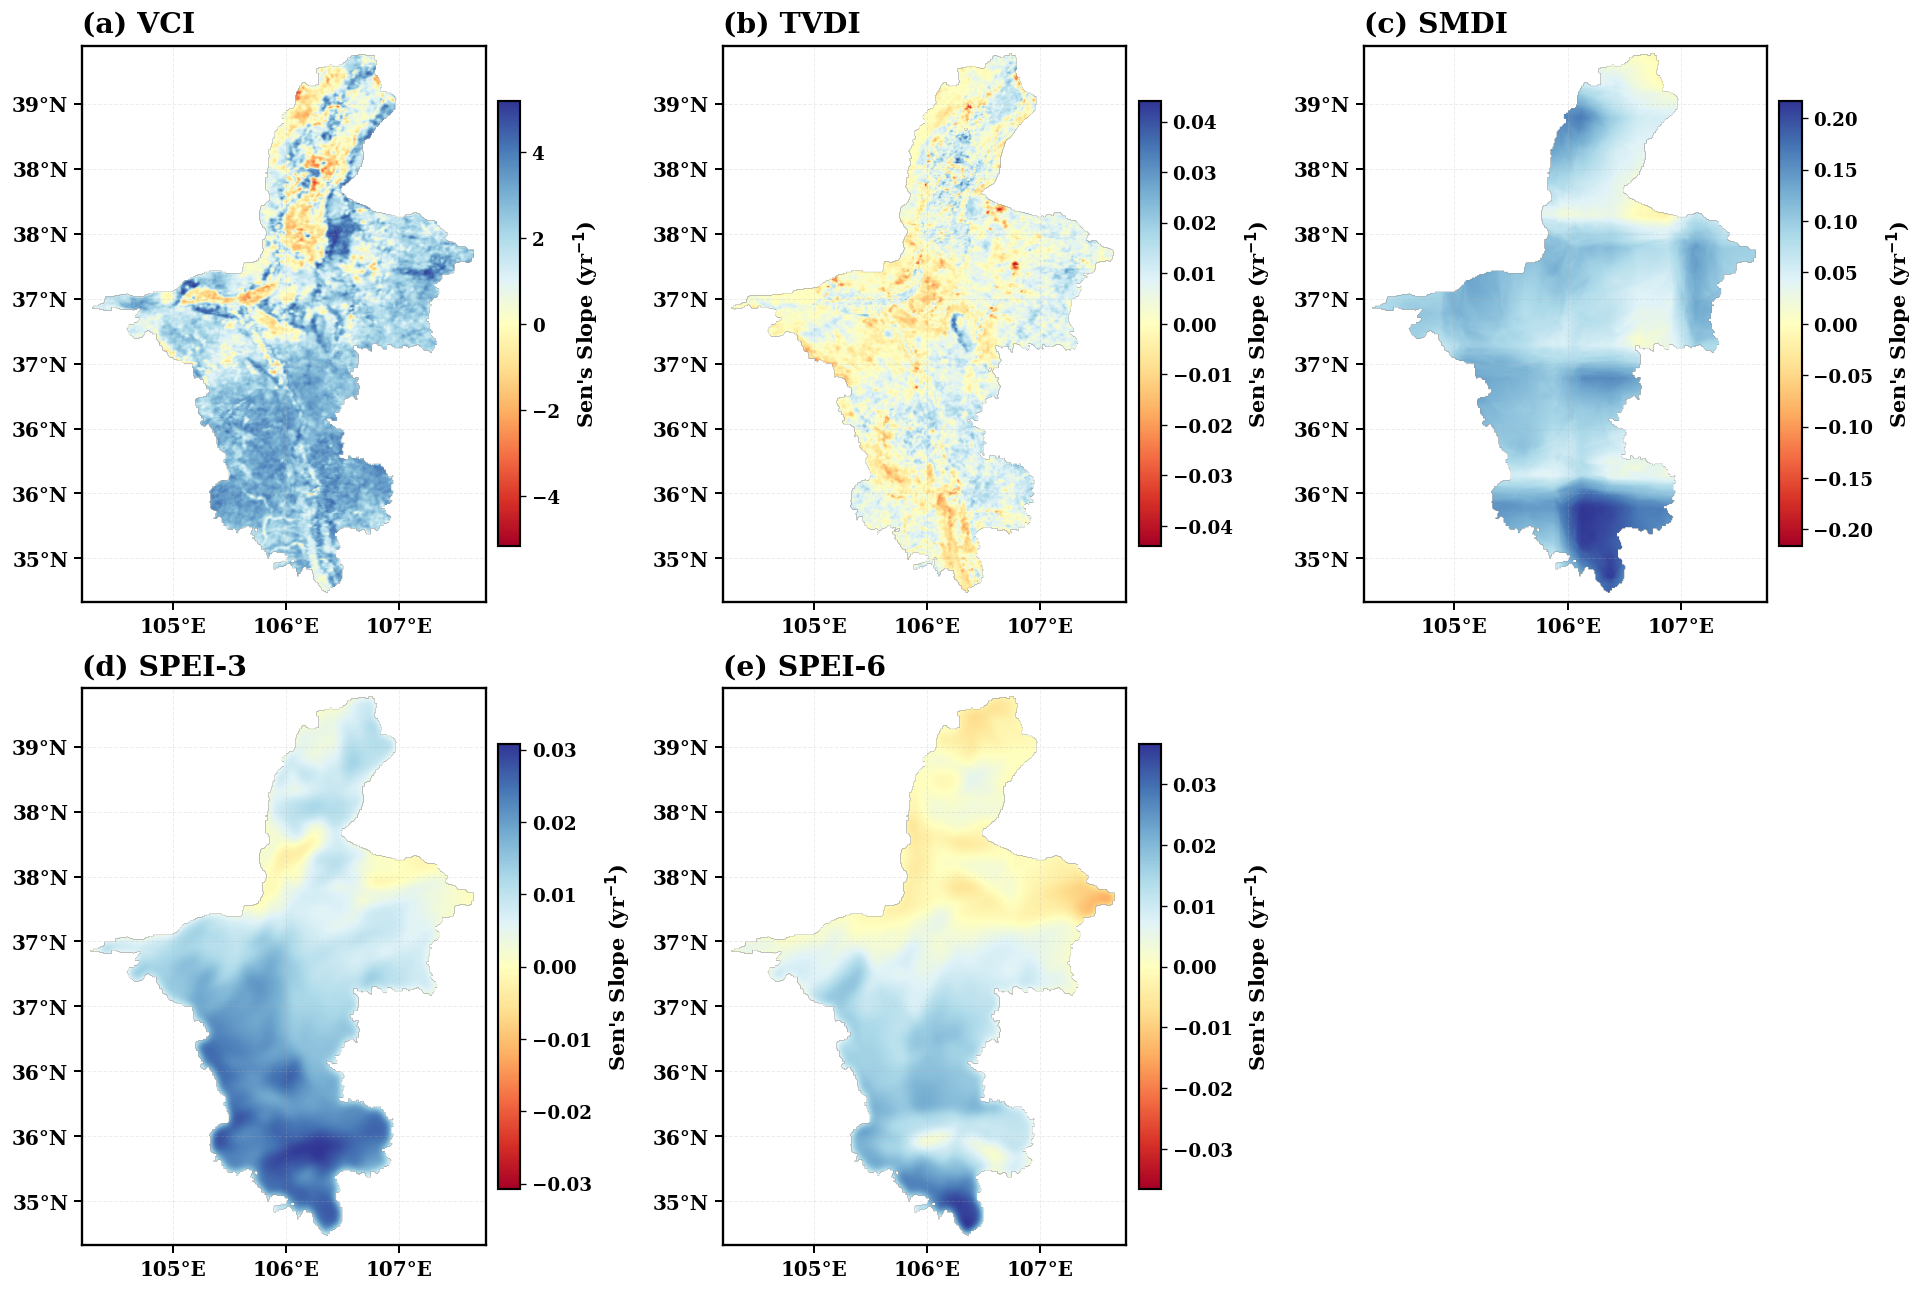


Final journal-ready figure saved → E:\2_Contribution\Final\Preprocess\3. Trend\Ningxia_All_Indices_Sens_Slope_FINAL_Journal.png


In [14]:
import os
import glob
import re
import numpy as np
import rasterio
from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.transform import from_origin
from scipy.ndimage import gaussian_filter
from scipy.stats import kendalltau, linregress
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from tqdm import tqdm
import pandas as pd

# ---- Paths ------------------------------------------------------------------
BASE_DIR = r"E:\2_Contribution\Final\Preprocess"

INDICES_DIRS = {
    'VCI'   : os.path.join(BASE_DIR, "VCI"),
    'TVDI'  : os.path.join(BASE_DIR, "TVDI", "annaul"),   # yearly GS files
    'SMDI'  : os.path.join(BASE_DIR, "SMDI"),
    'SPEI-3': os.path.join(BASE_DIR, "SPEI_3"),
    'SPEI-6': os.path.join(BASE_DIR, "SPEI_6")
}

FIG_DIR = os.path.join(BASE_DIR, "3. Trend")
RESULT_DIR = os.path.join(FIG_DIR, "Update result")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

GROWING_MONTHS = [4, 5, 6, 7, 8, 9, 10]
TARGET_CRS = "EPSG:4326"
TARGET_RES = 0.009
SMOOTH_INDICES = {'SPEI-3', 'SPEI-6'}
SMOOTH_SIGMA   = 4.0

# ---- Style ------------------------------------------------------------------
plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor'   : 'white',
    'axes.facecolor'     : 'white',
    'savefig.facecolor'  : 'white',
    'axes.edgecolor'     : 'black',
    'axes.linewidth'     : 1.4,
    'axes.labelcolor'    : 'black',
    'text.color'         : 'black',
    'axes.titlecolor'    : 'black',
    'xtick.color'        : 'black',
    'ytick.color'        : 'black',
    'figure.dpi'         : 120,
    'savefig.dpi'        : 400,
    'font.family'        : 'serif',
    'font.weight'        : 'bold',
    'axes.labelweight'   : 'bold',
    'axes.titleweight'   : 'bold',
})

def lat_fmt(v, pos):
    if v == 0: return "0°"
    return f"{abs(int(v))}°{'N' if v > 0 else 'S'}"

def lon_fmt(v, pos):
    if v == 0: return "0°"
    return f"{abs(int(v))}°{'E' if v > 0 else 'W'}"

results_summary = []
consistency_check = []
trend_maps = {}
pvalue_maps = {}
bounds_global = None
ref_transform = None
ref_width = None
ref_height = None

def load_and_reproject(fp, ref_transform, ref_width, ref_height):
    with rasterio.open(fp) as src:
        arr = src.read(1).astype(np.float32)
        nodata = src.nodata
        if nodata is not None:
            arr[arr == nodata] = np.nan
        else:
            arr[(arr <= -9999) | (arr > 1e10)] = np.nan
        # Extra safety for TVDI (already 0–1)
        if "TVDI" in os.path.basename(fp).upper():
            arr[(arr < 0) | (arr > 1)] = np.nan

        dst = np.full((ref_height, ref_width), np.nan, dtype=np.float32)
        src_crs = src.crs if src.crs else TARGET_CRS
        reproject(
            source=arr,
            destination=dst,
            src_transform=src.transform,
            src_crs=src_crs,
            dst_transform=ref_transform,
            dst_crs=TARGET_CRS,
            resampling=Resampling.bilinear,
            dst_nodata=np.nan
        )
        return dst

# -----------------------------------------------------------------------------
for name, input_dir in INDICES_DIRS.items():
    print(f"\n--- Processing Index: {name} ---")

    if name == 'TVDI':
        # ---------- Yearly growing-season TVDI ----------
        file_paths = sorted(glob.glob(os.path.join(input_dir, "TVDI_Ningxia_GS_*.tif")))
        if not file_paths:
            print(f"Warning: No TVDI_Ningxia_GS_*.tif files found in {input_dir}. Skipping...")
            continue

        yearly_files = {}
        for fp in file_paths:
            match = re.search(r"TVDI_Ningxia_GS_(\d{4})\.tif", os.path.basename(fp))
            if match:
                year = int(match.group(1))
                yearly_files[year] = [fp]          # already annual
    else:
        # ---------- Monthly indices ----------
        file_paths = glob.glob(os.path.join(input_dir, "*.tif"))
        if not file_paths:
            print(f"Warning: No TIFF files found in {input_dir}. Skipping...")
            continue

        yearly_files = {}
        for fp in file_paths:
            match = re.search(r"(\d{4})[_-]?(\d{2})\.tif", os.path.basename(fp))
            if match:
                year, month = int(match.group(1)), int(match.group(2))
                if month in GROWING_MONTHS:
                    yearly_files.setdefault(year, []).append(fp)

    years_sorted = sorted(yearly_files.keys())
    if not years_sorted:
        print(f"Warning: No growing-season files for {name}. Skipping...")
        continue

    # Establish common 1 km grid from the first available file
    if ref_transform is None:
        first_fp = yearly_files[years_sorted[0]][0]
        with rasterio.open(first_fp) as src:
            src_crs = src.crs if src.crs else TARGET_CRS
            left, bottom, right, top = transform_bounds(src_crs, TARGET_CRS, *src.bounds)
        left   -= 0.05
        right  += 0.05
        bottom -= 0.05
        top    += 0.05
        if (right - left) > 10 or (top - bottom) > 10:
            raise ValueError(f"Bounds look wrong: ({left:.3f}, {bottom:.3f}, {right:.3f}, {top:.3f})")
        ref_width  = int(np.ceil((right - left)  / TARGET_RES))
        ref_height = int(np.ceil((top   - bottom)/ TARGET_RES))
        ref_transform = from_origin(left, top, TARGET_RES, TARGET_RES)
        bounds_global = (left, bottom, right, top)
        print(f"Common 1 km grid: {ref_width} × {ref_height} pixels")
        print(f"Bounds: {bounds_global}")

    # Build annual stack
    annual_stack = []
    for yr in tqdm(years_sorted, desc=f"Loading {name}"):
        monthly = [load_and_reproject(fp, ref_transform, ref_width, ref_height)
                   for fp in yearly_files[yr]]
        if monthly:
            annual_stack.append(np.nanmean(np.stack(monthly, axis=0), axis=0))

    if len(annual_stack) < 5:
        print(f"Too few years for {name}. Skipping...")
        continue

    stack = np.array(annual_stack)
    time_steps, height, width = stack.shape
    x = np.array(years_sorted, dtype=np.float64)

    trend_map  = np.full((height, width), np.nan, dtype=np.float32)
    pvalue_map = np.full((height, width), np.nan, dtype=np.float32)

    for i in range(height):
        for j in range(width):
            y = stack[:, i, j]
            mask = ~np.isnan(y)
            if np.sum(mask) <= time_steps * 0.4:
                continue
            valid_x = x[mask]
            valid_y = y[mask]
            try:
                _, p_val = kendalltau(valid_x, valid_y)
                pvalue_map[i, j] = p_val
            except Exception:
                continue
            dx = valid_x[:, None] - valid_x
            dy = valid_y[:, None] - valid_y
            with np.errstate(divide='ignore', invalid='ignore'):
                slopes = dy[dx > 0] / dx[dx > 0]
            if slopes.size > 0:
                trend_map[i, j] = np.median(slopes)

    if name in SMOOTH_INDICES:
        print(f"  → Applying final Gaussian smoothing (σ={SMOOTH_SIGMA}) to {name}")
        valid_mask = ~np.isnan(trend_map)
        filled = np.where(valid_mask, trend_map, 0.0)
        smoothed = gaussian_filter(filled, sigma=SMOOTH_SIGMA)
        trend_map = np.where(valid_mask, smoothed, np.nan)

    trend_maps[name]  = trend_map
    pvalue_maps[name] = pvalue_map

    # ---- Summary statistics ----
    valid = ~np.isnan(trend_map)
    valid_vals  = trend_map[valid]
    valid_pvals = pvalue_map[valid]

    mean_trend  = float(np.mean(valid_vals)) if valid_vals.size else 0.0
    pos_pct     = 100 * np.mean(valid_vals > 0) if valid_vals.size else 0.0
    neg_pct     = 100 * np.mean(valid_vals < 0) if valid_vals.size else 0.0
    sig_pct     = 100 * np.mean(valid_pvals < 0.05) if valid_pvals.size else 0.0
    pos_sig_pct = 100 * np.mean((valid_vals > 0) & (valid_pvals < 0.05)) if valid_vals.size else 0.0
    neg_sig_pct = 100 * np.mean((valid_vals < 0) & (valid_pvals < 0.05)) if valid_vals.size else 0.0

    results_summary.append({
        'Index': name,
        'Mean Sen\'s slope (yr⁻¹)': round(mean_trend, 6),
        'Positive area (%)': round(pos_pct, 2),
        'Negative area (%)': round(neg_pct, 2),
        'Significant area (%)': round(sig_pct, 2),
        'Positive-significant (%)': round(pos_sig_pct, 2),
        'Negative-significant (%)': round(neg_sig_pct, 2)
    })

    # Regional consistency check (kept for completeness)
    regional_series = np.nanmean(stack, axis=(1, 2))
    ols_slope, _, ols_r, ols_p, _ = linregress(x, regional_series)
    dx_r = x[:, None] - x
    dy_r = regional_series[:, None] - regional_series
    with np.errstate(divide='ignore', invalid='ignore'):
        slopes_r = dy_r[dx_r > 0] / dx_r[dx_r > 0]
    sen_slope_regional = float(np.median(slopes_r)) if slopes_r.size else np.nan
    _, mk_p_regional = kendalltau(x, regional_series)
    consistency_check.append({
        'Index': name,
        'OLS_slope_regional': ols_slope,
        'OLS_r': ols_r,
        'OLS_p': ols_p,
        'Sen_slope_regional': sen_slope_regional,
        'MK_p_regional': mk_p_regional,
        'Mean_of_pixel_Sen_slopes': mean_trend
    })

# -----------------------------------------------------------------------------
# Save summary table
# -----------------------------------------------------------------------------
df_summary = pd.DataFrame(results_summary)
print("\n" + "="*90)
print("SUMMARY TABLE – Sen’s Slope Statistics")
print("="*90)
print(df_summary.to_string(index=False))
print("="*90)

csv_path = os.path.join(RESULT_DIR, "Sen_Slope_Summary_Statistics.csv")
xlsx_path = os.path.join(RESULT_DIR, "Sen_Slope_Summary_Statistics.xlsx")
df_summary.to_csv(csv_path, index=False, encoding='utf-8-sig')
df_summary.to_excel(xlsx_path, index=False)
print(f"\nSummary table saved to:\n  → {csv_path}\n  → {xlsx_path}")

# Optional: also save the consistency check
df_consist = pd.DataFrame(consistency_check)
df_consist.to_csv(os.path.join(RESULT_DIR, "Consistency_Check_Regional.csv"), index=False)
df_consist.to_excel(os.path.join(RESULT_DIR, "Consistency_Check_Regional.xlsx"), index=False)

# -----------------------------------------------------------------------------
# Final polished figure
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16.5, 11.2), facecolor='white')
axes = axes.flatten()

left, bottom, right, top = bounds_global
extent = [left, right, bottom, top]

labels     = ['(a) VCI', '(b) TVDI', '(c) SMDI', '(d) SPEI-3', '(e) SPEI-6']
index_keys = ['VCI', 'TVDI', 'SMDI', 'SPEI-3', 'SPEI-6']

for idx, key in enumerate(index_keys):
    ax = axes[idx]
    if key not in trend_maps:
        ax.axis('off')
        continue
    tmap = trend_maps[key]
    vmax = np.nanmax(np.abs(tmap))
    if np.isnan(vmax) or vmax == 0:
        vmax = 0.05
    im = ax.imshow(
        tmap,
        cmap='RdYlBu',
        vmin=-vmax, vmax=vmax,
        extent=extent,
        origin='upper',
        interpolation='bilinear',
        aspect='auto'
    )
    ax.set_title(labels[idx], fontsize=17, fontweight='bold', loc='left', pad=8)
    ax.set_xlim(left, right)
    ax.set_ylim(bottom, top)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lon_fmt))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lat_fmt))
    ax.tick_params(axis='both', labelsize=12, width=1.2, length=5)
    for lab in ax.get_xticklabels() + ax.get_yticklabels():
        lab.set_fontweight('bold')
    ax.grid(alpha=0.22, linestyle='--', linewidth=0.6)
    cbar = fig.colorbar(im, ax=ax, shrink=0.80, orientation='vertical', pad=0.025)
    cbar.set_label("Sen's Slope (yr$^{-1}$)", fontsize=12.5, fontweight='bold', labelpad=7)
    cbar.ax.tick_params(labelsize=11)
    cbar.outline.set_linewidth(1.3)

axes[5].axis('off')
plt.tight_layout(rect=[0.01, 0.01, 0.99, 0.98])

out_fig = os.path.join(FIG_DIR, 'Ningxia_All_Indices_Sens_Slope_FINAL_Journal.png')
plt.savefig(out_fig, bbox_inches='tight', dpi=400, facecolor='white')
plt.show()
print(f"\nFinal journal-ready figure saved → {out_fig}")

Extracting time-series for: VCI...
Extracting time-series for: TVDI...
Extracting time-series for: SMDI...
Extracting time-series for: SPEI-3...
Extracting time-series for: SPEI-6...


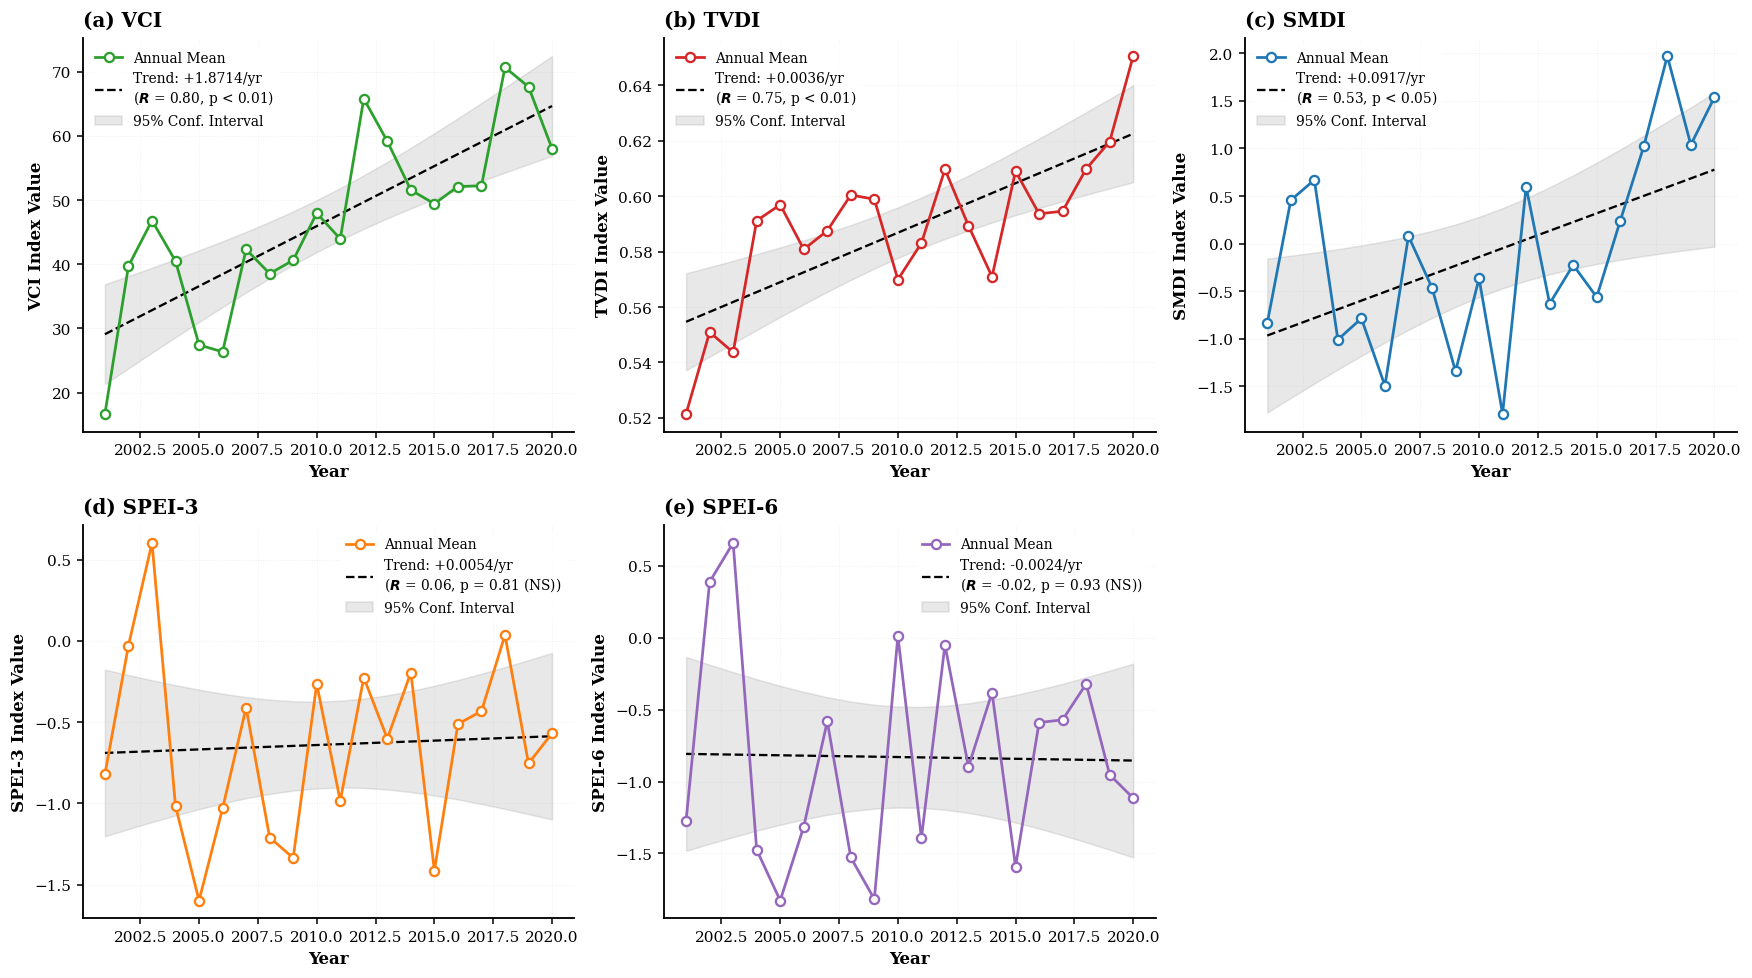


Enhanced multi-panel time-series figure successfully saved to:
E:\2_Contribution\Final\Preprocess\3. Trend\Update result\Ningxia_All_Indices_Timeseries_Enhanced.png


In [15]:
import os
import glob
import re
import numpy as np
import rasterio
import matplotlib.pyplot as plt
from scipy import stats

# ---- Paths Configuration ----------------------------------------------------
BASE_DIR = r"E:\2_Contribution\Final\Preprocess"

INDICES_DIRS = {
    'VCI'   : os.path.join(BASE_DIR, "VCI"),
    'TVDI'  : os.path.join(BASE_DIR, "TVDI", "annaul"),   # yearly GS files
    'SMDI'  : os.path.join(BASE_DIR, "SMDI"),
    'SPEI-3': os.path.join(BASE_DIR, "SPEI_3"),
    'SPEI-6': os.path.join(BASE_DIR, "SPEI_6")
}

FIG_DIR = os.path.join(BASE_DIR, "3. Trend")
RESULT_DIR = os.path.join(FIG_DIR, "Update result")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)

GROWING_MONTHS = [4, 5, 6, 7, 8, 9, 10]

# ---- Publication Style Configuration ----------------------------------------
plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor'   : 'white',
    'axes.facecolor'     : 'white',
    'savefig.facecolor'  : 'white',
    'axes.edgecolor'     : 'black',
    'axes.linewidth'     : 1.2,
    'axes.labelcolor'    : 'black',
    'text.color'         : 'black',
    'axes.titlecolor'    : 'black',
    'xtick.color'        : 'black',
    'ytick.color'        : 'black',
    'figure.dpi'         : 110,
    'savefig.dpi'        : 400,
    'font.family'        : 'serif',
    'font.weight'        : 'normal',
    'axes.labelweight'   : 'bold',
    'axes.titleweight'   : 'bold',
})

timeseries_data = {}

# -----------------------------------------------------------------------------
# 1. Extract Annual Regional Means from Rasters
# -----------------------------------------------------------------------------
for name, input_dir in INDICES_DIRS.items():
    print(f"Extracting time-series for: {name}...")

    if name == 'TVDI':
        # ---------- Yearly growing-season TVDI ----------
        search_pattern = os.path.join(input_dir, "TVDI_Ningxia_GS_*.tif")
        file_paths = sorted(glob.glob(search_pattern))

        if not file_paths:
            print(f"Warning: No TVDI_Ningxia_GS_*.tif files found in {input_dir}. Skipping...")
            continue

        years_sorted = []
        annual_means = []

        for fp in file_paths:
            filename = os.path.basename(fp)
            match = re.search(r"TVDI_Ningxia_GS_(\d{4})\.tif", filename)
            if not match:
                continue
            year = int(match.group(1))

            with rasterio.open(fp) as src:
                arr = src.read(1).astype(np.float32)
                nodata = src.nodata
                if nodata is not None:
                    arr[arr == nodata] = np.nan
                else:
                    # TVDI is already 0–1; mask invalid values
                    arr[(arr <= -9999) | (arr < 0) | (arr > 1)] = np.nan
                annual_means.append(np.nanmean(arr))
                years_sorted.append(year)

        if years_sorted:
            timeseries_data[name] = {
                'years': np.array(years_sorted),
                'means': np.array(annual_means)
            }

    else:
        # ---------- Monthly indices (original logic) ----------
        search_pattern = os.path.join(input_dir, "*.tif")
        file_paths = glob.glob(search_pattern)

        if not file_paths:
            print(f"Warning: No files found in {input_dir}. Skipping...")
            continue

        yearly_data_dict = {}
        for fp in file_paths:
            filename = os.path.basename(fp)
            match = re.search(r"(\d{4})[_-]?(\d{2})\.tif", filename)
            if match:
                year, month = int(match.group(1)), int(match.group(2))
                if month in GROWING_MONTHS:
                    if year not in yearly_data_dict:
                        yearly_data_dict[year] = []
                    yearly_data_dict[year].append(fp)

        years_sorted = sorted(yearly_data_dict.keys())
        annual_means = []
        for yr in years_sorted:
            monthly_stack = []
            for fp in yearly_data_dict[yr]:
                with rasterio.open(fp) as src:
                    arr = src.read(1).astype(np.float32)
                    nodata = src.nodata
                    if nodata is not None:
                        arr[arr == nodata] = np.nan
                    else:
                        arr[arr <= -9999] = np.nan
                    monthly_stack.append(np.nanmean(arr))
            annual_means.append(np.nanmean(monthly_stack))

        if years_sorted:
            timeseries_data[name] = {
                'years': np.array(years_sorted),
                'means': np.array(annual_means)
            }

# -----------------------------------------------------------------------------
# 2. Plotting Enhanced Multi-Panel Time Series Figure
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9), facecolor='white')
axes = axes.flatten()

labels = ['(a) VCI', '(b) TVDI', '(c) SMDI', '(d) SPEI-3', '(e) SPEI-6']
index_keys = ['VCI', 'TVDI', 'SMDI', 'SPEI-3', 'SPEI-6']
colors = ['#2ca02c', '#d62728', '#1f77b4', '#ff7f0e', '#9467bd']

for idx, key in enumerate(index_keys):
    ax = axes[idx]
    if key not in timeseries_data:
        ax.axis('off')
        continue

    yrs = timeseries_data[key]['years']
    vals = timeseries_data[key]['means']

    # Linear fit & confidence intervals
    slope, intercept, r_value, p_value, std_err = stats.linregress(yrs, vals)
    y_pred = slope * yrs + intercept

    # Significance annotation tag
    sig_text = f"p < 0.01" if p_value < 0.01 else (f"p < 0.05" if p_value < 0.05 else f"p = {p_value:.2f} (NS)")
    trend_label = f"Trend: {slope:+.4f}/yr\n($R$ = {r_value:.2f}, {sig_text})"

    # Scatter & Line Plot for Annual Means
    ax.plot(yrs, vals, marker='o', color=colors[idx], linewidth=1.8, markersize=6,
            markerfacecolor='white', markeredgewidth=1.5, zorder=3, label='Annual Mean')

    # Trend line
    ax.plot(yrs, y_pred, linestyle='--', color='black', linewidth=1.5, zorder=2, label=trend_label)

    # 95% Confidence Interval Band
    n = len(yrs)
    t_val = stats.t.ppf(0.975, n - 2)
    residuals = vals - y_pred
    s_err = np.sqrt(np.sum(residuals**2) / (n - 2))
    x_centered = yrs - np.mean(yrs)
    ci = t_val * s_err * np.sqrt(1/n + (x_centered**2) / np.sum(x_centered**2))
    ax.fill_between(yrs, y_pred - ci, y_pred + ci, color='gray', alpha=0.18, zorder=1, label='95% Conf. Interval')

    # Formatting aesthetics
    ax.set_title(labels[idx], fontsize=13, fontweight='bold', loc='left', pad=8)
    ax.set_xlabel('Year', fontsize=11, fontweight='bold')
    ax.set_ylabel(f'{key} Index Value', fontsize=11, fontweight='bold')

    ax.tick_params(axis='both', labelsize=10, width=1.0, length=4)
    ax.grid(alpha=0.2, linestyle=':', linewidth=0.6)

    # Clean spine layout
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Optimized legend placement
    ax.legend(frameon=True, facecolor='white', edgecolor='none', fontsize=9, loc='best')

# Hide the 6th unused subplot
axes[5].axis('off')
plt.tight_layout()

# Save into the Update result folder
out_fig = os.path.join(RESULT_DIR, 'Ningxia_All_Indices_Timeseries_Enhanced.png')
plt.savefig(out_fig, bbox_inches='tight', dpi=400, facecolor='white')
plt.show()

print("\n" + "="*60)
print(f"Enhanced multi-panel time-series figure successfully saved to:\n{out_fig}")
print("="*60)


Processing VCI
Input directory: E:\2_Contribution\Final\Preprocess\VCI
  2001: 7/7 months; regional mean = 16.69235
  2002: 7/7 months; regional mean = 39.71896
  2003: 7/7 months; regional mean = 46.80870
  2004: 7/7 months; regional mean = 40.48759
  2005: 7/7 months; regional mean = 27.42866
  2006: 7/7 months; regional mean = 26.34321
  2007: 7/7 months; regional mean = 42.31726
  2008: 7/7 months; regional mean = 38.53520
  2009: 7/7 months; regional mean = 40.62129
  2010: 7/7 months; regional mean = 47.95918
  2011: 7/7 months; regional mean = 43.94534
  2012: 7/7 months; regional mean = 65.79643
  2013: 7/7 months; regional mean = 59.15799
  2014: 7/7 months; regional mean = 51.55450
  2015: 7/7 months; regional mean = 49.42619
  2016: 7/7 months; regional mean = 52.10653
  2017: 7/7 months; regional mean = 52.21494
  2018: 7/7 months; regional mean = 70.67396
  2019: 7/7 months; regional mean = 67.64512
  2020: 7/7 months; regional mean = 58.02394

Processing TVDI
Input direc

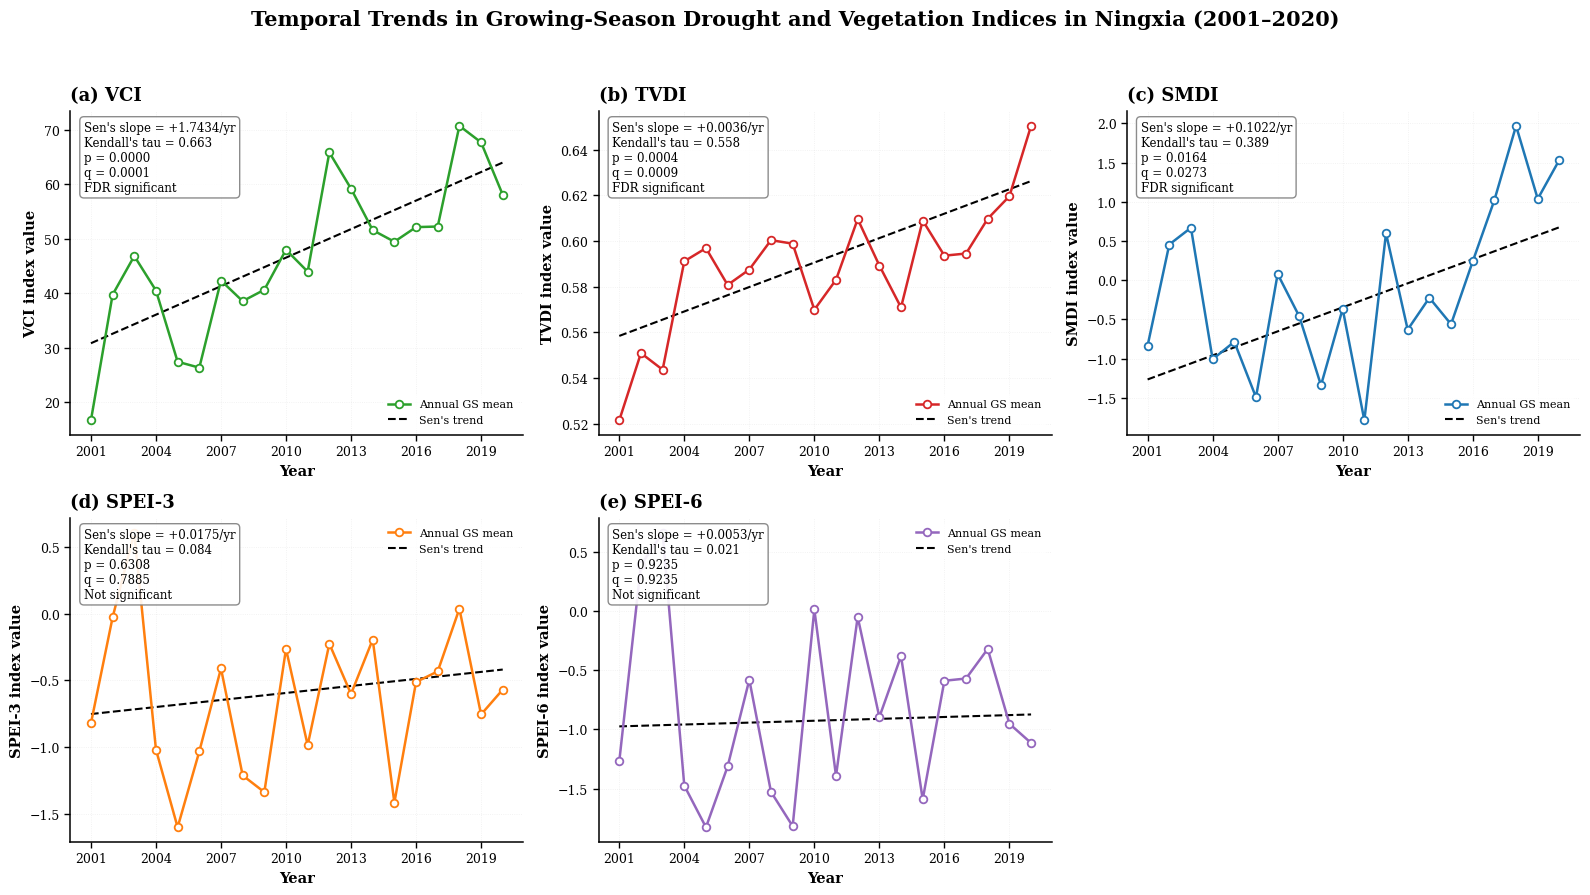


ANALYSIS COMPLETED

Output directory:
E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR

Generated files:
1. Ningxia_All_Indices_Timeseries_MK_Sen_FDR.png
2. Annual_Growing_Season_Regional_Means.csv
3. Regional_TimeSeries_MK_Sen_FDR_Results.csv
4. Regional_Trend_Analysis_Summary_with_FDR.txt

Summary:
 Index  Number_of_Years  Start_Year  End_Year  Kendall_Tau  Sen_Slope_per_Year  Sen_Slope_CI_Lower  Sen_Slope_CI_Upper  Original_MK_p_value  BH_FDR_adjusted_p_value  FDR_Significant      Trend_Direction
   VCI               20        2001      2020     0.663158            1.743367            1.006476            2.607748             0.000012                 0.000058             True Significant increase
  TVDI               20        2001      2020     0.557895            0.003572            0.001431            0.005383             0.000359                 0.000897             True Significant increase
  SMDI               20        2001      2020     0.389474            

In [1]:
# New trend with FDR

import os
import re
import glob
import warnings
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt

from scipy import stats

# =============================================================================
# 1. PATHS AND SETTINGS
# =============================================================================

BASE_DIR = r"E:\2_Contribution\Final\Preprocess"

INDICES_DIRS = {
    "VCI": os.path.join(BASE_DIR, "VCI"),
    "TVDI": os.path.join(BASE_DIR, "TVDI", "annaul"),
    "SMDI": os.path.join(BASE_DIR, "SMDI"),
    "SPEI-3": os.path.join(BASE_DIR, "SPEI_3"),
    "SPEI-6": os.path.join(BASE_DIR, "SPEI_6")
}

OUTPUT_DIR = os.path.join(
    BASE_DIR, "3. Trend", "Update result", "with FDR"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

START_YEAR = 2001
END_YEAR = 2020

GROWING_MONTHS = [4, 5, 6, 7, 8, 9, 10]

# Require all seven growing-season months for a complete annual value.
REQUIRE_ALL_MONTHS = True

# Significance threshold
ALPHA = 0.05

# =============================================================================
# 2. PUBLICATION FIGURE SETTINGS
# =============================================================================

plt.style.use("default")

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": "black",
    "axes.linewidth": 1.1,
    "axes.labelcolor": "black",
    "text.color": "black",
    "axes.titlecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "font.family": "serif",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "savefig.dpi": 400
})

INDEX_ORDER = ["VCI", "TVDI", "SMDI", "SPEI-3", "SPEI-6"]

INDEX_LABELS = {
    "VCI": "(a) VCI",
    "TVDI": "(b) TVDI",
    "SMDI": "(c) SMDI",
    "SPEI-3": "(d) SPEI-3",
    "SPEI-6": "(e) SPEI-6"
}

INDEX_COLORS = {
    "VCI": "#2ca02c",
    "TVDI": "#d62728",
    "SMDI": "#1f77b4",
    "SPEI-3": "#ff7f0e",
    "SPEI-6": "#9467bd"
}

# =============================================================================
# 3. RASTER READING FUNCTIONS
# =============================================================================

def read_raster(fp):
    """
    Read a raster as float32 and convert NoData/masked cells to NaN.
    """
    with rasterio.open(fp) as src:
        data = src.read(1, masked=True).astype(np.float32).filled(np.nan)

        profile = {
            "crs": src.crs,
            "transform": src.transform,
            "width": src.width,
            "height": src.height,
            "nodata": src.nodata
        }

    data[~np.isfinite(data)] = np.nan
    return data, profile


def check_same_grid(reference, current, filename):
    """
    Ensure all monthly rasters use the same grid.
    This script does not silently resample misaligned rasters.
    """
    same = (
        reference["crs"] == current["crs"]
        and reference["transform"] == current["transform"]
        and reference["width"] == current["width"]
        and reference["height"] == current["height"]
    )

    if not same:
        raise ValueError(
            f"Raster grid mismatch detected:\n{filename}\n"
            "Please align the raster grids before running this analysis."
        )


def find_monthly_files(input_dir):
    """
    Identify monthly TIFF files containing YYYY_MM, YYYY-MM,
    or YYYYMM immediately before the .tif extension.
    """
    files = glob.glob(os.path.join(input_dir, "*.tif"))

    monthly_files = {}

    for fp in files:
        filename = os.path.basename(fp)

        match = re.search(
            r"(20\d{2})[_-]?(\d{2})\.tif$",
            filename,
            flags=re.IGNORECASE
        )

        if not match:
            continue

        year = int(match.group(1))
        month = int(match.group(2))

        if START_YEAR <= year <= END_YEAR and month in GROWING_MONTHS:
            key = (year, month)

            if key in monthly_files:
                raise ValueError(
                    f"Duplicate monthly raster detected for {key}:\n"
                    f"{monthly_files[key]}\n{fp}"
                )

            monthly_files[key] = fp

    return monthly_files


# =============================================================================
# 4. EXTRACT ANNUAL GROWING-SEASON REGIONAL MEANS
# =============================================================================

annual_data = {}
annual_file_counts = {}

for index_name in INDEX_ORDER:

    input_dir = INDICES_DIRS[index_name]

    print("\n" + "=" * 70)
    print(f"Processing {index_name}")
    print(f"Input directory: {input_dir}")
    print("=" * 70)

    if not os.path.isdir(input_dir):
        warnings.warn(
            f"Directory not found for {index_name}: {input_dir}"
        )
        continue

    annual_means = {}
    annual_counts = {}

    # -------------------------------------------------------------------------
    # TVDI: already prepared as annual growing-season rasters
    # -------------------------------------------------------------------------

    if index_name == "TVDI":

        file_paths = glob.glob(
            os.path.join(input_dir, "TVDI_Ningxia_GS_*.tif")
        )

        tvdi_files = {}

        for fp in file_paths:
            filename = os.path.basename(fp)

            match = re.search(
                r"TVDI_Ningxia_GS_(\d{4})\.tif$",
                filename,
                flags=re.IGNORECASE
            )

            if match:
                year = int(match.group(1))

                if START_YEAR <= year <= END_YEAR:
                    if year in tvdi_files:
                        raise ValueError(
                            f"Duplicate TVDI raster for {year}"
                        )
                    tvdi_files[year] = fp

        for year in range(START_YEAR, END_YEAR + 1):

            if year not in tvdi_files:
                print(f"  Missing TVDI annual raster: {year}")
                continue

            fp = tvdi_files[year]
            arr, _ = read_raster(fp)

            # TVDI is expected to range from 0 to 1.
            arr[(arr < 0) | (arr > 1)] = np.nan

            if np.isfinite(arr).any():
                annual_means[year] = float(np.nanmean(arr))
                annual_counts[year] = 1

                print(
                    f"  {year}: regional mean = "
                    f"{annual_means[year]:.5f}"
                )

    # -------------------------------------------------------------------------
    # VCI, SMDI, SPEI-3, SPEI-6: monthly rasters
    # -------------------------------------------------------------------------

    else:

        monthly_files = find_monthly_files(input_dir)

        for year in range(START_YEAR, END_YEAR + 1):

            expected_months = GROWING_MONTHS

            available_months = [
                month for month in expected_months
                if (year, month) in monthly_files
            ]

            if REQUIRE_ALL_MONTHS and len(available_months) != 7:
                print(
                    f"  Excluding {year}: "
                    f"only {len(available_months)}/7 months available"
                )
                continue

            if len(available_months) == 0:
                print(f"  Excluding {year}: no monthly files available")
                continue

            arrays = []
            reference_profile = None

            for month in available_months:

                fp = monthly_files[(year, month)]

                arr, profile = read_raster(fp)

                if reference_profile is None:
                    reference_profile = profile
                else:
                    check_same_grid(
                        reference_profile,
                        profile,
                        fp
                    )

                arrays.append(arr)

            # Stack monthly rasters:
            # dimensions = months x rows x columns
            monthly_stack = np.stack(arrays, axis=0)

            # Pixel-wise annual growing-season mean.
            # With REQUIRE_ALL_MONTHS=True, each pixel must have
            # valid observations in all seven months.
            if REQUIRE_ALL_MONTHS:
                valid_count = np.sum(
                    np.isfinite(monthly_stack), axis=0
                )

                annual_raster = np.full(
                    monthly_stack.shape[1:],
                    np.nan,
                    dtype=np.float32
                )

                valid_pixels = valid_count == 7

                annual_raster[valid_pixels] = np.nanmean(
                    monthly_stack[:, valid_pixels],
                    axis=0
                )

            else:
                annual_raster = np.nanmean(
                    monthly_stack,
                    axis=0
                )

            if not np.isfinite(annual_raster).any():
                print(f"  Excluding {year}: no valid annual pixels")
                continue

            # Regional mean calculated from the annual GS raster.
            regional_mean = float(np.nanmean(annual_raster))

            annual_means[year] = regional_mean
            annual_counts[year] = len(available_months)

            print(
                f"  {year}: {len(available_months)}/7 months; "
                f"regional mean = {regional_mean:.5f}"
            )

    if annual_means:

        sorted_years = sorted(annual_means.keys())

        annual_data[index_name] = {
            "years": np.array(sorted_years, dtype=int),
            "means": np.array(
                [annual_means[y] for y in sorted_years],
                dtype=float
            )
        }

        annual_file_counts[index_name] = annual_counts

    else:
        print(f"WARNING: No usable annual data for {index_name}")


# =============================================================================
# 5. SAVE ANNUAL REGIONAL MEAN DATA
# =============================================================================

annual_records = []

for index_name, data in annual_data.items():

    for year, value in zip(data["years"], data["means"]):

        annual_records.append({
            "Index": index_name,
            "Year": int(year),
            "Growing_Season_Mean": float(value)
        })

annual_df = pd.DataFrame(annual_records)

annual_csv = os.path.join(
    OUTPUT_DIR,
    "Annual_Growing_Season_Regional_Means.csv"
)

annual_df.to_csv(annual_csv, index=False, float_format="%.8f")

print("\nAnnual regional mean data saved:")
print(annual_csv)


# =============================================================================
# 6. MANN-KENDALL TEST AND SEN'S SLOPE
# =============================================================================

trend_results = {}

for index_name in INDEX_ORDER:

    if index_name not in annual_data:
        continue

    years = annual_data[index_name]["years"]
    values = annual_data[index_name]["means"]

    valid = np.isfinite(years) & np.isfinite(values)

    years = years[valid]
    values = values[valid]

    if len(values) < 3:
        print(f"Insufficient observations for {index_name}")
        continue

    # Kendall's tau and two-sided p-value.
    # For a monotonic trend, this is the Kendall/MK test statistic.
    mk_result = stats.kendalltau(
        years,
        values,
        alternative="two-sided",
        method="auto"
    )

    tau = float(mk_result.statistic)
    p_value = float(mk_result.pvalue)

    # Sen's slope, in index units per year.
    sen_result = stats.theilslopes(
        values,
        years,
        alpha=0.95,
        method="separate"
    )

    sen_slope = float(sen_result.slope)
    sen_intercept = float(sen_result.intercept)

    low_slope = float(sen_result.low_slope)
    high_slope = float(sen_result.high_slope)

    if p_value < 0.05:
        direction = (
            "Increasing" if sen_slope > 0 else
            "Decreasing" if sen_slope < 0 else
            "No directional trend"
        )
    else:
        direction = "No significant trend"

    trend_results[index_name] = {
        "n": len(values),
        "start_year": int(years.min()),
        "end_year": int(years.max()),
        "tau": tau,
        "sen_slope": sen_slope,
        "sen_intercept": sen_intercept,
        "low_slope": low_slope,
        "high_slope": high_slope,
        "p_raw": p_value,
        "direction": direction,
        "years": years,
        "values": values
    }


# =============================================================================
# 7. BENJAMINI-HOCHBERG FDR CORRECTION
# =============================================================================

def benjamini_hochberg(p_values):
    """
    Benjamini-Hochberg adjusted p-values.
    Returns adjusted q-values in the original order.
    """
    p_values = np.asarray(p_values, dtype=float)

    adjusted = np.full(p_values.shape, np.nan, dtype=float)

    valid = np.isfinite(p_values)

    p = p_values[valid]
    m = len(p)

    if m == 0:
        return adjusted

    order = np.argsort(p)
    sorted_p = p[order]

    ranks = np.arange(1, m + 1)

    sorted_adjusted = sorted_p * m / ranks

    # Enforce monotonicity from largest to smallest p-value.
    sorted_adjusted = np.minimum.accumulate(
        sorted_adjusted[::-1]
    )[::-1]

    sorted_adjusted = np.clip(sorted_adjusted, 0, 1)

    restored = np.empty(m, dtype=float)
    restored[order] = sorted_adjusted

    adjusted[valid] = restored

    return adjusted


# Apply BH correction across the five regional index-level tests
available_indices = list(trend_results.keys())

raw_p_values = [
    trend_results[name]["p_raw"]
    for name in available_indices
]

adjusted_p_values = benjamini_hochberg(raw_p_values)

for name, q_value in zip(
    available_indices,
    adjusted_p_values
):

    trend_results[name]["p_fdr"] = float(q_value)

    trend_results[name]["fdr_significant"] = (
        q_value < ALPHA
    )

    slope = trend_results[name]["sen_slope"]

    if q_value < ALPHA:
        if slope > 0:
            trend_results[name]["fdr_direction"] = "Significant increase"
        elif slope < 0:
            trend_results[name]["fdr_direction"] = "Significant decrease"
        else:
            trend_results[name]["fdr_direction"] = "No directional trend"
    else:
        trend_results[name]["fdr_direction"] = "Not significant"


# =============================================================================
# 8. SAVE STATISTICAL RESULTS TABLE
# =============================================================================

result_records = []

for name in INDEX_ORDER:

    if name not in trend_results:
        continue

    r = trend_results[name]

    result_records.append({
        "Index": name,
        "Number_of_Years": r["n"],
        "Start_Year": r["start_year"],
        "End_Year": r["end_year"],
        "Kendall_Tau": r["tau"],
        "Sen_Slope_per_Year": r["sen_slope"],
        "Sen_Slope_CI_Lower": r["low_slope"],
        "Sen_Slope_CI_Upper": r["high_slope"],
        "Original_MK_p_value": r["p_raw"],
        "BH_FDR_adjusted_p_value": r["p_fdr"],
        "FDR_Significant": r["fdr_significant"],
        "Trend_Direction": r["fdr_direction"]
    })

results_df = pd.DataFrame(result_records)

results_csv = os.path.join(
    OUTPUT_DIR,
    "Regional_TimeSeries_MK_Sen_FDR_Results.csv"
)

results_df.to_csv(
    results_csv,
    index=False,
    float_format="%.8f"
)


# =============================================================================
# 9. CREATE PUBLICATION-QUALITY TIME-SERIES FIGURE
# =============================================================================

fig, axes = plt.subplots(
    2, 3,
    figsize=(16, 9),
    facecolor="white"
)

axes = axes.flatten()

for idx, index_name in enumerate(INDEX_ORDER):

    ax = axes[idx]

    if index_name not in trend_results:
        ax.axis("off")
        continue

    r = trend_results[index_name]

    years = r["years"]
    values = r["values"]

    slope = r["sen_slope"]
    intercept = r["sen_intercept"]

    # Sen's fitted trend line.
    fitted = slope * years + intercept

    # Annual mean observations.
    ax.plot(
        years,
        values,
        marker="o",
        color=INDEX_COLORS[index_name],
        linewidth=1.8,
        markersize=5.5,
        markerfacecolor="white",
        markeredgewidth=1.3,
        label="Annual GS mean",
        zorder=3
    )

    # Sen's slope trend line.
    ax.plot(
        years,
        fitted,
        linestyle="--",
        color="black",
        linewidth=1.5,
        label="Sen's trend",
        zorder=2
    )

    # Significance annotation based on BH-adjusted p-value.
    if r["p_fdr"] < ALPHA:
        sig_label = "FDR significant"
    else:
        sig_label = "Not significant"

    annotation = (
        f"Sen's slope = {slope:+.4f}/yr\n"
        f"Kendall's tau = {r['tau']:.3f}\n"
        f"p = {r['p_raw']:.4f}\n"
        f"q = {r['p_fdr']:.4f}\n"
        f"{sig_label}"
    )

    ax.text(
        0.03,
        0.97,
        annotation,
        transform=ax.transAxes,
        va="top",
        ha="left",
        fontsize=8.5,
        bbox={
            "boxstyle": "round,pad=0.35",
            "facecolor": "white",
            "edgecolor": "gray",
            "alpha": 0.9
        }
    )

    ax.set_title(
        INDEX_LABELS[index_name],
        fontsize=13,
        fontweight="bold",
        loc="left",
        pad=8
    )

    ax.set_xlabel(
        "Year",
        fontsize=10.5,
        fontweight="bold"
    )

    ax.set_ylabel(
        f"{index_name} index value",
        fontsize=10.5,
        fontweight="bold"
    )

    ax.set_xticks(
        np.arange(START_YEAR, END_YEAR + 1, 3)
    )

    ax.tick_params(
        axis="both",
        labelsize=9,
        width=1.0,
        length=4
    )

    ax.grid(
        alpha=0.20,
        linestyle=":",
        linewidth=0.6
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.legend(
        frameon=True,
        facecolor="white",
        edgecolor="none",
        fontsize=8,
        loc="best"
    )

# Hide unused sixth panel.
axes[5].axis("off")

fig.suptitle(
    "Temporal Trends in Growing-Season Drought and Vegetation Indices in Ningxia (2001–2020)",
    fontsize=15,
    fontweight="bold",
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

figure_path = os.path.join(
    OUTPUT_DIR,
    "Ningxia_All_Indices_Timeseries_MK_Sen_FDR.png"
)

plt.savefig(
    figure_path,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()
plt.close()


# =============================================================================
# 10. CREATE READABLE SUMMARY TEXT FILE
# =============================================================================

summary_path = os.path.join(
    OUTPUT_DIR,
    "Regional_Trend_Analysis_Summary_with_FDR.txt"
)

with open(summary_path, "w", encoding="utf-8") as f:

    f.write("=" * 90 + "\n")
    f.write("REGIONAL TEMPORAL TREND ANALYSIS: NINGXIA, CHINA\n")
    f.write("=" * 90 + "\n\n")

    f.write("Study period: 2001–2020\n")
    f.write("Growing season: April–October\n")
    f.write("Indices: VCI, TVDI, SMDI, SPEI-3, SPEI-6\n\n")

    f.write("ANALYTICAL PROCEDURE\n")
    f.write("-" * 90 + "\n")

    f.write(
        "1. Monthly raster data were aggregated into annual "
        "April–October growing-season means.\n"
    )

    f.write(
        "2. For monthly indices, annual growing-season values "
        "were calculated pixel by pixel before computing the "
        "regional mean.\n"
    )

    f.write(
        "3. Only years with all seven growing-season monthly "
        "rasters were retained.\n"
    )

    f.write(
        "4. TVDI was analysed using the existing annual "
        "growing-season rasters.\n"
    )

    f.write(
        "5. Monotonic temporal trends were evaluated using "
        "Kendall's tau (two-sided Mann–Kendall test).\n"
    )

    f.write(
        "6. Trend magnitude was estimated using Sen's slope "
        "in index units per year.\n"
    )

    f.write(
        "7. Benjamini–Hochberg false discovery rate correction "
        "was applied across the available regional index-level "
        "p-values (one family of tests).\n\n"
    )

    f.write("STATISTICAL RESULTS\n")
    f.write("-" * 90 + "\n\n")

    header = (
        f"{'Index':<10}"
        f"{'N':>5}"
        f"{'Tau':>11}"
        f"{'Sen slope/yr':>16}"
        f"{'Raw p':>13}"
        f"{'FDR q':>13}"
        f"{'FDR result':>22}\n"
    )

    f.write(header)
    f.write("-" * 90 + "\n")

    for name in INDEX_ORDER:

        if name not in trend_results:
            f.write(f"{name:<10} No valid data available\n")
            continue

        r = trend_results[name]

        line = (
            f"{name:<10}"
            f"{r['n']:>5d}"
            f"{r['tau']:>11.4f}"
            f"{r['sen_slope']:>16.6f}"
            f"{r['p_raw']:>13.6f}"
            f"{r['p_fdr']:>13.6f}"
            f"{r['fdr_direction']:>22}\n"
        )

        f.write(line)

    f.write("\n")
    f.write("=" * 90 + "\n")
    f.write("INTERPRETATION AND STATISTICAL NOTES\n")
    f.write("=" * 90 + "\n\n")

    f.write(
        "A positive Sen's slope indicates an increasing index "
        "value over time, whereas a negative slope indicates "
        "a decreasing index value. The ecological or drought "
        "interpretation of an increase or decrease depends on "
        "the index definition.\n\n"
    )

    f.write(
        "Original p-values are reported alongside BH-FDR "
        "adjusted q-values. Regional index-level statistical "
        "significance is determined using q < 0.05.\n\n"
    )

    f.write(
        "The BH correction in this file applies only to the "
        "regional time-series tests for the available indices. "
        "It does not replace the separate pixel-wise BH-FDR "
        "correction required for spatial trend maps.\n\n"
    )

    f.write(
        "The Mann–Kendall test evaluates monotonic association "
        "with time. Serial autocorrelation can affect its "
        "nominal significance; this analysis does not apply "
        "a separate autocorrelation correction.\n\n"
    )

    f.write(
        "The regional mean is calculated as an unweighted mean "
        "of valid raster pixels. It is not an area-weighted "
        "regional estimate. If the raster is in geographic "
        "coordinates, pixel areas vary with latitude.\n\n"
    )

    f.write(
        "The reported results describe regional index behaviour "
        "and should not be interpreted as independent ground "
        "validation of the underlying drought products.\n"
    )

    f.write("\n" + "=" * 90 + "\n")
    f.write("END OF SUMMARY\n")
    f.write("=" * 90 + "\n")


# =============================================================================
# 11. FINAL OUTPUT REPORT
# =============================================================================

print("\n" + "=" * 80)
print("ANALYSIS COMPLETED")
print("=" * 80)

print("\nOutput directory:")
print(OUTPUT_DIR)

print("\nGenerated files:")
print("1. Ningxia_All_Indices_Timeseries_MK_Sen_FDR.png")
print("2. Annual_Growing_Season_Regional_Means.csv")
print("3. Regional_TimeSeries_MK_Sen_FDR_Results.csv")
print("4. Regional_Trend_Analysis_Summary_with_FDR.txt")

print("\nSummary:")
print(results_df.to_string(index=False))

print("\nAll available outputs were saved successfully.")
print("=" * 80)



##############################################################################
# PART A: REGIONAL TEMPORAL TREND ANALYSIS
##############################################################################

Processing VCI
Input directory: E:\2_Contribution\Final\Preprocess\VCI
  2001: 7/7 months; regional mean = 16.69235
  2002: 7/7 months; regional mean = 39.71896
  2003: 7/7 months; regional mean = 46.80870
  2004: 7/7 months; regional mean = 40.48759
  2005: 7/7 months; regional mean = 27.42866
  2006: 7/7 months; regional mean = 26.34321
  2007: 7/7 months; regional mean = 42.31726
  2008: 7/7 months; regional mean = 38.53520
  2009: 7/7 months; regional mean = 40.62129
  2010: 7/7 months; regional mean = 47.95918
  2011: 7/7 months; regional mean = 43.94534
  2012: 7/7 months; regional mean = 65.79643
  2013: 7/7 months; regional mean = 59.15799
  2014: 7/7 months; regional mean = 51.55450
  2015: 7/7 months; regional mean = 49.42619
  2016: 7/7 months; regional mean = 52.10653
  2017

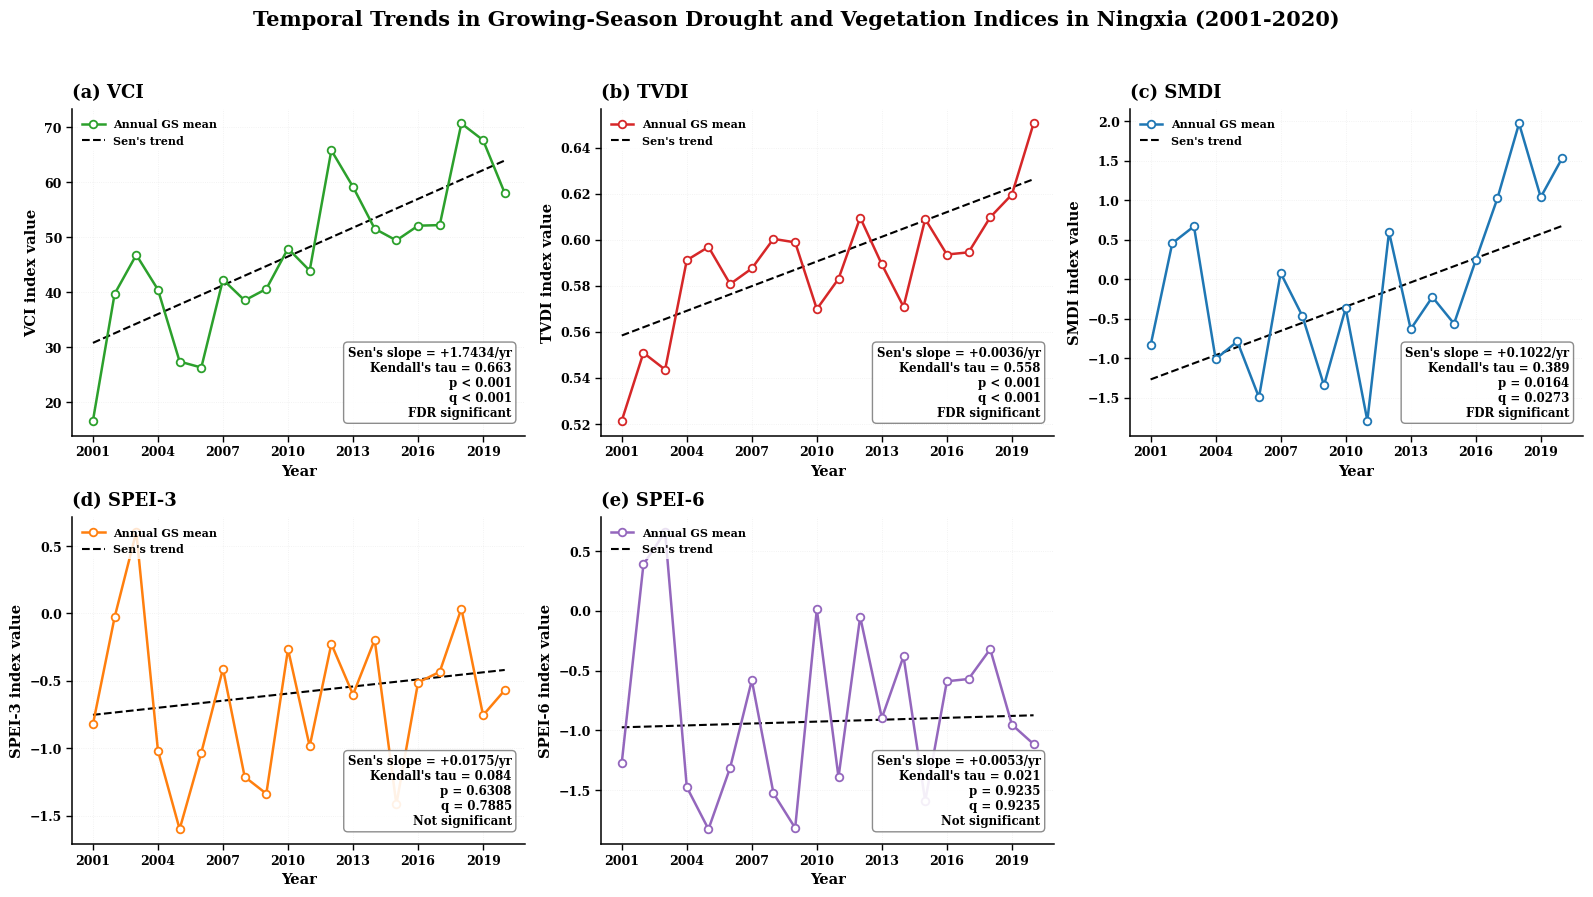


Regional summary saved:
E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Regional_Trend_Analysis_Summary_with_FDR.txt

##############################################################################
# PART B: SPATIAL PIXEL-WISE TREND ANALYSIS
##############################################################################

COMMON GRID
CRS: EPSG:4326
Resolution: 0.009
Dimensions: 396 x 476
Bounds: (104.20165081526194, 35.16337165300872, 107.76565081526194, 39.447371653008716)

PROCESSING: VCI

Preparing VCI
Available years: 20 | range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend: 100%|██████████████████████████████████████████████████████████████| 476/476 [00:35<00:00, 13.59it/s]



Summary: VCI
Index: VCI
Valid_Pixels: 66436
Mean_Sen_Slope: 1.869464415536176
Increasing_Area_Pct: 90.15194930591454
Decreasing_Area_Pct: 9.848050694085462
Raw_p_LT_0.05_Area_Pct: 72.04104801608214
FDR_Significant_Area_Pct: 69.50046197409455
FDR_Sig_Increasing_Area_Pct: 66.64057017157518
FDR_Sig_Decreasing_Area_Pct: 2.859891802519362
Median_Q_Value: 0.004677082411944866

PROCESSING: TVDI

Preparing TVDI
Available years: 20 | range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend: 100%|██████████████████████████████████████████████████████████████| 476/476 [00:39<00:00, 12.18it/s]



Summary: TVDI
Index: TVDI
Valid_Pixels: 66491
Mean_Sen_Slope: 0.0034957946702779694
Increasing_Area_Pct: 70.0308844862274
Decreasing_Area_Pct: 29.437230243144352
Raw_p_LT_0.05_Area_Pct: 40.36479455456505
FDR_Significant_Area_Pct: 27.75356628874398
FDR_Sig_Increasing_Area_Pct: 22.99690580471265
FDR_Sig_Decreasing_Area_Pct: 4.756660484031327
Median_Q_Value: 0.21304260194301605

PROCESSING: SMDI

Preparing SMDI
Available years: 20 | range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend: 100%|██████████████████████████████████████████████████████████████| 476/476 [00:37<00:00, 12.71it/s]



Summary: SMDI
Index: SMDI
Valid_Pixels: 66461
Mean_Sen_Slope: 0.09270691121506781
Increasing_Area_Pct: 99.17405792287893
Decreasing_Area_Pct: 0.8259420771210387
Raw_p_LT_0.05_Area_Pct: 49.5829541289997
FDR_Significant_Area_Pct: 12.41349147768368
FDR_Sig_Increasing_Area_Pct: 12.41349147768368
FDR_Sig_Decreasing_Area_Pct: 0.0
Median_Q_Value: 0.10625056177377701

PROCESSING: SPEI-3

Preparing SPEI-3
Available years: 20 | range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend: 100%|██████████████████████████████████████████████████████████████| 476/476 [00:37<00:00, 12.77it/s]



Summary: SPEI-3
Index: SPEI-3
Valid_Pixels: 66436
Mean_Sen_Slope: 0.013652206195590433
Increasing_Area_Pct: 96.74235146953716
Decreasing_Area_Pct: 3.2576485304628267
Raw_p_LT_0.05_Area_Pct: 0.0
FDR_Significant_Area_Pct: 0.0
FDR_Sig_Increasing_Area_Pct: 0.0
FDR_Sig_Decreasing_Area_Pct: 0.0
Median_Q_Value: 1.0

PROCESSING: SPEI-6

Preparing SPEI-6
Available years: 20 | range: 2001 - 2020
Minimum valid observations per pixel: 15


Pixel-wise trend: 100%|██████████████████████████████████████████████████████████████| 476/476 [00:37<00:00, 12.76it/s]



Summary: SPEI-6
Index: SPEI-6
Valid_Pixels: 66436
Mean_Sen_Slope: 0.007822159925402184
Increasing_Area_Pct: 77.10440727540485
Decreasing_Area_Pct: 22.895592724595126
Raw_p_LT_0.05_Area_Pct: 0.0
FDR_Significant_Area_Pct: 0.0
FDR_Sig_Increasing_Area_Pct: 0.0
FDR_Sig_Decreasing_Area_Pct: 0.0
Median_Q_Value: 1.0


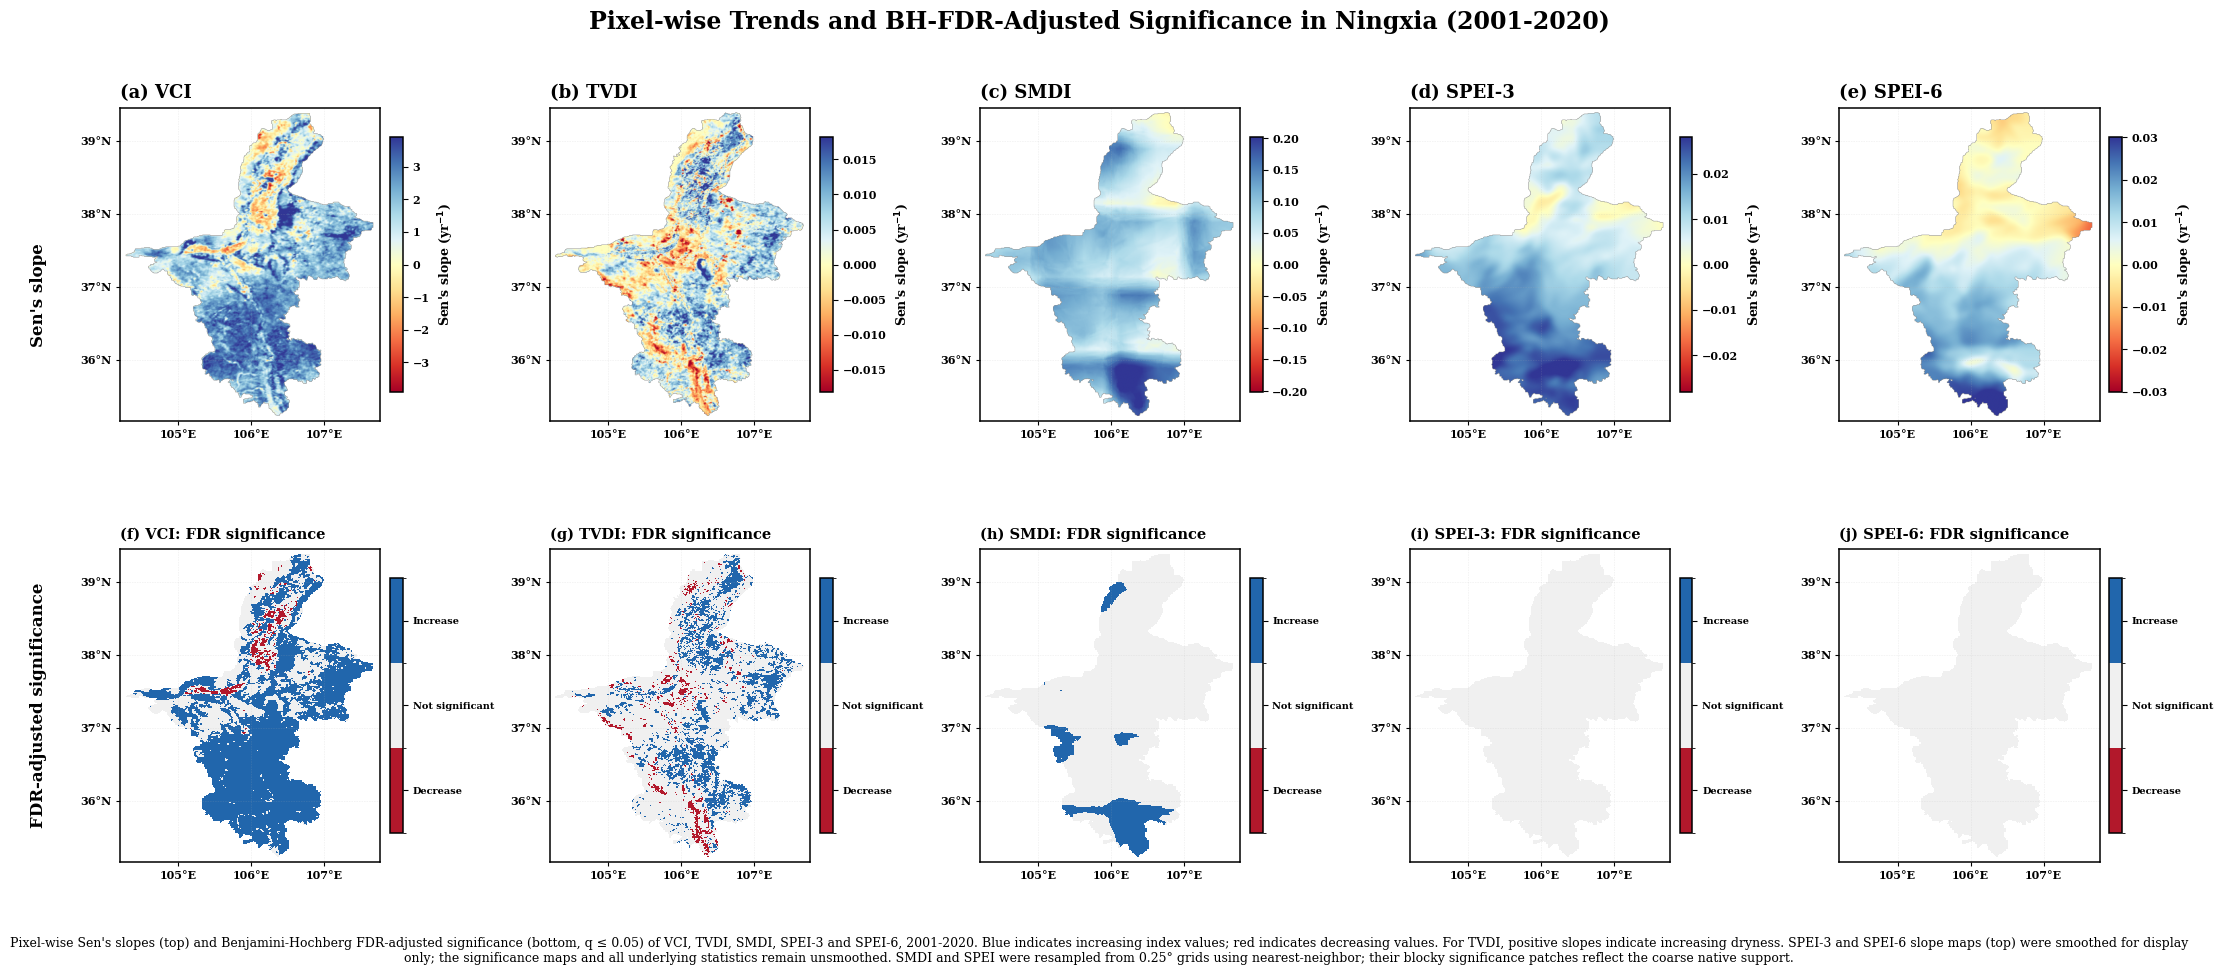


Figure saved: E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Spatio_pixelwise\Ningxia_Spatial_Trends_Sen_Slope_BH_FDR_FINAL.png

Spatial summary saved: E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Spatio_pixelwise\Ningxia_Spatio_Pixelwise_Trend_FDR_Summary.txt

COMBINED ANALYSIS COMPLETED

Output directory: E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined

Generated files:
  [Regional]   E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Ningxia_All_Indices_Timeseries_MK_Sen_FDR.png
  [Regional]   E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Annual_Growing_Season_Regional_Means.csv
  [Regional]   E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Regional_TimeSeries_MK_Sen_FDR_Results.csv
  [Regional]   E:\2_Contribution\Final\Preprocess\3. Trend\Update result\with FDR\Combined\Regional_Trend_Analysis_Summary_with_FDR.t

In [10]:
# =============================================================================
# COMBINED REGIONAL (TEMPORAL) + SPATIAL (PIXEL-WISE) TREND ANALYSIS
# Ningxia, China | 2001-2020 | Growing season April-October
# Indices: VCI, TVDI, SMDI, SPEI-3, SPEI-6
# Mann-Kendall + Sen's slope + Benjamini-Hochberg FDR (q <= 0.05)
# =============================================================================

import os
import re
import glob
import warnings

import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

from rasterio.warp import transform_bounds, reproject, Resampling
from rasterio.transform import from_origin

from scipy.ndimage import gaussian_filter
from scipy import stats
from scipy.stats import kendalltau, theilslopes
from matplotlib.colors import ListedColormap, BoundaryNorm
from tqdm import tqdm


# =============================================================================
# 1. PATHS AND GLOBAL SETTINGS
# =============================================================================

BASE_DIR = r"E:\2_Contribution\Final\Preprocess"

INDICES_DIRS = {
    "VCI":    os.path.join(BASE_DIR, "VCI"),
    "TVDI":   os.path.join(BASE_DIR, "TVDI"),
    "SMDI":   os.path.join(BASE_DIR, "SMDI"),
    "SPEI-3": os.path.join(BASE_DIR, "SPEI_3"),
    "SPEI-6": os.path.join(BASE_DIR, "SPEI_6"),
}

OUTPUT_DIR  = os.path.join(BASE_DIR, "3. Trend", "Update result", "with FDR", "Combined")
SPATIAL_DIR = os.path.join(OUTPUT_DIR, "Spatio_pixelwise")
os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(SPATIAL_DIR, exist_ok=True)

START_YEAR = 2001
END_YEAR   = 2020
GROWING_MONTHS = [4, 5, 6, 7, 8, 9, 10]

REQUIRE_ALL_MONTHS = True
ALPHA = 0.05

# --- spatial settings --------------------------------------------------------
TARGET_CRS = "EPSG:4326"
TARGET_RES = 0.009

MIN_VALID_YEARS    = 15
MIN_VALID_FRACTION = 0.75

# Turned ON to make SPEI slope maps smooth as requested
SMOOTH_SPEI_FOR_DISPLAY = True
SPEI_DISPLAY_SIGMA      = 4.0

LON_INTERVAL = 1.0
LAT_INTERVAL = 1.0

# Coarse resolution indices (0.25 deg) to apply nearest-neighbor resampling
COARSE_INDICES = ["SMDI", "SPEI-3", "SPEI-6"]

INDEX_ORDER = ["VCI", "TVDI", "SMDI", "SPEI-3", "SPEI-6"]

INDEX_LABELS_TS = {
    "VCI": "(a) VCI", "TVDI": "(b) TVDI", "SMDI": "(c) SMDI",
    "SPEI-3": "(d) SPEI-3", "SPEI-6": "(e) SPEI-6",
}

INDEX_COLORS = {
    "VCI": "#2ca02c", "TVDI": "#d62728", "SMDI": "#1f77b4",
    "SPEI-3": "#ff7f0e", "SPEI-6": "#9467bd",
}

PANEL_TOP    = ["(a) VCI", "(b) TVDI", "(c) SMDI", "(d) SPEI-3", "(e) SPEI-6"]
PANEL_BOTTOM = ["(f) VCI", "(g) TVDI", "(h) SMDI", "(i) SPEI-3", "(j) SPEI-6"]


# =============================================================================
# 2. FIGURE STYLE
# =============================================================================

plt.style.use("default")
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "axes.edgecolor": "black",
    "axes.linewidth": 1.1,
    "axes.labelcolor": "black", "text.color": "black", "axes.titlecolor": "black",
    "xtick.color": "black", "ytick.color": "black",
    "font.family": "serif", "font.size": 9, "font.weight": "bold",
    "axes.labelweight": "bold", "axes.titleweight": "bold",
    "savefig.dpi": 400,
})


def longitude_formatter(value, position):
    return f"{abs(value):.0f}\u00b0{'E' if value >= 0 else 'W'}"


def latitude_formatter(value, position):
    return f"{abs(value):.0f}\u00b0{'N' if value >= 0 else 'S'}"


# =============================================================================
# 3. BENJAMINI-HOCHBERG FDR
# =============================================================================

def benjamini_hochberg(p_values):
    p_values = np.asarray(p_values, dtype=np.float64)
    adjusted = np.full(p_values.shape, np.nan, dtype=np.float64)
    valid = np.isfinite(p_values)
    p = p_values[valid]
    if p.size == 0:
        return adjusted
    m = len(p)
    order = np.argsort(p)
    sorted_p = p[order]
    ranks = np.arange(1, m + 1, dtype=np.float64)
    q = sorted_p * m / ranks
    q = np.minimum.accumulate(q[::-1])[::-1]
    q = np.clip(q, 0, 1)
    restored = np.empty(m, dtype=np.float64)
    restored[order] = q
    adjusted[valid] = restored
    return adjusted


# =============================================================================
# 4. RASTER DISCOVERY / READING
# =============================================================================

def find_monthly_files(input_dir):
    files = glob.glob(os.path.join(input_dir, "*.tif"))
    monthly = {}
    for fp in files:
        filename = os.path.basename(fp)
        m = re.search(r"(20\d{2})[_-]?(\d{2})\.tif$", filename, flags=re.IGNORECASE)
        if not m:
            continue
        year, month = int(m.group(1)), int(m.group(2))
        if START_YEAR <= year <= END_YEAR and month in GROWING_MONTHS:
            key = (year, month)
            if key in monthly:
                raise ValueError(f"Duplicate monthly raster for {key}:\n"
                                 f"{monthly[key]}\n{fp}")
            monthly[key] = fp
    return monthly


def find_annual_tvdi_files(folder):
    candidate_dirs = [
        os.path.join(folder, "annaul"),
        os.path.join(folder, "annual"),
        os.path.join(folder, "Annual"),
        os.path.join(folder, "Annual_GS"),
        folder,
    ]
    annual_files = {}
    for candidate in candidate_dirs:
        if not os.path.isdir(candidate):
            continue
        for fp in glob.glob(os.path.join(candidate, "*.tif")):
            filename = os.path.basename(fp)
            m = re.search(r"TVDI_Ningxia_GS_(\d{4})\.tif$", filename, flags=re.IGNORECASE)
            if not m:
                m = re.search(r"(\d{4})\.tif$", filename, flags=re.IGNORECASE)
            if not m:
                continue
            year = int(m.group(1))
            if START_YEAR <= year <= END_YEAR and year not in annual_files:
                annual_files[year] = fp
    return annual_files


def read_raster(fp):
    with rasterio.open(fp) as src:
        data = src.read(1, masked=True).astype(np.float32).filled(np.nan)
        profile = {
            "crs": src.crs, "transform": src.transform,
            "width": src.width, "height": src.height, "nodata": src.nodata,
        }
    data[~np.isfinite(data)] = np.nan
    return data, profile


def check_same_grid(reference, current, filename):
    same = (
        reference["crs"] == current["crs"]
        and reference["transform"] == current["transform"]
        and reference["width"] == current["width"]
        and reference["height"] == current["height"]
    )
    if not same:
        raise ValueError(f"Raster grid mismatch detected:\n{filename}\n"
                         "Please align the raster grids before running this analysis.")


ANNUAL_TVDI_FILES = find_annual_tvdi_files(INDICES_DIRS["TVDI"])
if not ANNUAL_TVDI_FILES:
    warnings.warn("No annual TVDI rasters found - TVDI will be skipped.")


# =============================================================================
# PART A. REGIONAL TEMPORAL TRENDS
# =============================================================================

print("\n" + "#" * 78)
print("# PART A: REGIONAL TEMPORAL TREND ANALYSIS")
print("#" * 78)

annual_data = {}
annual_file_counts = {}

for index_name in INDEX_ORDER:

    input_dir = INDICES_DIRS[index_name]
    print("\n" + "=" * 70)
    print(f"Processing {index_name}")
    print(f"Input directory: {input_dir}")
    print("=" * 70)

    if not os.path.isdir(input_dir):
        warnings.warn(f"Directory not found for {index_name}: {input_dir}")
        continue

    annual_means = {}
    annual_counts = {}

    if index_name == "TVDI":
        if not ANNUAL_TVDI_FILES:
            continue
        for year in range(START_YEAR, END_YEAR + 1):
            if year not in ANNUAL_TVDI_FILES:
                print(f"  Missing TVDI annual raster: {year}")
                continue
            arr, _ = read_raster(ANNUAL_TVDI_FILES[year])
            arr[(arr < 0) | (arr > 1)] = np.nan
            if np.isfinite(arr).any():
                annual_means[year] = float(np.nanmean(arr))
                annual_counts[year] = 1
                print(f"  {year}: regional mean = {annual_means[year]:.5f}")
    else:
        monthly_files = find_monthly_files(input_dir)
        for year in range(START_YEAR, END_YEAR + 1):
            available_months = [m for m in GROWING_MONTHS if (year, m) in monthly_files]
            if REQUIRE_ALL_MONTHS and len(available_months) != 7:
                print(f"  Excluding {year}: only {len(available_months)}/7 months available")
                continue
            if len(available_months) == 0:
                print(f"  Excluding {year}: no monthly files available")
                continue

            arrays = []
            reference_profile = None
            for month in available_months:
                fp = monthly_files[(year, month)]
                arr, profile = read_raster(fp)
                if reference_profile is None:
                    reference_profile = profile
                else:
                    check_same_grid(reference_profile, profile, fp)
                arrays.append(arr)

            monthly_stack = np.stack(arrays, axis=0)

            if REQUIRE_ALL_MONTHS:
                valid_count = np.sum(np.isfinite(monthly_stack), axis=0)
                annual_raster = np.full(monthly_stack.shape[1:], np.nan, dtype=np.float32)
                valid_pixels = valid_count == 7
                annual_raster[valid_pixels] = np.nanmean(monthly_stack[:, valid_pixels], axis=0)
            else:
                annual_raster = np.nanmean(monthly_stack, axis=0)

            if not np.isfinite(annual_raster).any():
                print(f"  Excluding {year}: no valid annual pixels")
                continue

            regional_mean = float(np.nanmean(annual_raster))
            annual_means[year] = regional_mean
            annual_counts[year] = len(available_months)
            print(f"  {year}: {len(available_months)}/7 months; regional mean = {regional_mean:.5f}")

    if annual_means:
        sorted_years = sorted(annual_means.keys())
        annual_data[index_name] = {
            "years": np.array(sorted_years, dtype=int),
            "means": np.array([annual_means[y] for y in sorted_years], dtype=float),
        }
        annual_file_counts[index_name] = annual_counts
    else:
        print(f"WARNING: No usable annual data for {index_name}")


# --- 5. Save annual regional means ------------------------------------------
annual_records = []
for index_name, data in annual_data.items():
    for year, value in zip(data["years"], data["means"]):
        annual_records.append({"Index": index_name, "Year": int(year),
                               "Growing_Season_Mean": float(value)})

annual_df = pd.DataFrame(annual_records)
annual_csv = os.path.join(OUTPUT_DIR, "Annual_Growing_Season_Regional_Means.csv")
annual_df.to_csv(annual_csv, index=False, float_format="%.8f")
print(f"\nAnnual regional mean data saved:\n{annual_csv}")


# --- 6. Mann-Kendall + Sen's slope (regional) -------------------------------
trend_results = {}
for index_name in INDEX_ORDER:
    if index_name not in annual_data:
        continue
    years = annual_data[index_name]["years"]
    values = annual_data[index_name]["means"]
    valid = np.isfinite(years) & np.isfinite(values)
    years, values = years[valid], values[valid]
    if len(values) < 3:
        print(f"Insufficient observations for {index_name}")
        continue

    mk = stats.kendalltau(years, values, alternative="two-sided", method="auto")
    sen = stats.theilslopes(values, years, alpha=0.95, method="separate")

    trend_results[index_name] = {
        "n": len(values), "start_year": int(years.min()), "end_year": int(years.max()),
        "tau": float(mk.statistic),
        "sen_slope": float(sen.slope), "sen_intercept": float(sen.intercept),
        "low_slope": float(sen.low_slope), "high_slope": float(sen.high_slope),
        "p_raw": float(mk.pvalue), "years": years, "values": values,
    }


# --- 7. BH-FDR across the five regional tests -------------------------------
available_indices = list(trend_results.keys())
raw_p_values = [trend_results[n]["p_raw"] for n in available_indices]
adjusted_q = benjamini_hochberg(raw_p_values)

for name, q_value in zip(available_indices, adjusted_q):
    trend_results[name]["p_fdr"] = float(q_value)
    trend_results[name]["fdr_significant"] = bool(q_value < ALPHA)
    slope = trend_results[name]["sen_slope"]
    if q_value < ALPHA:
        trend_results[name]["fdr_direction"] = (
            "Significant increase" if slope > 0 else
            "Significant decrease" if slope < 0 else "No directional trend")
    else:
        trend_results[name]["fdr_direction"] = "Not significant"


# --- 8. Save regional table --------------------------------------------------
result_records = []
for name in INDEX_ORDER:
    if name not in trend_results:
        continue
    r = trend_results[name]
    result_records.append({
        "Index": name, "Number_of_Years": r["n"],
        "Start_Year": r["start_year"], "End_Year": r["end_year"],
        "Kendall_Tau": r["tau"], "Sen_Slope_per_Year": r["sen_slope"],
        "Sen_Slope_CI_Lower": r["low_slope"], "Sen_Slope_CI_Upper": r["high_slope"],
        "Original_MK_p_value": r["p_raw"],
        "BH_FDR_adjusted_p_value": r["p_fdr"],
        "FDR_Significant": r["fdr_significant"],
        "Trend_Direction": r["fdr_direction"],
    })
results_df = pd.DataFrame(result_records)
results_csv = os.path.join(OUTPUT_DIR, "Regional_TimeSeries_MK_Sen_FDR_Results.csv")
results_df.to_csv(results_csv, index=False, float_format="%.8f")


# --- 9. Regional time-series figure -----------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9), facecolor="white")
axes = axes.flatten()

for idx, index_name in enumerate(INDEX_ORDER):
    ax = axes[idx]
    if index_name not in trend_results:
        ax.axis("off")
        continue
    r = trend_results[index_name]
    years, values = r["years"], r["values"]
    fitted = r["sen_slope"] * years + r["sen_intercept"]

    ax.plot(years, values, marker="o", color=INDEX_COLORS[index_name],
            linewidth=1.8, markersize=5.5, markerfacecolor="white",
            markeredgewidth=1.3, label="Annual GS mean", zorder=3)
    ax.plot(years, fitted, linestyle="--", color="black",
            linewidth=1.5, label="Sen's trend", zorder=2)

    sig_label = "FDR significant" if r["p_fdr"] < ALPHA else "Not significant"
    
    # Format p and q values correctly
    p_str = "< 0.001" if r["p_raw"] < 0.001 else f"= {r['p_raw']:.4f}"
    q_str = "< 0.001" if r["p_fdr"] < 0.001 else f"= {r['p_fdr']:.4f}"
    
    annotation = (f"Sen's slope = {r['sen_slope']:+.4f}/yr\n"
                  f"Kendall's tau = {r['tau']:.3f}\n"
                  f"p {p_str}\n"
                  f"q {q_str}\n"
                  f"{sig_label}")
                  
    # Moved to bottom right to avoid overlapping the early peaks
    ax.text(0.97, 0.05, annotation, transform=ax.transAxes, va="bottom", ha="right",
            fontsize=8.5,
            bbox={"boxstyle": "round,pad=0.35", "facecolor": "white",
                  "edgecolor": "gray", "alpha": 0.9})

    ax.set_title(INDEX_LABELS_TS[index_name], fontsize=13, fontweight="bold",
                 loc="left", pad=8)
    ax.set_xlabel("Year", fontsize=10.5, fontweight="bold")
    ax.set_ylabel(f"{index_name} index value", fontsize=10.5, fontweight="bold")
    ax.set_xticks(np.arange(START_YEAR, END_YEAR + 1, 3))
    ax.tick_params(axis="both", labelsize=9, width=1.0, length=4)
    ax.grid(alpha=0.20, linestyle=":", linewidth=0.6)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.legend(frameon=True, facecolor="white", edgecolor="none",
              fontsize=8, loc="upper left") # Moved legend to top left to avoid text box

axes[5].axis("off")
fig.suptitle("Temporal Trends in Growing-Season Drought and Vegetation Indices "
             "in Ningxia (2001-2020)",
             fontsize=15, fontweight="bold", y=0.99)
plt.tight_layout(rect=[0, 0, 1, 0.96])
ts_figure = os.path.join(OUTPUT_DIR, "Ningxia_All_Indices_Timeseries_MK_Sen_FDR.png")
plt.savefig(ts_figure, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()


# --- 10. Regional summary text ----------------------------------------------
summary_ts_path = os.path.join(OUTPUT_DIR, "Regional_Trend_Analysis_Summary_with_FDR.txt")
with open(summary_ts_path, "w", encoding="utf-8") as f:
    f.write("=" * 90 + "\n")
    f.write("REGIONAL TEMPORAL TREND ANALYSIS: NINGXIA, CHINA\n")
    f.write("=" * 90 + "\n\n")
    f.write("Study period: 2001-2020\nGrowing season: April-October\n")
    f.write("Indices: VCI, TVDI, SMDI, SPEI-3, SPEI-6\n\n")
    f.write("ANALYTICAL PROCEDURE\n" + "-" * 90 + "\n")
    f.write("1. Monthly raster data were aggregated into annual April-October growing-season means.\n")
    f.write("2. For monthly indices, annual growing-season values were calculated pixel by pixel before computing the regional mean.\n")
    f.write("3. Only years with all seven growing-season monthly rasters were retained.\n")
    f.write("4. TVDI was analysed using the existing annual growing-season rasters (TVDI_Ningxia_GS_YYYY.tif), clipped to [0, 1].\n")
    f.write("5. Monotonic temporal trends were evaluated using Kendall's tau (two-sided Mann-Kendall test).\n")
    f.write("6. Trend magnitude was estimated using Sen's slope in index units per year.\n")
    f.write("7. Benjamini-Hochberg FDR correction was applied across the available regional index-level p-values (one family of tests).\n\n")
    f.write("STATISTICAL RESULTS\n" + "-" * 90 + "\n\n")
    f.write(f"{'Index':<10}{'N':>5}{'Tau':>11}{'Sen slope/yr':>16}"
            f"{'Raw p':>13}{'FDR q':>13}{'FDR result':>22}\n")
    f.write("-" * 90 + "\n")
    for name in INDEX_ORDER:
        if name not in trend_results:
            f.write(f"{name:<10} No valid data available\n"); continue
        r = trend_results[name]
        f.write(f"{name:<10}{r['n']:>5d}{r['tau']:>11.4f}{r['sen_slope']:>16.6f}"
                f"{r['p_raw']:>13.6f}{r['p_fdr']:>13.6f}{r['fdr_direction']:>22}\n")
    f.write("\n" + "=" * 90 + "\nINTERPRETATION AND STATISTICAL NOTES\n" + "=" * 90 + "\n\n")
    f.write("A positive Sen's slope indicates an increasing index value over time, whereas a "
            "negative slope indicates a decreasing index value. The ecological or drought "
            "interpretation depends on the index definition (for TVDI, a positive slope "
            "indicates increasing dryness).\n\n")
    f.write("Original p-values are reported alongside BH-FDR adjusted q-values. Regional "
            "index-level statistical significance is determined using q < 0.05.\n\n")
    f.write("The BH correction in this file applies only to the regional time-series tests for "
            "the available indices. It does not replace the separate pixel-wise BH-FDR "
            "correction required for spatial trend maps.\n\n")
    f.write("The Mann-Kendall test evaluates monotonic association with time. Serial "
            "autocorrelation can affect its nominal significance; this analysis does not "
            "apply a separate autocorrelation correction.\n\n")
    f.write("The regional mean is calculated as an unweighted mean of valid raster pixels. "
            "It is not an area-weighted regional estimate. If the raster is in geographic "
            "coordinates, pixel areas vary with latitude.\n\n")
    f.write("The reported results describe regional index behaviour and should not be "
            "interpreted as independent ground validation of the underlying drought products.\n")
    f.write("\n" + "=" * 90 + "\nEND OF SUMMARY\n" + "=" * 90 + "\n")
print(f"\nRegional summary saved:\n{summary_ts_path}")


# =============================================================================
# PART B. SPATIAL PIXEL-WISE TRENDS
# =============================================================================

print("\n" + "#" * 78)
print("# PART B: SPATIAL PIXEL-WISE TREND ANALYSIS")
print("#" * 78)


# --- 11. Common reference grid ----------------------------------------------
def create_reference_grid(vci_folder):
    vci_files = find_monthly_files(vci_folder)
    if not vci_files:
        raise FileNotFoundError("Monthly VCI files were not found.")

    first_key = min(vci_files.keys())
    first_fp = vci_files[first_key]

    with rasterio.open(first_fp) as src:
        source_crs = src.crs if src.crs else TARGET_CRS
        left, bottom, right, top = transform_bounds(
            source_crs, TARGET_CRS, *src.bounds, densify_pts=21)

    left -= 0.05; right += 0.05; bottom -= 0.05; top += 0.05
    width  = int(np.ceil((right - left) / TARGET_RES))
    height = int(np.ceil((top - bottom) / TARGET_RES))

    transform = from_origin(left, top, TARGET_RES, TARGET_RES)
    actual_right  = left + width * TARGET_RES
    actual_bottom = top - height * TARGET_RES
    bounds = (left, actual_bottom, actual_right, top)

    print("\nCOMMON GRID")
    print("CRS:", TARGET_CRS)
    print("Resolution:", TARGET_RES)
    print("Dimensions:", width, "x", height)
    print("Bounds:", bounds)
    return transform, width, height, bounds


# --- 12. Reproject ----------------------------------------------------------
def load_and_reproject(filepath, ref_transform, ref_width, ref_height, resampling_method):
    with rasterio.open(filepath) as src:
        source = src.read(1).astype(np.float32)
        if src.nodata is not None:
            source[source == src.nodata] = np.nan
        source[~np.isfinite(source)] = np.nan

        source_crs = src.crs if src.crs else TARGET_CRS
        destination = np.full((ref_height, ref_width), np.nan, dtype=np.float32)

        reproject(
            source=source, destination=destination,
            src_transform=src.transform, src_crs=source_crs,
            src_nodata=np.nan,
            dst_transform=ref_transform, dst_crs=TARGET_CRS,
            dst_nodata=np.nan,
            resampling=resampling_method,
        )
    return destination


# --- 13. Build annual stack -------------------------------------------------
def build_annual_stack(index_name, input_folder,
                       ref_transform, ref_width, ref_height):
    print(f"\nPreparing {index_name}")
    annual_data_stack = {}
    missing_years = []
    
    # Use Nearest Neighbor for coarse indices to avoid fake circular artifacts
    resample_method = Resampling.nearest if index_name in COARSE_INDICES else Resampling.bilinear

    if index_name == "TVDI":
        for year in range(START_YEAR, END_YEAR + 1):
            if year not in ANNUAL_TVDI_FILES:
                missing_years.append(year)
                continue
            arr = load_and_reproject(ANNUAL_TVDI_FILES[year],
                                     ref_transform, ref_width, ref_height,
                                     resample_method)
            arr[(arr < 0) | (arr > 1)] = np.nan
            annual_data_stack[year] = arr
    else:
        monthly_files = find_monthly_files(input_folder)
        for year in range(START_YEAR, END_YEAR + 1):
            month_dict = {
                m: monthly_files[(year, m)]
                for m in GROWING_MONTHS
                if (year, m) in monthly_files
            }
            available_months = sorted(month_dict.keys())

            if REQUIRE_ALL_MONTHS:
                if not all(m in available_months for m in GROWING_MONTHS):
                    missing_years.append(year); continue
            elif len(available_months) == 0:
                missing_years.append(year); continue

            selected = [month_dict[m] for m in GROWING_MONTHS if m in month_dict]
            arrays = [load_and_reproject(fp, ref_transform, ref_width, ref_height,
                                         resample_method)
                      for fp in selected]
            monthly_stack = np.stack(arrays, axis=0)

            with warnings.catch_warnings():
                warnings.simplefilter("ignore", RuntimeWarning)
                annual_mean = np.nanmean(monthly_stack, axis=0)

            if REQUIRE_ALL_MONTHS:
                valid_month_count = np.sum(np.isfinite(monthly_stack), axis=0)
                annual_mean[valid_month_count != len(GROWING_MONTHS)] = np.nan

            annual_data_stack[year] = annual_mean

    years = sorted(annual_data_stack.keys())
    if len(years) < MIN_VALID_YEARS:
        raise ValueError(f"{index_name}: only {len(years)} valid years; "
                         f"minimum required {MIN_VALID_YEARS}.")

    stack = np.stack([annual_data_stack[y] for y in years], axis=0)
    print("Available years:", len(years), "| range:", years[0], "-", years[-1])
    if missing_years:
        print("Missing years:", missing_years)
    return np.asarray(years, dtype=np.float64), stack


# --- 14. Pixel-wise Mann-Kendall + Sen's slope ------------------------------
def calculate_pixelwise_trends(years, stack):
    n_years, height, width = stack.shape
    slope_map  = np.full((height, width), np.nan, dtype=np.float32)
    pvalue_map = np.full((height, width), np.nan, dtype=np.float32)

    required_valid = max(MIN_VALID_YEARS,
                         int(np.ceil(n_years * MIN_VALID_FRACTION)))
    print("Minimum valid observations per pixel:", required_valid)

    for row in tqdm(range(height), desc="Pixel-wise trend"):
        for col in range(width):
            values = stack[:, row, col]
            valid = np.isfinite(values)
            if np.sum(valid) < required_valid:
                continue
            vy, vv = years[valid], values[valid]
            try:
                _, p_value = kendalltau(vy, vv)
                if not np.isfinite(p_value):
                    continue
                pvalue_map[row, col] = p_value
                slope = theilslopes(vv, vy).slope
                if np.isfinite(slope):
                    slope_map[row, col] = slope
            except Exception:
                continue
    return slope_map, pvalue_map


# --- 15. Pixel-wise BH-FDR --------------------------------------------------
def apply_pixelwise_fdr(slope_map, pvalue_map):
    valid = np.isfinite(slope_map) & np.isfinite(pvalue_map)
    qvalue_map = np.full(pvalue_map.shape, np.nan, dtype=np.float32)
    qvalue_map[valid] = benjamini_hochberg(pvalue_map[valid]).astype(np.float32)

    significance_map = np.full(slope_map.shape, np.nan, dtype=np.float32)
    significance_map[valid] = 0
    significant = valid & (qvalue_map <= ALPHA)
    significance_map[significant & (slope_map > 0)] = 1
    significance_map[significant & (slope_map < 0)] = -1
    return qvalue_map, significance_map


# --- 16. Display-only smoothing (kept, default OFF) -------------------------
def smooth_for_display(array, sigma):
    valid = np.isfinite(array)
    if not np.any(valid):
        return array.copy()
    values = np.where(valid, array, 0.0)
    weights = valid.astype(np.float32)
    numerator   = gaussian_filter(values,  sigma=sigma, mode="nearest")
    denominator = gaussian_filter(weights, sigma=sigma, mode="nearest")
    result = np.full(array.shape, np.nan, dtype=np.float32)
    good = denominator > 1e-6
    result[good] = numerator[good] / denominator[good]
    result[~valid] = np.nan
    return result


# --- 17. Area-weighted summary (with RAW p column) --------------------------
def calculate_summary(index_name, slope_map, pvalue_map,
                      qvalue_map, significance_map, bounds):
    valid = np.isfinite(slope_map) & np.isfinite(qvalue_map)
    if not np.any(valid):
        return None

    slopes   = slope_map[valid]
    q_values = qvalue_map[valid]
    p_values = pvalue_map[valid]

    top = bounds[3]
    height = slope_map.shape[0]
    latitudes = top - (np.arange(height) + 0.5) * TARGET_RES
    row_weights = np.cos(np.deg2rad(latitudes))
    weights = np.broadcast_to(row_weights[:, None], slope_map.shape)[valid]
    total_weight = np.sum(weights)

    mean_slope = np.sum(slopes * weights) / total_weight

    significant     = q_values <= ALPHA
    raw_significant = p_values <  ALPHA
    increasing = slopes > 0
    decreasing = slopes < 0

    def wpct(mask):
        return float(100 * np.sum(weights[mask]) / total_weight)

    return {
        "Index": index_name,
        "Valid_Pixels": int(np.sum(valid)),
        "Mean_Sen_Slope": float(mean_slope),
        "Increasing_Area_Pct": wpct(increasing),
        "Decreasing_Area_Pct": wpct(decreasing),
        "Raw_p_LT_0.05_Area_Pct": wpct(raw_significant),
        "FDR_Significant_Area_Pct": wpct(significant),
        "FDR_Sig_Increasing_Area_Pct": wpct(significant & increasing),
        "FDR_Sig_Decreasing_Area_Pct": wpct(significant & decreasing),
        "Median_Q_Value": float(np.nanmedian(q_values)),
    }


# --- 18. GeoTIFF writer -----------------------------------------------------
def save_geotiff(filepath, array, ref_transform, ref_width, ref_height):
    nodata = -9999.0
    output_array = np.where(np.isfinite(array), array, nodata).astype(np.float32)
    profile = {
        "driver": "GTiff", "height": ref_height, "width": ref_width,
        "count": 1, "dtype": "float32", "crs": TARGET_CRS,
        "transform": ref_transform, "nodata": nodata, "compress": "lzw",
    }
    with rasterio.open(filepath, "w", **profile) as dst:
        dst.write(output_array, 1)


# --- 19. Run spatial processing ---------------------------------------------
ref_transform, ref_width, ref_height, bounds = create_reference_grid(INDICES_DIRS["VCI"])

spatial_results = {}
spatial_summary = []

for index_name, input_folder in INDICES_DIRS.items():
    print("\n" + "=" * 70)
    print("PROCESSING:", index_name)
    print("=" * 70)

    if index_name == "TVDI" and not ANNUAL_TVDI_FILES:
        print("No annual TVDI rasters available - skipping TVDI.")
        continue

    years, stack = build_annual_stack(index_name, input_folder,
                                      ref_transform, ref_width, ref_height)
    slope_map, pvalue_map     = calculate_pixelwise_trends(years, stack)
    qvalue_map, significance_map = apply_pixelwise_fdr(slope_map, pvalue_map)

    summary = calculate_summary(index_name, slope_map, pvalue_map,
                                qvalue_map, significance_map, bounds)
    if summary is None:
        print("No valid pixels:", index_name); continue

    spatial_results[index_name] = {
        "slope": slope_map, "pvalue": pvalue_map,
        "qvalue": qvalue_map, "significance": significance_map,
    }
    spatial_summary.append(summary)

    save_geotiff(os.path.join(SPATIAL_DIR, f"{index_name}_Sen_Slope.tif"),
                 slope_map, ref_transform, ref_width, ref_height)
    save_geotiff(os.path.join(SPATIAL_DIR, f"{index_name}_FDR_qvalue.tif"),
                 qvalue_map, ref_transform, ref_width, ref_height)
    save_geotiff(os.path.join(SPATIAL_DIR, f"{index_name}_FDR_Significance.tif"),
                 significance_map, ref_transform, ref_width, ref_height)

    print("\nSummary:", index_name)
    for k, v in summary.items():
        print(f"{k}: {v}")


# --- 20. Spatial figure -----------------------------------------------------
left, bottom, right, top = bounds
extent = [left, right, bottom, top]

sig_cmap = ListedColormap(["#B2182B", "#F0F0F0", "#2166AC"])
sig_norm = BoundaryNorm([-1.5, -0.5, 0.5, 1.5], sig_cmap.N)

fig, axes = plt.subplots(2, 5, figsize=(22, 10), facecolor="white")
fig.subplots_adjust(left=0.055, right=0.965, bottom=0.10, top=0.88,
                    wspace=0.52, hspace=0.30)

for col, index_name in enumerate(INDEX_ORDER):
    ax_slope = axes[0, col]
    ax_sig   = axes[1, col]

    if index_name not in spatial_results:
        ax_slope.axis("off"); ax_sig.axis("off"); continue

    slope_map        = spatial_results[index_name]["slope"]
    significance_map = spatial_results[index_name]["significance"]

    display_slope = slope_map.copy()
    if index_name in ("SPEI-3", "SPEI-6") and SMOOTH_SPEI_FOR_DISPLAY:
        display_slope = smooth_for_display(slope_map, sigma=SPEI_DISPLAY_SIGMA)

    valid_values = display_slope[np.isfinite(display_slope)]
    if valid_values.size == 0:
        ax_slope.axis("off"); ax_sig.axis("off"); continue

    max_abs = np.nanpercentile(np.abs(valid_values), 98)
    if not np.isfinite(max_abs) or max_abs == 0:
        max_abs = 0.05

    im1 = ax_slope.imshow(display_slope, cmap="RdYlBu",
                          vmin=-max_abs, vmax=max_abs,
                          extent=extent, origin="upper",
                          interpolation="bilinear", aspect="equal")
    ax_slope.set_title(PANEL_TOP[col], fontsize=13, fontweight="bold",
                       loc="left", pad=7)
    cb1 = fig.colorbar(im1, ax=ax_slope, orientation="vertical",
                       fraction=0.045, pad=0.035, shrink=0.88)
    cb1.set_label("Sen's slope (yr$^{-1}$)", fontsize=9,
                  fontweight="bold", labelpad=5)
    cb1.ax.tick_params(labelsize=8)

    # Use 'nearest' interpolation for significance map to keep grid cells crisp
    im2 = ax_sig.imshow(significance_map, cmap=sig_cmap, norm=sig_norm,
                        extent=extent, origin="upper",
                        interpolation="nearest", aspect="equal")
    ax_sig.set_title(PANEL_BOTTOM[col] + ": FDR significance",
                     fontsize=10.5, fontweight="bold", loc="left", pad=7)
    cb2 = fig.colorbar(im2, ax=ax_sig, orientation="vertical",
                       fraction=0.045, pad=0.035, shrink=0.88,
                       ticks=[-1, 0, 1])
    cb2.ax.set_yticklabels(["Decrease", "Not significant", "Increase"])
    cb2.ax.tick_params(labelsize=7)

    for ax in (ax_slope, ax_sig):
        ax.set_xlim(left, right); ax.set_ylim(bottom, top)
        ax.xaxis.set_major_locator(mticker.MultipleLocator(LON_INTERVAL))
        ax.yaxis.set_major_locator(mticker.MultipleLocator(LAT_INTERVAL))
        ax.xaxis.set_major_formatter(mticker.FuncFormatter(longitude_formatter))
        ax.yaxis.set_major_formatter(mticker.FuncFormatter(latitude_formatter))
        ax.tick_params(axis="both", which="major", labelsize=8,
                       width=0.8, length=3, pad=3)
        ax.grid(visible=True, linestyle=":", linewidth=0.45, alpha=0.35)
        for lbl in (ax.get_xticklabels() + ax.get_yticklabels()):
            lbl.set_fontweight("bold")
        ax.set_aspect("equal", adjustable="box")

fig.text(0.018, 0.68, "Sen's slope", rotation=90, va="center", ha="center",
         fontsize=12, fontweight="bold")
fig.text(0.018, 0.27, "FDR-adjusted significance", rotation=90,
         va="center", ha="center", fontsize=12, fontweight="bold")

fig.suptitle("Pixel-wise Trends and BH-FDR-Adjusted Significance in Ningxia "
             "(2001-2020)",
             fontsize=17, fontweight="bold", y=0.965)

# UPDATED CAPTION TO EXPLICITLY MENTION SMOOTHING
fig.text(
    0.5, 0.015,
    "Pixel-wise Sen's slopes (top) and Benjamini-Hochberg FDR-adjusted significance "
    "(bottom, q \u2264 0.05) of VCI, TVDI, SMDI, SPEI-3 and SPEI-6, 2001-2020. "
    "Blue indicates increasing index values; red indicates decreasing values. "
    "For TVDI, positive slopes indicate increasing dryness. "
    "SPEI-3 and SPEI-6 slope maps (top) were smoothed for display only; "
    "the significance maps and all underlying statistics remain unsmoothed. "
    "SMDI and SPEI were resampled from 0.25\u00b0 grids using nearest-neighbor; "
    "their blocky significance patches reflect the coarse native support.",
    ha="center", fontsize=9, fontweight="normal", wrap=True)

spatial_figure = os.path.join(
    SPATIAL_DIR, "Ningxia_Spatial_Trends_Sen_Slope_BH_FDR_FINAL.png")
plt.savefig(spatial_figure, dpi=400, bbox_inches="tight", facecolor="white")
plt.show()
plt.close()
print("\nFigure saved:", spatial_figure)


# --- 21. Spatial summary text ----------------------------------------------
summary_sp_path = os.path.join(
    SPATIAL_DIR, "Ningxia_Spatio_Pixelwise_Trend_FDR_Summary.txt")

with open(summary_sp_path, "w", encoding="utf-8") as file:
    file.write("=" * 130 + "\n")
    file.write("SPATIAL PIXEL-WISE TREND ANALYSIS AND BH-FDR SUMMARY\n")
    file.write("Ningxia, China | 2001-2020 | April-October\n")
    file.write("=" * 130 + "\n\n")

    file.write("METHODOLOGY\n" + "-" * 130 + "\n")
    file.write("Annual growing-season means were calculated from April to October. "
               "Pixel-wise trends were evaluated using the Mann-Kendall test, and "
               "trend magnitudes were estimated using Sen's slope.\n\n")
    file.write("Benjamini-Hochberg false discovery rate correction was applied "
               "separately to valid pixel-wise p-values for each index. Significance "
               "was determined using q <= 0.05. Raw p < 0.05 shares are reported "
               "from the same run.\n\n")
    file.write(f"Minimum valid observations: {MIN_VALID_YEARS} years, and "
               f"{MIN_VALID_FRACTION*100:.0f}% of available years.\n\n")
    file.write("All percentages are cos(latitude)-weighted shares of valid area "
               "(\"% of area\"), not raw pixel counts. Pixel counts differ by index "
               "because each index has its own valid-pixel mask, and they differ "
               "from the Chapter 3 pixel set (a different mask).\n\n")
    if SMOOTH_SPEI_FOR_DISPLAY:
        file.write(f"NOTE: SPEI slope maps were visually smoothed (sigma = "
                   f"{SPEI_DISPLAY_SIGMA}) for display only. Analytical slope "
                   "rasters, p-values, q-values, significance maps and summary "
                   "statistics were NOT smoothed.\n\n")
    else:
        file.write("NOTE: No visual smoothing was applied to any slope map "
                   "(including SPEI). Analytical and displayed rasters are identical.\n\n")

    file.write("SUMMARY TABLE\n" + "-" * 130 + "\n")
    file.write(f"{'Index':<12}{'Pixels':>10}{'Mean slope':>14}"
               f"{'Increasing':>12}{'Decreasing':>12}"
               f"{'Raw p<0.05':>12}{'FDR sig.':>11}"
               f"{'Sig. incr.':>12}{'Sig. decr.':>12}\n")
    file.write("-" * 130 + "\n")
    for item in spatial_summary:
        file.write(
            f"{item['Index']:<12}{item['Valid_Pixels']:>10}"
            f"{item['Mean_Sen_Slope']:>14.6f}"
            f"{item['Increasing_Area_Pct']:>11.2f}%"
            f"{item['Decreasing_Area_Pct']:>11.2f}%"
            f"{item['Raw_p_LT_0.05_Area_Pct']:>11.2f}%"
            f"{item['FDR_Significant_Area_Pct']:>10.2f}%"
            f"{item['FDR_Sig_Increasing_Area_Pct']:>11.2f}%"
            f"{item['FDR_Sig_Decreasing_Area_Pct']:>11.2f}%\n")

    file.write("\nINTERPRETATION\n" + "-" * 130 + "\n")
    file.write("Positive Sen's slopes indicate increasing index values; negative "
               "slopes indicate decreasing values. For TVDI, a positive slope "
               "indicates increasing dryness. The FDR significance map identifies "
               "pixels that remain statistically significant after multiple-testing "
               "correction.\n\n")
    file.write("BH-FDR correction does not eliminate spatial autocorrelation. "
               "This limitation should be acknowledged when interpreting pixel-wise "
               "significance patterns. The pixel-wise Mann-Kendall test is also not "
               "adjusted for serial correlation (unlike the Hamed-Rao test used in "
               "Chapter 3), so the significant shares should be treated as somewhat "
               "generous.\n\n")
    file.write("SMDI and SPEI have coarser native spatial resolutions than the "
               "common output grid. Resampling was performed using nearest-neighbor "
               "to preserve original grid cells; their patterns should be interpreted "
               "according to their native spatial support.\n")
    file.write("\n" + "=" * 130 + "\nEND OF SUMMARY\n" + "=" * 130 + "\n")

print("\nSpatial summary saved:", summary_sp_path)


# =============================================================================
# 22. FINAL REPORT
# =============================================================================

print("\n" + "=" * 80)
print("COMBINED ANALYSIS COMPLETED")
print("=" * 80)
print("\nOutput directory:", OUTPUT_DIR)
print("\nGenerated files:")
print("  [Regional]  ", ts_figure)
print("  [Regional]  ", annual_csv)
print("  [Regional]  ", results_csv)
print("  [Regional]  ", summary_ts_path)
print("  [Spatial]   ", spatial_figure)
print("  [Spatial]   ", summary_sp_path)
print("  [Spatial]    per-index Sen slope / q-value / significance GeoTIFFs")
print("\nRegional summary:\n", results_df.to_string(index=False))
print("\nSpatial summary:\n", pd.DataFrame(spatial_summary).to_string(index=False))
print("=" * 80)

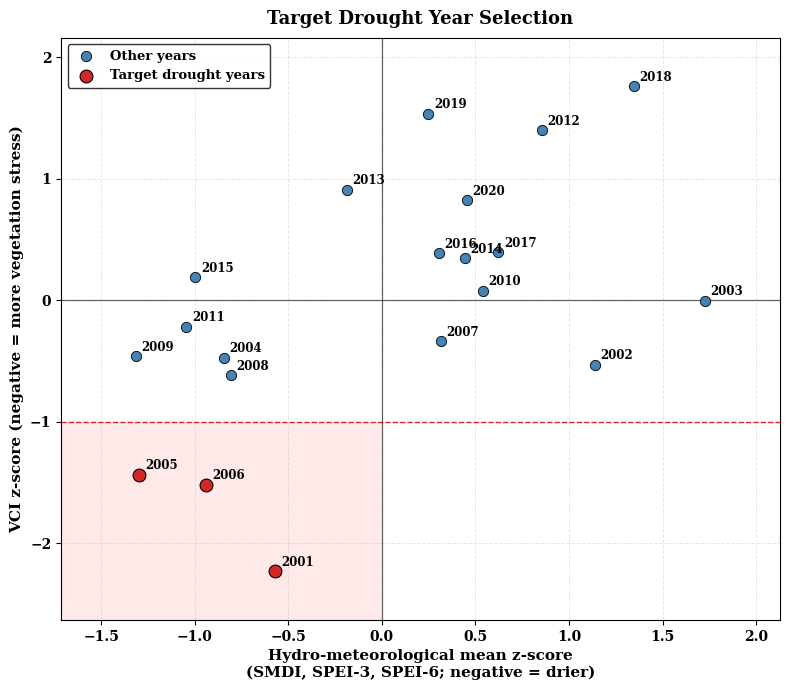

Scatter figure saved to: E:\2_Contribution\Final\Preprocess\3. Trend\Selection_Scatter_VCI_vs_Hydro.png


In [4]:
from matplotlib.patches import Rectangle

hydro_mean = np.mean([z_orig['SMDI'], z_orig['SPEI-3'], z_orig['SPEI-6']], axis=0)
vci = z_orig['VCI']

fig, ax = plt.subplots(figsize=(8, 7), facecolor='white')

x_min, x_max = hydro_mean.min() - 0.4, hydro_mean.max() + 0.4
y_min, y_max = vci.min() - 0.4, vci.max() + 0.4
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_min, y_max)

# Selection region: hydro-meteorological mean < 0 AND VCI z <= -1
ax.add_patch(Rectangle((x_min, y_min), 0 - x_min, VCI_Z_THR - y_min,
                       facecolor='#ff4d4d', alpha=0.12, zorder=1))
ax.axhline(VCI_Z_THR, color='#d62728', linestyle='--', linewidth=1.0, zorder=2)
ax.axvline(0, color='black', linewidth=0.9, alpha=0.6, zorder=2)
ax.axhline(0, color='black', linewidth=0.9, alpha=0.6, zorder=2)

is_t = np.isin(years_arr, TARGET_YEARS)
ax.scatter(hydro_mean[~is_t], vci[~is_t], s=55, color='#4682b4',
           edgecolor='black', linewidth=0.6, zorder=3, label='Other years')
ax.scatter(hydro_mean[is_t], vci[is_t], s=85, color='#d62728',
           edgecolor='black', linewidth=0.8, zorder=4, label='Target drought years')

for yr, xv, yv in zip(years_arr, hydro_mean, vci):
    ax.annotate(str(yr), (xv, yv), xytext=(4, 4), textcoords='offset points',
                fontsize=8.5, fontweight='bold', zorder=5)

ax.set_xlabel('Hydro-meteorological mean z-score\n(SMDI, SPEI-3, SPEI-6; negative = drier)',
              fontsize=11, fontweight='bold')
ax.set_ylabel('VCI z-score (negative = more vegetation stress)',
              fontsize=11, fontweight='bold')
ax.set_title('Target Drought Year Selection', fontsize=13, fontweight='bold', pad=10)
ax.grid(alpha=0.3, linestyle='--', linewidth=0.7, zorder=0)
ax.legend(loc='upper left', frameon=True, edgecolor='black', fontsize=9.5)

fig.tight_layout()
out_sc = os.path.join(FIG_DIR, 'Selection_Scatter_VCI_vs_Hydro.png')
fig.savefig(out_sc, bbox_inches='tight', dpi=400, facecolor='white')
plt.show()
print(f"Scatter figure saved to: {out_sc}")

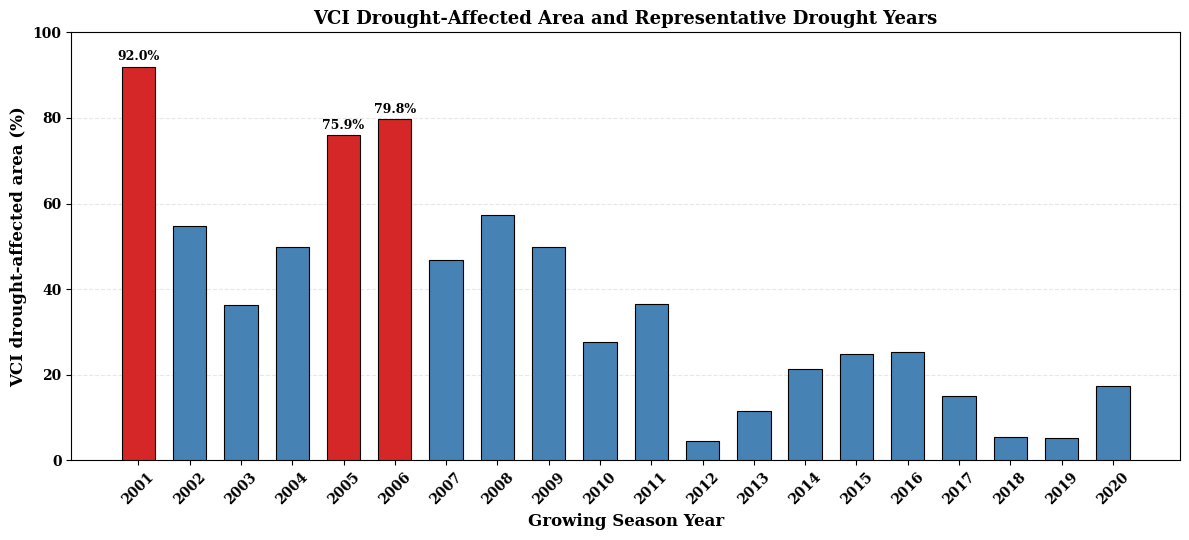

In [5]:
import numpy as np
import matplotlib.pyplot as plt

years = np.arange(2001, 2021)
area = [91.95, 54.76, 36.39, 49.82, 75.93, 79.75, 46.80, 57.26, 49.85, 27.76,
        36.61, 4.63, 11.58, 21.41, 24.89, 25.23, 15.10, 5.39, 5.23, 17.43]
target = [2001, 2005, 2006]

plt.rcParams.update({'font.family': 'serif', 'font.weight': 'bold'})
fig, ax = plt.subplots(figsize=(12, 5.5))
colors = ['#d62728' if y in target else '#4682b4' for y in years]
ax.bar(years, area, color=colors, edgecolor='black', linewidth=0.8, width=0.65, zorder=3)
for y, a in zip(years, area):
    if y in target:
        ax.text(y, a + 1.5, f'{a:.1f}%', ha='center', fontsize=9, fontweight='bold')
ax.set_xticks(years)
ax.tick_params(axis='x', rotation=45)
ax.set_ylim(0, 100)
ax.set_xlabel('Growing Season Year', fontsize=12, fontweight='bold')
ax.set_ylabel('VCI drought-affected area (%)', fontsize=12, fontweight='bold')
ax.set_title('VCI Drought-Affected Area and Representative Drought Years',
             fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.3, linestyle='--', zorder=1)
fig.tight_layout()
fig.savefig('Drought_Area_Selection.png', dpi=400, bbox_inches='tight')
plt.show()

In [16]:
import os
import glob
import re
import warnings
import numpy as np
import pandas as pd
import rasterio

# ---- Paths ------------------------------------------------------------------
BASE_DIR = r"E:\2_Contribution\Final\Preprocess"

INDICES_DIRS = {
    'VCI'   : os.path.join(BASE_DIR, "VCI"),
    'TVDI'  : os.path.join(BASE_DIR, "TVDI", "annaul"),   # yearly GS files
    'SMDI'  : os.path.join(BASE_DIR, "SMDI"),
    'SPEI-3': os.path.join(BASE_DIR, "SPEI_3"),
    'SPEI-6': os.path.join(BASE_DIR, "SPEI_6"),
}

OUT_DIR = os.path.join(BASE_DIR, "3. Trend", "Update result")
os.makedirs(OUT_DIR, exist_ok=True)

GROWING_MONTHS = [4, 5, 6, 7, 8, 9, 10]
TARGET_YEARS = [2001, 2005, 2006]

# ---- VCI drought-area definition (Eq. 4-6) ----------------------------------
VCI_DROUGHT_THR = 40.0      # pixel is drought-affected if VCI < 40 (Kogan, 1995)

# How the VCI value compared with 40 is obtained:
#  'seasonal': per-pixel growing-season MEAN VCI < 40, % of valid pixels
#  'monthly' : % of valid pixels with VCI < 40 for each month, then averaged
#  'pooled'  : % of all valid pixel-months with VCI < 40
#  'auto'    : use whichever of the three best reproduces the published column
AREA_METHOD = 'auto'

# ---- Published Table 4.4 (used only to validate recomputed values) ----------
PUBLISHED = pd.DataFrame({
    'Year': list(range(2001, 2021)),
    'VCI': [16.69, 39.72, 46.81, 40.49, 27.43, 26.34, 42.32, 38.54, 40.62, 47.96,
            43.95, 65.80, 59.16, 51.55, 49.43, 52.11, 52.21, 70.67, 67.65, 58.02],
    'Area': [91.95, 54.76, 36.39, 49.82, 75.93, 79.75, 46.80, 57.26, 49.85, 27.76,
             36.61, 4.63, 11.58, 21.41, 24.89, 25.23, 15.10, 5.39, 5.23, 17.43],
    'SMDI': [-0.83, 0.40, 0.67, -1.01, -0.79, -1.49, -0.06, -0.46, -1.34, -0.37,
             -1.79, 0.60, -0.63, -0.22, -1.42, 0.24, 0.88, 1.97, 1.04, 1.54],
    'SPEI-3': [-0.82, -0.03, 0.60, -1.01, -1.60, -1.03, -0.41, -1.21, -1.34, -0.26,
               -0.99, -0.23, -0.60, -0.19, -1.70, -0.51, -0.43, 0.04, -0.75, -0.57],
    'SPEI-6': [-1.27, 0.39, 0.66, -1.47, -1.83, -1.31, -0.58, -1.53, -1.82, 0.01,
               -1.39, -0.05, -0.90, -0.38, -1.59, -0.59, -0.57, -0.32, -0.95, -1.12],
    'TVDI': [0.624, 0.659, 0.639, 0.697, 0.667, 0.698, 0.683, 0.717, 0.701, 0.657,
             0.713, 0.726, 0.709, 0.649, 0.711, 0.688, 0.681, 0.728, 0.705, 0.731],
}).set_index('Year')

# -----------------------------------------------------------------------------
# 1. Helpers
# -----------------------------------------------------------------------------
def list_files_by_year(input_dir):
    """For monthly indices (VCI, SMDI, SPEI)."""
    by_year = {}
    for fp in glob.glob(os.path.join(input_dir, "*.tif")):
        m = re.search(r"(\d{4})[_-]?(\d{2})\.tif", os.path.basename(fp))
        if m:
            yr, mo = int(m.group(1)), int(m.group(2))
            if mo in GROWING_MONTHS:
                by_year.setdefault(yr, []).append((mo, fp))
    return {y: sorted(v) for y, v in by_year.items()}


def list_tvdi_yearly(input_dir):
    """For yearly TVDI_Ningxia_GS_YYYY.tif files."""
    by_year = {}
    for fp in glob.glob(os.path.join(input_dir, "TVDI_Ningxia_GS_*.tif")):
        m = re.search(r"TVDI_Ningxia_GS_(\d{4})\.tif", os.path.basename(fp))
        if m:
            yr = int(m.group(1))
            by_year[yr] = fp
    return by_year


def read_raster(fp, is_tvdi=False):
    with rasterio.open(fp) as src:
        arr = src.read(1).astype(np.float32)
        if src.nodata is not None:
            arr[arr == src.nodata] = np.nan
        else:
            arr[arr <= -9999] = np.nan
        if is_tvdi:
            # TVDI already 0–1; mask any invalid values
            arr[(arr < 0) | (arr > 1)] = np.nan
    return arr


def nanmean_quiet(a, axis=None):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        return np.nanmean(a, axis=axis)


def drought_area(stack, thr, method):
    """Percent of valid pixels with VCI < thr. stack = (months, H, W)."""
    if method == 'seasonal':
        pix = nanmean_quiet(stack, axis=0)
        valid = np.isfinite(pix)
        return 100.0 * np.sum(pix[valid] < thr) / valid.sum()
    if method == 'monthly':
        pct = []
        for a in stack:
            valid = np.isfinite(a)
            pct.append(100.0 * np.sum(a[valid] < thr) / valid.sum())
        return float(np.mean(pct))
    if method == 'pooled':
        valid = np.isfinite(stack)
        return 100.0 * np.sum(stack[valid] < thr) / valid.sum()
    raise ValueError("method must be 'seasonal', 'monthly' or 'pooled'")


# -----------------------------------------------------------------------------
# 2. Growing-season means of the five indices
# -----------------------------------------------------------------------------
means = {}
vci_stacks = {}

for name, d in INDICES_DIRS.items():
    print(f"Processing {name} ...")

    if name == 'TVDI':
        # ---------- Yearly TVDI ----------
        files = list_tvdi_yearly(d)
        if not files:
            raise FileNotFoundError(f"No TVDI_Ningxia_GS_*.tif files found in {d}")

        means[name] = {}
        for yr, fp in sorted(files.items()):
            arr = read_raster(fp, is_tvdi=True)
            means[name][yr] = float(nanmean_quiet(arr))

    else:
        # ---------- Monthly indices ----------
        files = list_files_by_year(d)
        if not files:
            raise FileNotFoundError(f"No valid .tif files for {name} in {d}")

        means[name] = {}
        for yr, items in sorted(files.items()):
            if len(items) != len(GROWING_MONTHS):
                print(f"  WARNING [{name}] {yr}: {len(items)} files, "
                      f"expected {len(GROWING_MONTHS)}")
            arrays = [read_raster(fp) for _, fp in items]
            means[name][yr] = float(np.mean([nanmean_quiet(a) for a in arrays]))

            if name == 'VCI':
                if len({a.shape for a in arrays}) != 1:
                    raise ValueError(f"VCI rasters in {yr} differ in shape")
                vci_stacks[yr] = np.stack(arrays)

years = sorted(set.intersection(*[set(v) for v in means.values()]))

# -----------------------------------------------------------------------------
# 3. Which area method reproduces the published column (VCI < 40)?
# -----------------------------------------------------------------------------
pub_area = PUBLISHED['Area']
common = [y for y in years if y in pub_area.index]

method_mad = {}
print(f"\nDrought-area check at VCI < {VCI_DROUGHT_THR:g} "
      "(mean absolute difference vs published, % points)")
for method in ['seasonal', 'monthly', 'pooled']:
    calc = pd.Series({y: drought_area(vci_stacks[y], VCI_DROUGHT_THR, method)
                      for y in years})
    method_mad[method] = float(np.mean(np.abs(calc[common] - pub_area[common])))
    print(f"  {method:9s}: MAD = {method_mad[method]:.3f}")

best = min(method_mad, key=method_mad.get)
if AREA_METHOD == 'auto':
    AREA_METHOD = best
    print(f"-> 'auto' selected: {AREA_METHOD}")
    if method_mad[best] > 0.5:
        print("   WARNING: even the best method differs from your published "
              "area column by > 0.5 points. Check your original area script "
              "(different mask, valid-pixel definition, or VCI input).")

print(f"Area method used: {AREA_METHOD}\n")
area = {y: drought_area(vci_stacks[y], VCI_DROUGHT_THR, AREA_METHOD) for y in years}

# -----------------------------------------------------------------------------
# 4. Build Table 4.4
# -----------------------------------------------------------------------------
table = pd.DataFrame({
    'Year': years,
    'Mean VCI': [means['VCI'][y] for y in years],
    'VCI Drought Area (%)': [area[y] for y in years],
    'Mean SMDI': [means['SMDI'][y] for y in years],
    'Mean SPEI-3': [means['SPEI-3'][y] for y in years],
    'Mean SPEI-6': [means['SPEI-6'][y] for y in years],
    'Mean TVDI': [means['TVDI'][y] for y in years],
}).set_index('Year')

fmt = table.copy()
for c in fmt.columns:
    fmt[c] = fmt[c].round(3 if c == 'Mean TVDI' else 2)

print("=" * 80)
print(f"Table 4.4 (VCI < {VCI_DROUGHT_THR:g}; area method = {AREA_METHOD})")
print("=" * 80)
print(fmt.to_string())

top = fmt['VCI Drought Area (%)'].sort_values(ascending=False)
print("\nTop 5 years by drought area:", top.head(5).to_dict())
print("Lowest 5 years by mean VCI :", fmt['Mean VCI'].nsmallest(5).to_dict())
print(f"Gap between 3rd and 4th largest area: {top.iloc[2] - top.iloc[3]:.2f} "
      "percentage points")
print("Three largest-area years:", sorted(int(y) for y in top.index[:3]))

# Sensitivity of the ranking to the VCI threshold
print("\nThree largest-area years for other VCI thresholds "
      f"(method = {AREA_METHOD}):")
for thr in [30, 35, 40, 45, 50]:
    a = pd.Series({y: drought_area(vci_stacks[y], thr, AREA_METHOD) for y in years})
    print(f"  VCI < {thr}: {sorted(int(y) for y in a.nlargest(3).index)}")

# -----------------------------------------------------------------------------
# 5. Validate against the published Table 4.4
# -----------------------------------------------------------------------------
col_map = {'Mean VCI': 'VCI', 'VCI Drought Area (%)': 'Area', 'Mean SMDI': 'SMDI',
           'Mean SPEI-3': 'SPEI-3', 'Mean SPEI-6': 'SPEI-6', 'Mean TVDI': 'TVDI'}
tol = {'Mean VCI': 0.05, 'VCI Drought Area (%)': 0.5, 'Mean SMDI': 0.02,
       'Mean SPEI-3': 0.02, 'Mean SPEI-6': 0.02, 'Mean TVDI': 0.002}

print("\n" + "=" * 80)
print("Comparison with published Table 4.4 (recomputed - published)")
print("=" * 80)
issues = 0
for col, pcol in col_map.items():
    diff = table.loc[common, col] - PUBLISHED.loc[common, pcol]
    bad = diff[diff.abs() > tol[col]]
    print(f"{col:24s}: max |diff| = {diff.abs().max():.3f} -> "
          f"{'OK' if bad.empty else str(len(bad)) + ' year(s) differ'}")
    for y, v in bad.items():
        issues += 1
        print(f"      {y}: recomputed {table.loc[y, col]:.3f} vs published "
              f"{PUBLISHED.loc[y, pcol]:.3f} (diff {v:+.3f})")

print("\nAll columns match." if issues == 0 else
      f"\n{issues} mismatch(es) found - resolve before submission.")

# -----------------------------------------------------------------------------
# 6. Save
# -----------------------------------------------------------------------------
csv_path = os.path.join(OUT_DIR, "Table_4_4_recomputed.csv")
fmt.to_csv(csv_path)
print(f"\nCSV saved: {csv_path}")

xlsx_path = os.path.join(OUT_DIR, "Table_4_4_recomputed.xlsx")
try:
    from openpyxl.styles import Font, PatternFill, Alignment
    with pd.ExcelWriter(xlsx_path, engine='openpyxl') as writer:
        fmt.to_excel(writer, sheet_name='Table 4.4')
        ws = writer.sheets['Table 4.4']
        for cell in ws[1]:
            cell.font = Font(bold=True)
            cell.alignment = Alignment(horizontal='center', wrap_text=True)
        for r in range(2, ws.max_row + 1):
            if ws.cell(r, 1).value in TARGET_YEARS:
                for c in range(1, ws.max_column + 1):
                    ws.cell(r, c).font = Font(bold=True)
                    ws.cell(r, c).fill = PatternFill('solid', fgColor='F8D7DA')
        for col in ws.columns:
            ws.column_dimensions[col[0].column_letter].width = 16
    print(f"Excel saved: {xlsx_path} (target years highlighted)")
except ImportError:
    print("openpyxl not installed - Excel skipped (pip install openpyxl).")

Processing VCI ...
Processing TVDI ...
Processing SMDI ...
Processing SPEI-3 ...
Processing SPEI-6 ...

Drought-area check at VCI < 40 (mean absolute difference vs published, % points)
  seasonal : MAD = 0.002
  monthly  : MAD = 6.883
  pooled   : MAD = 6.883
-> 'auto' selected: seasonal
Area method used: seasonal

Table 4.4 (VCI < 40; area method = seasonal)
      Mean VCI  VCI Drought Area (%)  Mean SMDI  Mean SPEI-3  Mean SPEI-6  Mean TVDI
Year                                                                                
2001     16.69                 91.95      -0.83        -0.82        -1.27      0.521
2002     39.72                 54.76       0.46        -0.03         0.39      0.551
2003     46.81                 36.39       0.67         0.60         0.66      0.544
2004     40.49                 49.82      -1.01        -1.02        -1.48      0.591
2005     27.43                 75.93      -0.79        -1.60        -1.83      0.597
2006     26.34                 79.75      -

In [19]:
import glob
import re
import numpy as np
import rasterio
from scipy.stats import spearmanr

folder = r"E:\2_Contribution\Final\Preprocess\TVDI\annual"  # Double-check spelling here!

# Find all matching files
file_paths = sorted(glob.glob(folder + r"\*.tif"))

# Check if files were actually found
if not file_paths:
    print(f"Error: No .tif files found in: {folder}")
    print("Please check if the folder path, spelling, or file extension is correct.")
else:
    rows = []
    for fp in file_paths:
        # Extract 4-digit year from filename
        match = re.search(r"(\d{4})", fp.split("\\")[-1])
        if match:
            yr = int(match.group(1))
            with rasterio.open(fp) as s:
                a = s.read(1).astype(float)
                if s.nodata is not None: 
                    a[a == s.nodata] = np.nan
            rows.append((yr, np.isfinite(a).sum(), np.nanmean(a)))
        else:
            print(f"Warning: Could not extract a 4-digit year from filename: {fp}")

    if rows:
        rows = np.array(rows)
        print("Data array shape:", rows.shape)
        print(rows)
        print("valid pixels vs year :", spearmanr(rows[:, 0], rows[:, 1]))
        print("valid pixels vs TVDI :", spearmanr(rows[:, 1], rows[:, 2]))
    else:
        print("Error: Files were found, but no years could be extracted from their filenames.")

Error: No .tif files found in: E:\2_Contribution\Final\Preprocess\TVDI\annual
Please check if the folder path, spelling, or file extension is correct.


In [22]:
import pandas as pd, numpy as np
from scipy.stats import spearmanr, theilslopes

t = pd.read_csv(r"E:\2_Contribution\Final\Preprocess\3. Trend\Update result\Table_4_4_recomputed.csv", index_col=0)
for c in ['Mean SMDI','Mean SPEI-3','Mean SPEI-6','Mean TVDI']:
    rho, p = spearmanr(t['Mean VCI'], t[c]); print(f"VCI vs {c}: rho={rho:.2f}, p={p:.3f}")

yrs = t.index.values; v = t['Mean VCI'].values
keep = ~np.isin(yrs, [2001, 2005, 2006])
slope, icpt, *_ = theilslopes(v[keep], yrs[keep])          # trend fitted WITHOUT target years
res = v - (icpt + slope * yrs); z = res / res[keep].std()
print("Slope excl. target years:", round(slope, 2))
print("Residual z, lowest five:", pd.Series(z, index=yrs).nsmallest(5).round(2).to_dict())

VCI vs Mean SMDI: rho=0.69, p=0.001
VCI vs Mean SPEI-3: rho=0.47, p=0.037
VCI vs Mean SPEI-6: rho=0.43, p=0.057
VCI vs Mean TVDI: rho=0.54, p=0.013
Slope excl. target years: 1.31
Residual z, lowest five: {2001: -2.77, 2006: -2.3, 2005: -1.94, 2008: -0.85, 2009: -0.74}


Extracting regional means for: VCI...
Extracting regional means for: TVDI...
Extracting regional means for: SMDI...
Extracting regional means for: SPEI-3...
Extracting regional means for: SPEI-6...


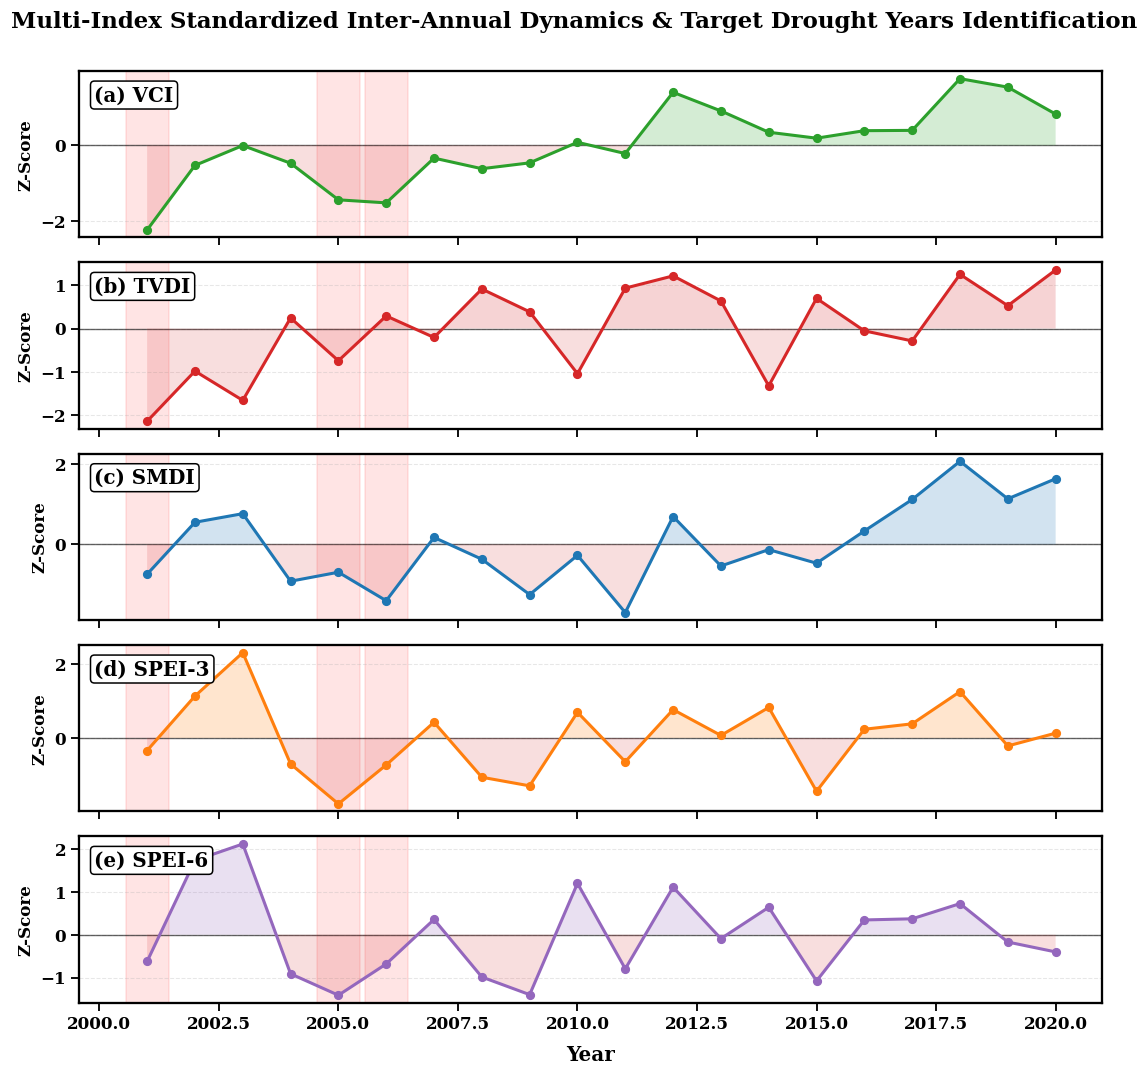


Stacked professional journal-grade figure saved to: E:\2_Contribution\Final\Preprocess\3. Trend\Ningxia_Stacked_Ribbon_Journal_Grade.png


In [26]:
import os
import glob
import re
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# ---- Paths Configuration ----------------------------------------------------
BASE_DIR = r"E:\2_Contribution\Final\Preprocess"
INDICES_DIRS = {
    'VCI'   : os.path.join(BASE_DIR, "VCI"),
    'TVDI'  : os.path.join(BASE_DIR, "TVDI"),
    'SMDI'  : os.path.join(BASE_DIR, "SMDI"),
    'SPEI-3': os.path.join(BASE_DIR, "SPEI_3"),
    'SPEI-6': os.path.join(BASE_DIR, "SPEI_6")
}
FIG_DIR = os.path.join(BASE_DIR, "3. Trend")
os.makedirs(FIG_DIR, exist_ok=True)

GROWING_MONTHS = [4, 5, 6, 7, 8, 9, 10]
DROUGHT_YEARS = [2001, 2005, 2006]  # Target drought years to highlight

# ---- Publication Style Configuration ----------------------------------------
plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor'   : 'white',
    'axes.facecolor'     : 'white',
    'savefig.facecolor'  : 'white',
    'axes.edgecolor'     : 'black',
    'axes.linewidth'     : 1.5,
    'axes.labelcolor'    : 'black',
    'text.color'         : 'black',
    'axes.titlecolor'    : 'black',
    'xtick.color'        : 'black',
    'ytick.color'        : 'black',
    'figure.dpi'         : 110,
    'savefig.dpi'        : 400,
    'font.family'        : 'serif',
    'font.weight'        : 'bold',
    'axes.labelweight'   : 'bold',
    'axes.titleweight'   : 'bold',
})

raw_timeseries = {}

# -----------------------------------------------------------------------------
# 1. Extract Annual Regional Means from Rasters
# -----------------------------------------------------------------------------
for name, input_dir in INDICES_DIRS.items():
    print(f"Extracting regional means for: {name}...")
    search_pattern = os.path.join(input_dir, "*.tif")
    file_paths = glob.glob(search_pattern)
    
    if not file_paths:
        continue

    yearly_data_dict = {}
    for fp in file_paths:
        filename = os.path.basename(fp)
        match = re.search(r"(\d{4})[_-]?(\d{2})\.tif", filename)
        if match:
            year, month = int(match.group(1)), int(match.group(2))
            if month in GROWING_MONTHS:
                if year not in yearly_data_dict:
                    yearly_data_dict[year] = []
                yearly_data_dict[year].append(fp)

    years_sorted = sorted(yearly_data_dict.keys())
    annual_means = []

    for yr in years_sorted:
        monthly_stack = []
        for fp in yearly_data_dict[yr]:
            with rasterio.open(fp) as src:
                arr = src.read(1).astype(np.float32)
                nodata = src.nodata
                if nodata is not None:
                    arr[arr == nodata] = np.nan
                else:
                    arr[arr <= -9999] = np.nan
                monthly_stack.append(np.nanmean(arr))
        annual_means.append(np.nanmean(monthly_stack))

    if years_sorted:
        raw_timeseries[name] = {
            'years': np.array(years_sorted),
            'means': np.array(annual_means)
        }

# Find common years across all indices
common_years = None
for name, data in raw_timeseries.items():
    if common_years is None:
        common_years = set(data['years'])
    else:
        common_years = common_years.intersection(set(data['years']))
common_years = sorted(list(common_years))
years_arr = np.array(common_years)

# -----------------------------------------------------------------------------
# 2. Plotting Stacked Journal-Grade Multi-Panel Ribbon Chart
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(5, 1, figsize=(12, 11), sharex=True, facecolor='white')

index_keys = ['VCI', 'TVDI', 'SMDI', 'SPEI-3', 'SPEI-6']
colors = {
    'VCI'   : '#2ca02c',  # Green
    'TVDI'  : '#d62728',  # Red
    'SMDI'  : '#1f77b4',  # Blue
    'SPEI-3': '#ff7f0e',  # Orange
    'SPEI-6': '#9467bd'   # Purple
}

for idx, key in enumerate(index_keys):
    ax = axes[idx]
    if key not in raw_timeseries:
        continue
        
    data = raw_timeseries[key]
    mask = np.isin(data['years'], years_arr)
    vals = data['means'][mask]
    
    # Standardize values for clean comparable anomalies (Z-score)
    z_vals = (vals - np.nanmean(vals)) / np.nanstd(vals)
    
    # Highlight drought years using background vertical spans across each panel
    for dy in DROUGHT_YEARS:
        if dy in years_arr:
            ax.axvspan(dy - 0.45, dy + 0.45, color='#ff4d4d', alpha=0.15, zorder=1)

    # Plot zero baseline
    ax.axhline(0, color='black', linestyle='-', linewidth=0.9, alpha=0.6, zorder=2)
    
    # Plot main trend line with markers
    color = colors.get(key, '#333333')
    ax.plot(years_arr, z_vals, color=color, linewidth=2, marker='o', markersize=5, zorder=3)
    
    # Fill positive and negative anomaly regions dynamically
    ax.fill_between(years_arr, 0, z_vals, where=(z_vals >= 0), facecolor=color, alpha=0.2, interpolate=True, zorder=2)
    ax.fill_between(years_arr, 0, z_vals, where=(z_vals < 0), facecolor='#d62728', alpha=0.15, interpolate=True, zorder=2)
    
    # Panel Label inside top-left or title slot
    ax.text(0.015, 0.82, f'({chr(97+idx)}) {key}', transform=ax.transAxes, 
            fontsize=13, fontweight='bold', bbox=dict(facecolor='white', edgecolor='black', boxstyle='round,pad=0.2', linewidth=1))

    ax.tick_params(axis='both', labelsize=11, width=1.2, length=5)
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')
        
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7, zorder=1)
    ax.set_ylabel('Z-Score', fontsize=11, fontweight='bold')

# Set X-axis label only on the bottom plot
axes[-1].set_xlabel('Year', fontsize=13, fontweight='bold', labelpad=8)

# Add a clean overarching title or layout spacing
plt.suptitle('Multi-Index Standardized Inter-Annual Dynamics & Target Drought Years Identification', fontsize=15, fontweight='bold', y=0.93)
plt.subplots_adjust(hspace=0.15)

out_fig = os.path.join(FIG_DIR, 'Ningxia_Stacked_Ribbon_Journal_Grade.png')
plt.savefig(out_fig, bbox_inches='tight', dpi=300, facecolor='white')
plt.show()

print("\n" + "="*70)
print(f"Stacked professional journal-grade figure saved to: {out_fig}")
print("="*70)

Extracting regional means for: VCI...
Extracting regional means for: TVDI...
Extracting regional means for: SMDI...
Extracting regional means for: SPEI-3...
Extracting regional means for: SPEI-6...

Common years: 2001-2020 (n = 20)


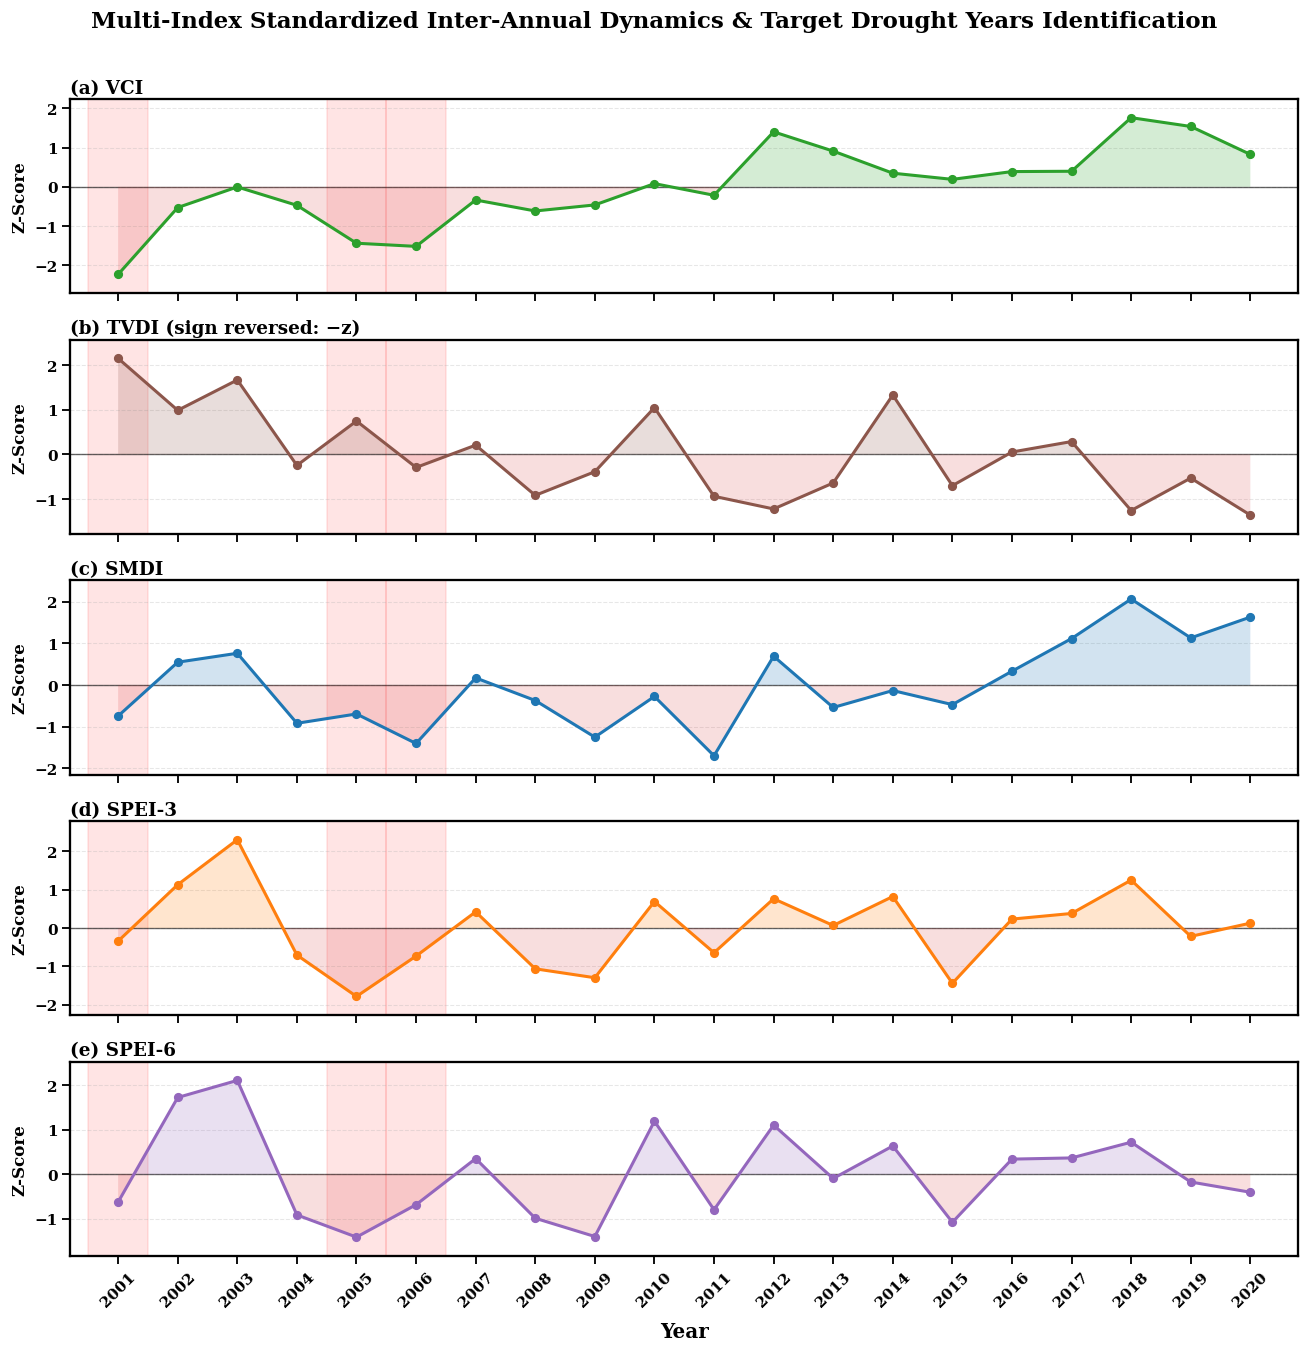


Figure A1 saved to: E:\2_Contribution\Final\Preprocess\3. Trend\Ningxia_Ribbon_Journal_Grade.png


In [2]:
import os
import glob
import re
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# ---- Paths Configuration ----------------------------------------------------
BASE_DIR = r"E:\2_Contribution\Final\Preprocess"
INDICES_DIRS = {
    'VCI'   : os.path.join(BASE_DIR, "VCI"),
    'TVDI'  : os.path.join(BASE_DIR, "TVDI"),
    'SMDI'  : os.path.join(BASE_DIR, "SMDI"),
    'SPEI-3': os.path.join(BASE_DIR, "SPEI_3"),
    'SPEI-6': os.path.join(BASE_DIR, "SPEI_6"),
}
FIG_DIR = os.path.join(BASE_DIR, "3. Trend")
os.makedirs(FIG_DIR, exist_ok=True)

GROWING_MONTHS = [4, 5, 6, 7, 8, 9, 10]
DROUGHT_YEARS = [2001, 2005, 2006]      # Years to highlight (target drought years)

INDEX_KEYS = ['VCI', 'TVDI', 'SMDI', 'SPEI-3', 'SPEI-6']

# Sign applied to each z-score so that NEGATIVE ALWAYS MEANS DRIER.
# VCI, SMDI, SPEI: low = dry (+1).  TVDI: high = dry, so it is reversed (-1).
DRY_SIGN = {'VCI': +1, 'TVDI': -1, 'SMDI': +1, 'SPEI-3': +1, 'SPEI-6': +1}

PANEL_NAMES = {
    'VCI': 'VCI',
    'TVDI': 'TVDI (sign reversed: \u2212z)',
    'SMDI': 'SMDI',
    'SPEI-3': 'SPEI-3',
    'SPEI-6': 'SPEI-6',
}
COLORS = {
    'VCI': '#2ca02c', 'TVDI': '#8c564b', 'SMDI': '#1f77b4',
    'SPEI-3': '#ff7f0e', 'SPEI-6': '#9467bd',
}

# ---- Publication Style ------------------------------------------------------
plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'axes.edgecolor': 'black',
    'axes.linewidth': 1.5, 'axes.labelcolor': 'black', 'text.color': 'black',
    'xtick.color': 'black', 'ytick.color': 'black',
    'figure.dpi': 110, 'savefig.dpi': 400,
    'font.family': 'serif', 'font.weight': 'bold',
    'axes.labelweight': 'bold', 'axes.titleweight': 'bold',
})


# -----------------------------------------------------------------------------
# 1. Extract growing-season regional means from rasters
# -----------------------------------------------------------------------------
def annual_regional_means(input_dir, name):
    """Mean over growing-season months (equal weight per month) of the
    spatial mean of each monthly raster. Returns (years, means)."""
    by_year = {}
    for fp in glob.glob(os.path.join(input_dir, "*.tif")):
        m = re.search(r"(\d{4})[_-]?(\d{2})\.tif", os.path.basename(fp))
        if m:
            yr, mo = int(m.group(1)), int(m.group(2))
            if mo in GROWING_MONTHS:
                by_year.setdefault(yr, []).append(fp)

    years, means = [], []
    for yr in sorted(by_year):
        if len(by_year[yr]) != len(GROWING_MONTHS):
            print(f"  WARNING [{name}] {yr}: {len(by_year[yr])} files found, "
                  f"expected {len(GROWING_MONTHS)}")
        monthly = []
        for fp in by_year[yr]:
            with rasterio.open(fp) as src:
                arr = src.read(1).astype(np.float32)
                if src.nodata is not None:
                    arr[arr == src.nodata] = np.nan
                else:
                    arr[arr <= -9999] = np.nan
                monthly.append(np.nanmean(arr))
        years.append(yr)
        means.append(np.nanmean(monthly))
    return np.array(years), np.array(means)


raw_timeseries = {}
for name, d in INDICES_DIRS.items():
    print(f"Extracting regional means for: {name}...")
    yrs, mns = annual_regional_means(d, name)
    if len(yrs) == 0:
        raise FileNotFoundError(f"No valid .tif files found for {name} in {d}")
    raw_timeseries[name] = {'years': yrs, 'means': mns}

# Common years across all indices
common = set.intersection(*[set(v['years']) for v in raw_timeseries.values()])
years_arr = np.array(sorted(common))
print(f"\nCommon years: {years_arr[0]}-{years_arr[-1]} (n = {len(years_arr)})")


def zscore(x):
    return (x - np.nanmean(x)) / np.nanstd(x)   # population SD (ddof = 0)


z_orig, z_dry = {}, {}
for key in INDEX_KEYS:
    d = raw_timeseries[key]
    vals = d['means'][np.isin(d['years'], years_arr)]
    z_orig[key] = zscore(vals)                   # original orientation
    z_dry[key] = DRY_SIGN[key] * z_orig[key]     # negative = drier for ALL indices

# -----------------------------------------------------------------------------
# 2. Multi-panel figure (negative = drier in every panel)
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(5, 1, figsize=(12, 12.5), sharex=True)

for i, key in enumerate(INDEX_KEYS):
    ax = axes[i]
    z = z_dry[key]
    color = COLORS[key]

    for dy in DROUGHT_YEARS:
        if dy in years_arr:
            ax.axvspan(dy - 0.5, dy + 0.5, color='#ff4d4d', alpha=0.15, zorder=1)

    ax.axhline(0, color='black', linewidth=0.9, alpha=0.6, zorder=2)
    ax.plot(years_arr, z, color=color, linewidth=2, marker='o',
            markersize=5, zorder=3)
    ax.fill_between(years_arr, 0, z, where=(z >= 0), facecolor=color,
                    alpha=0.2, interpolate=True, zorder=2)
    ax.fill_between(years_arr, 0, z, where=(z < 0), facecolor='#d62728',
                    alpha=0.15, interpolate=True, zorder=2)

    # Panel label above the axes (never overlaps the data)
    ax.set_title(f'({chr(97 + i)}) {PANEL_NAMES[key]}', loc='left',
                 fontsize=12, fontweight='bold', pad=4)

    pad = 0.12 * (np.nanmax(z) - np.nanmin(z))
    ax.set_ylim(np.nanmin(z) - pad, np.nanmax(z) + pad)
    ax.set_ylabel('Z-Score', fontsize=11, fontweight='bold')
    ax.tick_params(axis='both', labelsize=10, width=1.2, length=5)
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7, zorder=1)

# Integer year ticks (every year) and tidy x-limits
axes[-1].set_xticks(years_arr)
axes[-1].set_xlim(years_arr[0] - 0.8, years_arr[-1] + 0.8)
axes[-1].tick_params(axis='x', labelsize=10, rotation=45)
axes[-1].set_xlabel('Year', fontsize=13, fontweight='bold', labelpad=8)

fig.suptitle('Multi-Index Standardized Inter-Annual Dynamics '
             '& Target Drought Years Identification',
             fontsize=15, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.97], h_pad=1.2)

out_fig = os.path.join(FIG_DIR, 'Ningxia_Ribbon_Journal_Grade.png')
fig.savefig(out_fig, bbox_inches='tight', dpi=300, facecolor='white')
plt.show()
print(f"\nFigure A1 saved to: {out_fig}")

Extracting regional means for: VCI...
  → VCI: 2001–2020  (n=20)
Extracting regional means for: TVDI...
  → TVDI: 2001–2020  (n=20)
Extracting regional means for: SMDI...
  → SMDI: 2001–2020  (n=20)
Extracting regional means for: SPEI-3...
  → SPEI-3: 2001–2020  (n=20)
Extracting regional means for: SPEI-6...
  → SPEI-6: 2001–2020  (n=20)

Common years: 2001-2020 (n = 20)


OSError: [Errno 22] Invalid argument: 'E:\\2_Contribution\\Final\\Preprocess\\3. Trend\\Ningxia_Ribbon_Journal_Grade.png'

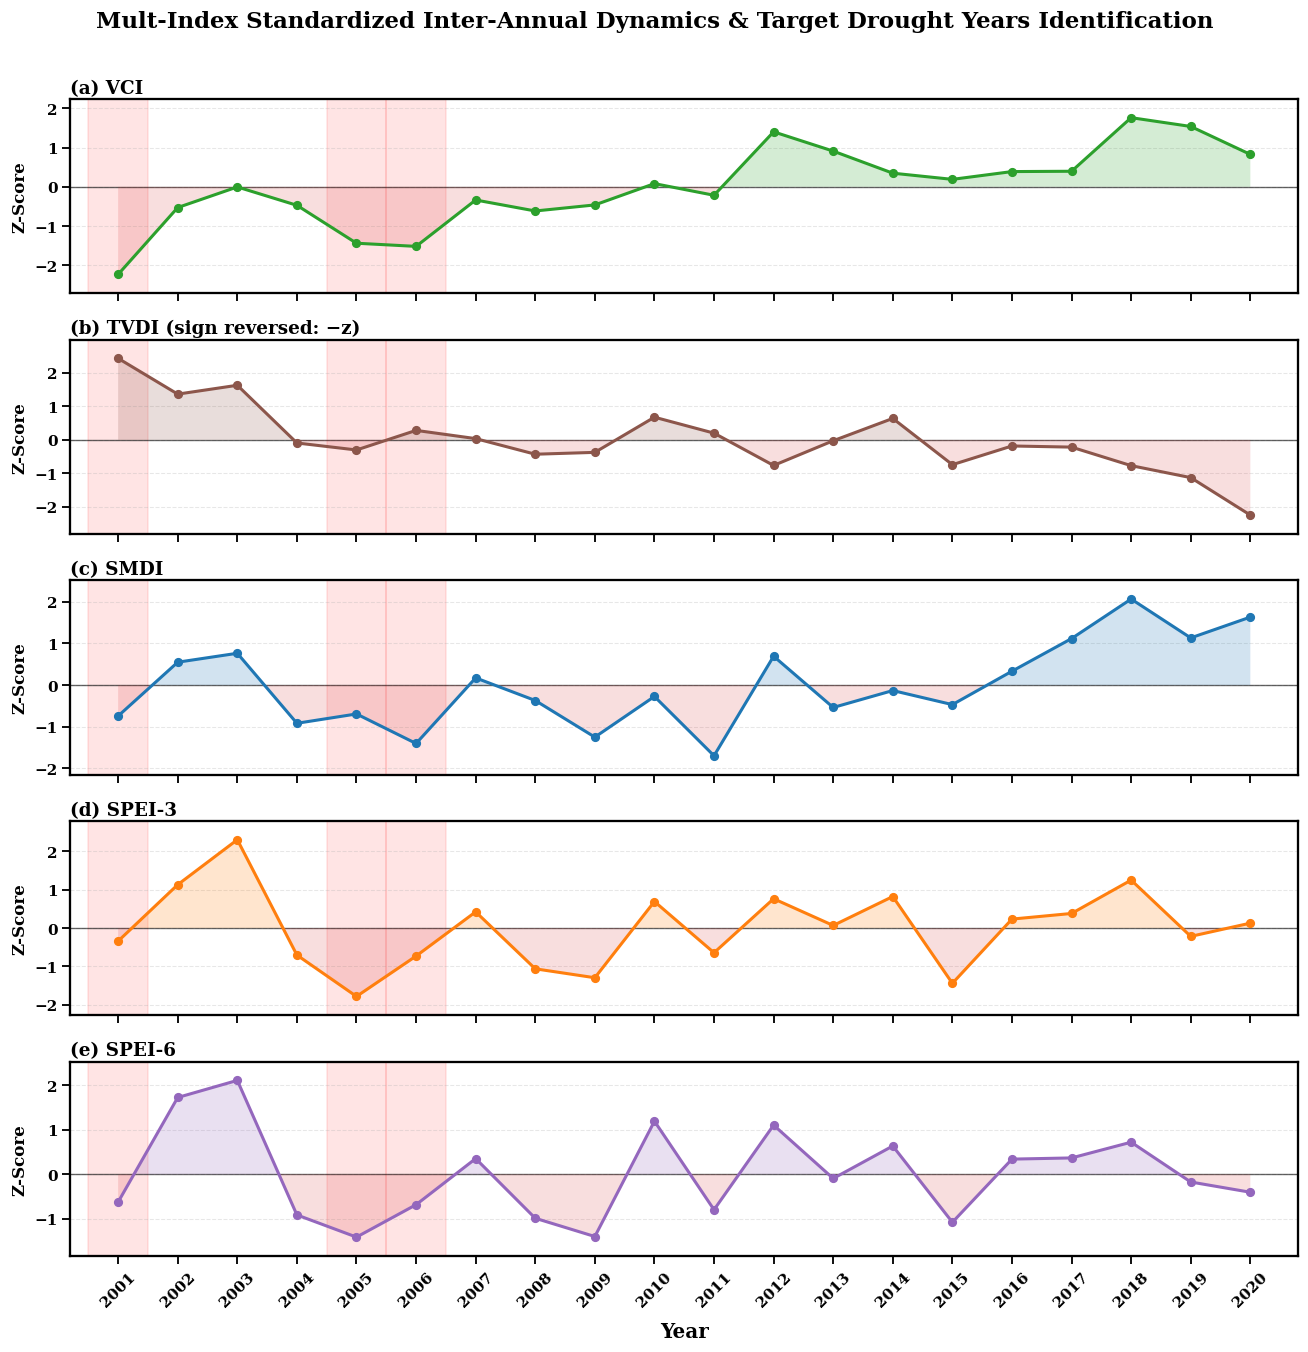

In [11]:
import os
import glob
import re
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# ---- Paths Configuration ----------------------------------------------------
BASE_DIR = r"E:\2_Contribution\Final\Preprocess"

INDICES_DIRS = {
    'VCI'   : os.path.join(BASE_DIR, "VCI"),
    'TVDI'  : os.path.join(BASE_DIR, "TVDI", "annaul"),   # <-- yearly GS files
    'SMDI'  : os.path.join(BASE_DIR, "SMDI"),
    'SPEI-3': os.path.join(BASE_DIR, "SPEI_3"),
    'SPEI-6': os.path.join(BASE_DIR, "SPEI_6"),
}

FIG_DIR = os.path.join(BASE_DIR, "3. Trend")
os.makedirs(FIG_DIR, exist_ok=True)

GROWING_MONTHS = [4, 5, 6, 7, 8, 9, 10]
DROUGHT_YEARS = [2001, 2005, 2006]      # Years to highlight (target drought years)

INDEX_KEYS = ['VCI', 'TVDI', 'SMDI', 'SPEI-3', 'SPEI-6']

# Sign applied to each z-score so that NEGATIVE ALWAYS MEANS DRIER.
# VCI, SMDI, SPEI: low = dry (+1).  TVDI: high = dry, so it is reversed (-1).
DRY_SIGN = {'VCI': +1, 'TVDI': -1, 'SMDI': +1, 'SPEI-3': +1, 'SPEI-6': +1}

PANEL_NAMES = {
    'VCI': 'VCI',
    'TVDI': 'TVDI (sign reversed: \u2212z)',
    'SMDI': 'SMDI',
    'SPEI-3': 'SPEI-3',
    'SPEI-6': 'SPEI-6',
}

COLORS = {
    'VCI': '#2ca02c', 'TVDI': '#8c564b', 'SMDI': '#1f77b4',
    'SPEI-3': '#ff7f0e', 'SPEI-6': '#9467bd',
}

# ---- Publication Style ------------------------------------------------------
plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'axes.edgecolor': 'black',
    'axes.linewidth': 1.5, 'axes.labelcolor': 'black', 'text.color': 'black',
    'xtick.color': 'black', 'ytick.color': 'black',
    'figure.dpi': 110, 'savefig.dpi': 400,
    'font.family': 'serif', 'font.weight': 'bold',
    'axes.labelweight': 'bold', 'axes.titleweight': 'bold',
})

# -----------------------------------------------------------------------------
# 1. Extract regional means
# -----------------------------------------------------------------------------
def annual_regional_means_monthly(input_dir, name):
    """Mean over growing-season months (equal weight per month) of the
    spatial mean of each monthly raster. Returns (years, means)."""
    by_year = {}
    for fp in glob.glob(os.path.join(input_dir, "*.tif")):
        m = re.search(r"(\d{4})[_-]?(\d{2})\.tif", os.path.basename(fp))
        if m:
            yr, mo = int(m.group(1)), int(m.group(2))
            if mo in GROWING_MONTHS:
                by_year.setdefault(yr, []).append(fp)

    years, means = [], []
    for yr in sorted(by_year):
        if len(by_year[yr]) != len(GROWING_MONTHS):
            print(f"  WARNING [{name}] {yr}: {len(by_year[yr])} files found, "
                  f"expected {len(GROWING_MONTHS)}")
        monthly = []
        for fp in by_year[yr]:
            with rasterio.open(fp) as src:
                arr = src.read(1).astype(np.float32)
                if src.nodata is not None:
                    arr[arr == src.nodata] = np.nan
                else:
                    arr[arr <= -9999] = np.nan
                monthly.append(np.nanmean(arr))
        years.append(yr)
        means.append(np.nanmean(monthly))
    return np.array(years), np.array(means)


def annual_regional_means_tvdi(input_dir, name):
    """Load already-aggregated yearly growing-season TVDI rasters
    (TVDI_Ningxia_GS_YYYY.tif). Values are already 0–1.
    Returns (years, means)."""
    years, means = [], []
    pattern = os.path.join(input_dir, "TVDI_Ningxia_GS_*.tif")
    for fp in sorted(glob.glob(pattern)):
        m = re.search(r"TVDI_Ningxia_GS_(\d{4})\.tif", os.path.basename(fp))
        if not m:
            continue
        yr = int(m.group(1))
        with rasterio.open(fp) as src:
            arr = src.read(1).astype(np.float32)
            if src.nodata is not None:
                arr[arr == src.nodata] = np.nan
            else:
                # safety for common nodata values
                arr[(arr <= -9999) | (arr < 0) | (arr > 1)] = np.nan
            means.append(np.nanmean(arr))
            years.append(yr)
    return np.array(years), np.array(means)


raw_timeseries = {}
for name, d in INDICES_DIRS.items():
    print(f"Extracting regional means for: {name}...")
    if name == 'TVDI':
        yrs, mns = annual_regional_means_tvdi(d, name)
    else:
        yrs, mns = annual_regional_means_monthly(d, name)

    if len(yrs) == 0:
        raise FileNotFoundError(f"No valid .tif files found for {name} in {d}")
    raw_timeseries[name] = {'years': yrs, 'means': mns}
    print(f"  → {name}: {yrs[0]}–{yrs[-1]}  (n={len(yrs)})")

# Common years across all indices
common = set.intersection(*[set(v['years']) for v in raw_timeseries.values()])
years_arr = np.array(sorted(common))
print(f"\nCommon years: {years_arr[0]}-{years_arr[-1]} (n = {len(years_arr)})")


def zscore(x):
    return (x - np.nanmean(x)) / np.nanstd(x)   # population SD (ddof = 0)


z_orig, z_dry = {}, {}
for key in INDEX_KEYS:
    d = raw_timeseries[key]
    vals = d['means'][np.isin(d['years'], years_arr)]
    z_orig[key] = zscore(vals)                   # original orientation
    z_dry[key] = DRY_SIGN[key] * z_orig[key]     # negative = drier for ALL indices

# -----------------------------------------------------------------------------
# 2. Multi-panel figure (negative = drier in every panel)
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(5, 1, figsize=(12, 12.5), sharex=True)

for i, key in enumerate(INDEX_KEYS):
    ax = axes[i]
    z = z_dry[key]
    color = COLORS[key]

    for dy in DROUGHT_YEARS:
        if dy in years_arr:
            ax.axvspan(dy - 0.5, dy + 0.5, color='#ff4d4d', alpha=0.15, zorder=1)

    ax.axhline(0, color='black', linewidth=0.9, alpha=0.6, zorder=2)
    ax.plot(years_arr, z, color=color, linewidth=2, marker='o',
            markersize=5, zorder=3)
    ax.fill_between(years_arr, 0, z, where=(z >= 0), facecolor=color,
                    alpha=0.2, interpolate=True, zorder=2)
    ax.fill_between(years_arr, 0, z, where=(z < 0), facecolor='#d62728',
                    alpha=0.15, interpolate=True, zorder=2)

    # Panel label above the axes (never overlaps the data)
    ax.set_title(f'({chr(97 + i)}) {PANEL_NAMES[key]}', loc='left',
                 fontsize=12, fontweight='bold', pad=4)

    pad = 0.12 * (np.nanmax(z) - np.nanmin(z))
    ax.set_ylim(np.nanmin(z) - pad, np.nanmax(z) + pad)
    ax.set_ylabel('Z-Score', fontsize=11, fontweight='bold')
    ax.tick_params(axis='both', labelsize=10, width=1.2, length=5)
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7, zorder=1)

# Integer year ticks (every year) and tidy x-limits
axes[-1].set_xticks(years_arr)
axes[-1].set_xlim(years_arr[0] - 0.8, years_arr[-1] + 0.8)
axes[-1].tick_params(axis='x', labelsize=10, rotation=45)
axes[-1].set_xlabel('Year', fontsize=13, fontweight='bold', labelpad=8)

fig.suptitle('Mult-Index Standardized Inter-Annual Dynamics '
             '& Target Drought Years Identification',
             fontsize=15, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.97], h_pad=1.2)

out_fig = os.path.join(FIG_DIR, 'Ningxia_Ribbon_Journal_Grade.png')
fig.savefig(out_fig, bbox_inches='tight', dpi=300, facecolor='white')
plt.show()
print(f"\nFigure A1 saved to: {out_fig}")

Extracting regional means for: VCI...
  → VCI: 2001–2020  (n=20)
Extracting regional means for: TVDI...
  → TVDI: 2001–2020  (n=20)
Extracting regional means for: SMDI...
  → SMDI: 2001–2020  (n=20)
Extracting regional means for: SPEI-3...
  → SPEI-3: 2001–2020  (n=20)
Extracting regional means for: SPEI-6...
  → SPEI-6: 2001–2020  (n=20)

Common years: 2001-2020 (n = 20)


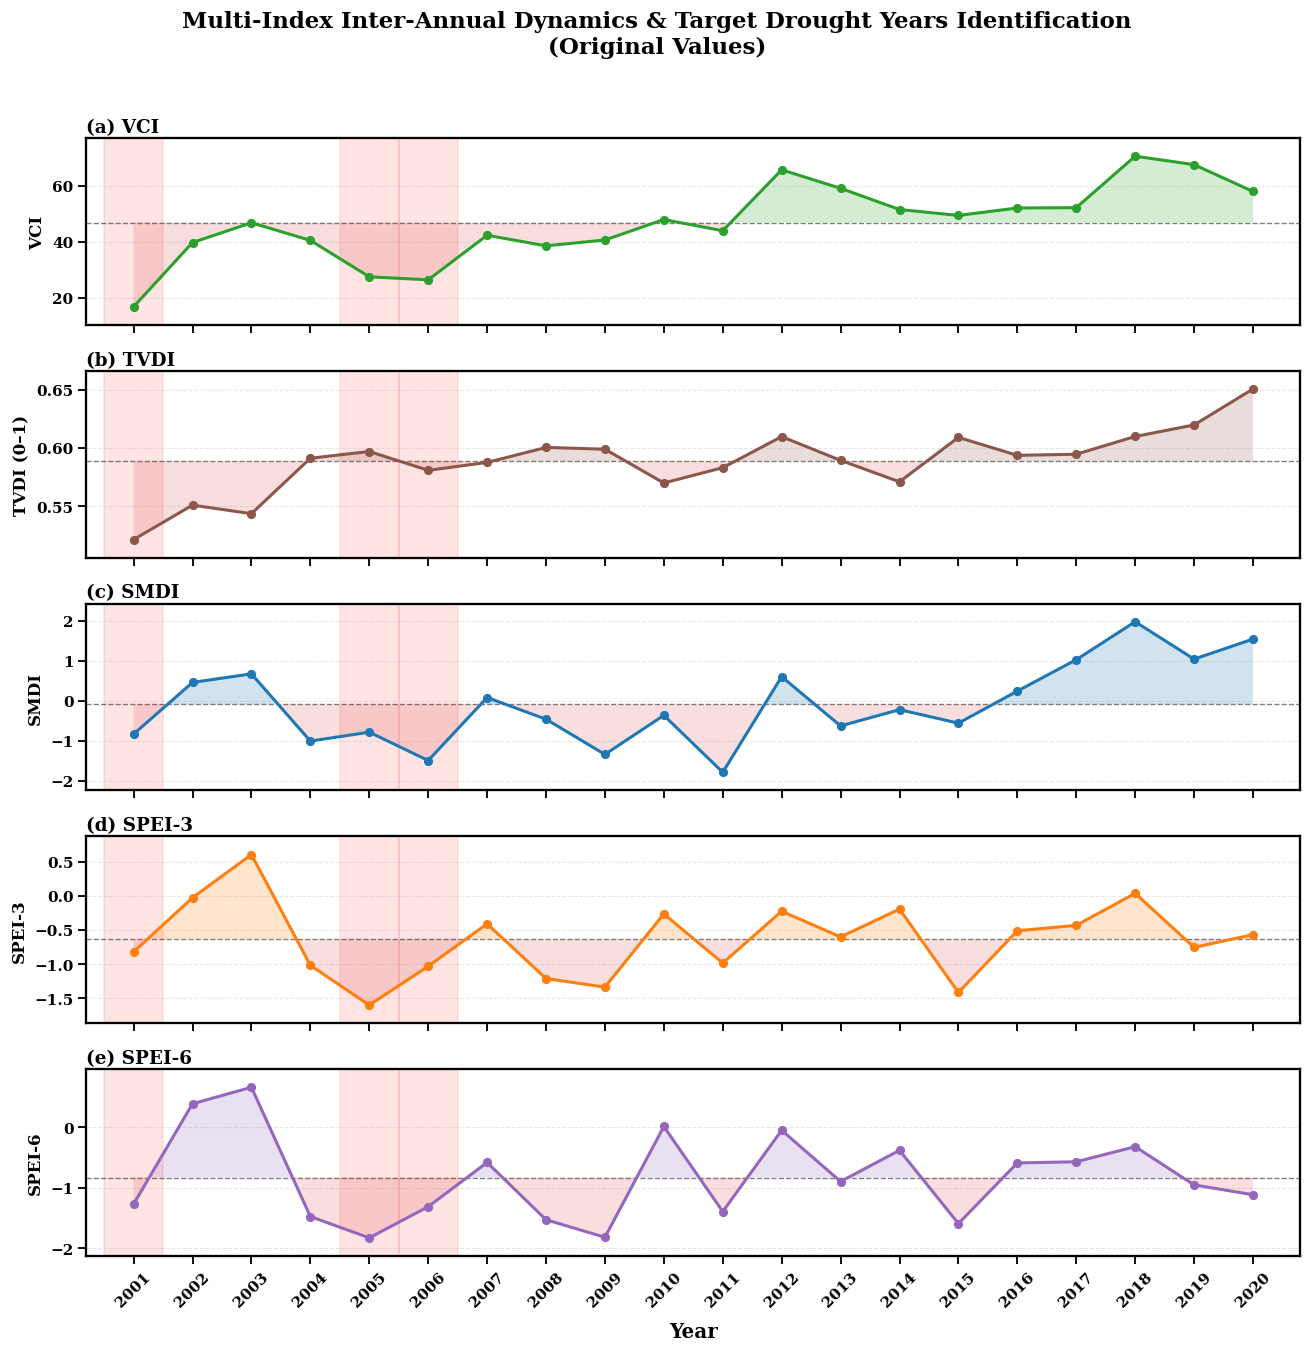


Figure saved to: E:\2_Contribution\Final\Preprocess\3. Trend\Ningxia_Ribbon_Original_Values.png


In [12]:
import os
import glob
import re
import numpy as np
import rasterio
import matplotlib.pyplot as plt

# ---- Paths Configuration ----------------------------------------------------
BASE_DIR = r"E:\2_Contribution\Final\Preprocess"

INDICES_DIRS = {
    'VCI'   : os.path.join(BASE_DIR, "VCI"),
    'TVDI'  : os.path.join(BASE_DIR, "TVDI", "annaul"),   # yearly GS files
    'SMDI'  : os.path.join(BASE_DIR, "SMDI"),
    'SPEI-3': os.path.join(BASE_DIR, "SPEI_3"),
    'SPEI-6': os.path.join(BASE_DIR, "SPEI_6"),
}

FIG_DIR = os.path.join(BASE_DIR, "3. Trend")
os.makedirs(FIG_DIR, exist_ok=True)

GROWING_MONTHS = [4, 5, 6, 7, 8, 9, 10]
DROUGHT_YEARS = [2001, 2005, 2006]

INDEX_KEYS = ['VCI', 'TVDI', 'SMDI', 'SPEI-3', 'SPEI-6']

PANEL_NAMES = {
    'VCI': 'VCI',
    'TVDI': 'TVDI',
    'SMDI': 'SMDI',
    'SPEI-3': 'SPEI-3',
    'SPEI-6': 'SPEI-6',
}

# Y-axis labels in original units
YLABELS = {
    'VCI': 'VCI',
    'TVDI': 'TVDI (0–1)',
    'SMDI': 'SMDI',
    'SPEI-3': 'SPEI-3',
    'SPEI-6': 'SPEI-6',
}

COLORS = {
    'VCI': '#2ca02c', 'TVDI': '#8c564b', 'SMDI': '#1f77b4',
    'SPEI-3': '#ff7f0e', 'SPEI-6': '#9467bd',
}

# ---- Publication Style ------------------------------------------------------
plt.style.use('default')
plt.rcParams.update({
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'axes.edgecolor': 'black',
    'axes.linewidth': 1.5, 'axes.labelcolor': 'black', 'text.color': 'black',
    'xtick.color': 'black', 'ytick.color': 'black',
    'figure.dpi': 110, 'savefig.dpi': 400,
    'font.family': 'serif', 'font.weight': 'bold',
    'axes.labelweight': 'bold', 'axes.titleweight': 'bold',
})

# -----------------------------------------------------------------------------
# 1. Extract regional means
# -----------------------------------------------------------------------------
def annual_regional_means_monthly(input_dir, name):
    by_year = {}
    for fp in glob.glob(os.path.join(input_dir, "*.tif")):
        m = re.search(r"(\d{4})[_-]?(\d{2})\.tif", os.path.basename(fp))
        if m:
            yr, mo = int(m.group(1)), int(m.group(2))
            if mo in GROWING_MONTHS:
                by_year.setdefault(yr, []).append(fp)

    years, means = [], []
    for yr in sorted(by_year):
        if len(by_year[yr]) != len(GROWING_MONTHS):
            print(f"  WARNING [{name}] {yr}: {len(by_year[yr])} files found, "
                  f"expected {len(GROWING_MONTHS)}")
        monthly = []
        for fp in by_year[yr]:
            with rasterio.open(fp) as src:
                arr = src.read(1).astype(np.float32)
                if src.nodata is not None:
                    arr[arr == src.nodata] = np.nan
                else:
                    arr[arr <= -9999] = np.nan
                monthly.append(np.nanmean(arr))
        years.append(yr)
        means.append(np.nanmean(monthly))
    return np.array(years), np.array(means)


def annual_regional_means_tvdi(input_dir, name):
    years, means = [], []
    pattern = os.path.join(input_dir, "TVDI_Ningxia_GS_*.tif")
    for fp in sorted(glob.glob(pattern)):
        m = re.search(r"TVDI_Ningxia_GS_(\d{4})\.tif", os.path.basename(fp))
        if not m:
            continue
        yr = int(m.group(1))
        with rasterio.open(fp) as src:
            arr = src.read(1).astype(np.float32)
            if src.nodata is not None:
                arr[arr == src.nodata] = np.nan
            else:
                arr[(arr <= -9999) | (arr < 0) | (arr > 1)] = np.nan
            means.append(np.nanmean(arr))
            years.append(yr)
    return np.array(years), np.array(means)


raw_timeseries = {}
for name, d in INDICES_DIRS.items():
    print(f"Extracting regional means for: {name}...")
    if name == 'TVDI':
        yrs, mns = annual_regional_means_tvdi(d, name)
    else:
        yrs, mns = annual_regional_means_monthly(d, name)

    if len(yrs) == 0:
        raise FileNotFoundError(f"No valid .tif files found for {name} in {d}")
    raw_timeseries[name] = {'years': yrs, 'means': mns}
    print(f"  → {name}: {yrs[0]}–{yrs[-1]}  (n={len(yrs)})")

# Common years across all indices
common = set.intersection(*[set(v['years']) for v in raw_timeseries.values()])
years_arr = np.array(sorted(common))
print(f"\nCommon years: {years_arr[0]}-{years_arr[-1]} (n = {len(years_arr)})")

# Keep original values (aligned to common years)
values = {}
for key in INDEX_KEYS:
    d = raw_timeseries[key]
    values[key] = d['means'][np.isin(d['years'], years_arr)]

# -----------------------------------------------------------------------------
# 2. Multi-panel figure – original values
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(5, 1, figsize=(12, 12.5), sharex=True)

for i, key in enumerate(INDEX_KEYS):
    ax = axes[i]
    y = values[key]
    color = COLORS[key]

    # Highlight drought years
    for dy in DROUGHT_YEARS:
        if dy in years_arr:
            ax.axvspan(dy - 0.5, dy + 0.5, color='#ff4d4d', alpha=0.15, zorder=1)

    # Optional reference line at long-term mean
    mean_val = np.nanmean(y)
    ax.axhline(mean_val, color='black', linewidth=0.9, alpha=0.5, linestyle='--', zorder=2)

    ax.plot(years_arr, y, color=color, linewidth=2, marker='o', markersize=5, zorder=3)

    # Light fill relative to the mean
    ax.fill_between(years_arr, mean_val, y, where=(y >= mean_val),
                    facecolor=color, alpha=0.2, interpolate=True, zorder=2)
    ax.fill_between(years_arr, mean_val, y, where=(y < mean_val),
                    facecolor='#d62728', alpha=0.15, interpolate=True, zorder=2)

    ax.set_title(f'({chr(97 + i)}) {PANEL_NAMES[key]}', loc='left',
                 fontsize=12, fontweight='bold', pad=4)

    pad = 0.12 * (np.nanmax(y) - np.nanmin(y))
    ax.set_ylim(np.nanmin(y) - pad, np.nanmax(y) + pad)
    ax.set_ylabel(YLABELS[key], fontsize=11, fontweight='bold')
    ax.tick_params(axis='both', labelsize=10, width=1.2, length=5)
    ax.grid(axis='y', alpha=0.3, linestyle='--', linewidth=0.7, zorder=1)

axes[-1].set_xticks(years_arr)
axes[-1].set_xlim(years_arr[0] - 0.8, years_arr[-1] + 0.8)
axes[-1].tick_params(axis='x', labelsize=10, rotation=45)
axes[-1].set_xlabel('Year', fontsize=13, fontweight='bold', labelpad=8)

fig.suptitle('Multi-Index Inter-Annual Dynamics '
             '& Target Drought Years Identification\n(Original Values)',
             fontsize=15, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.96], h_pad=1.2)

out_fig = os.path.join(FIG_DIR, 'Ningxia_Ribbon_Original_Values.png')
fig.savefig(out_fig, bbox_inches='tight', dpi=300, facecolor='white')
plt.show()
print(f"\nFigure saved to: {out_fig}")

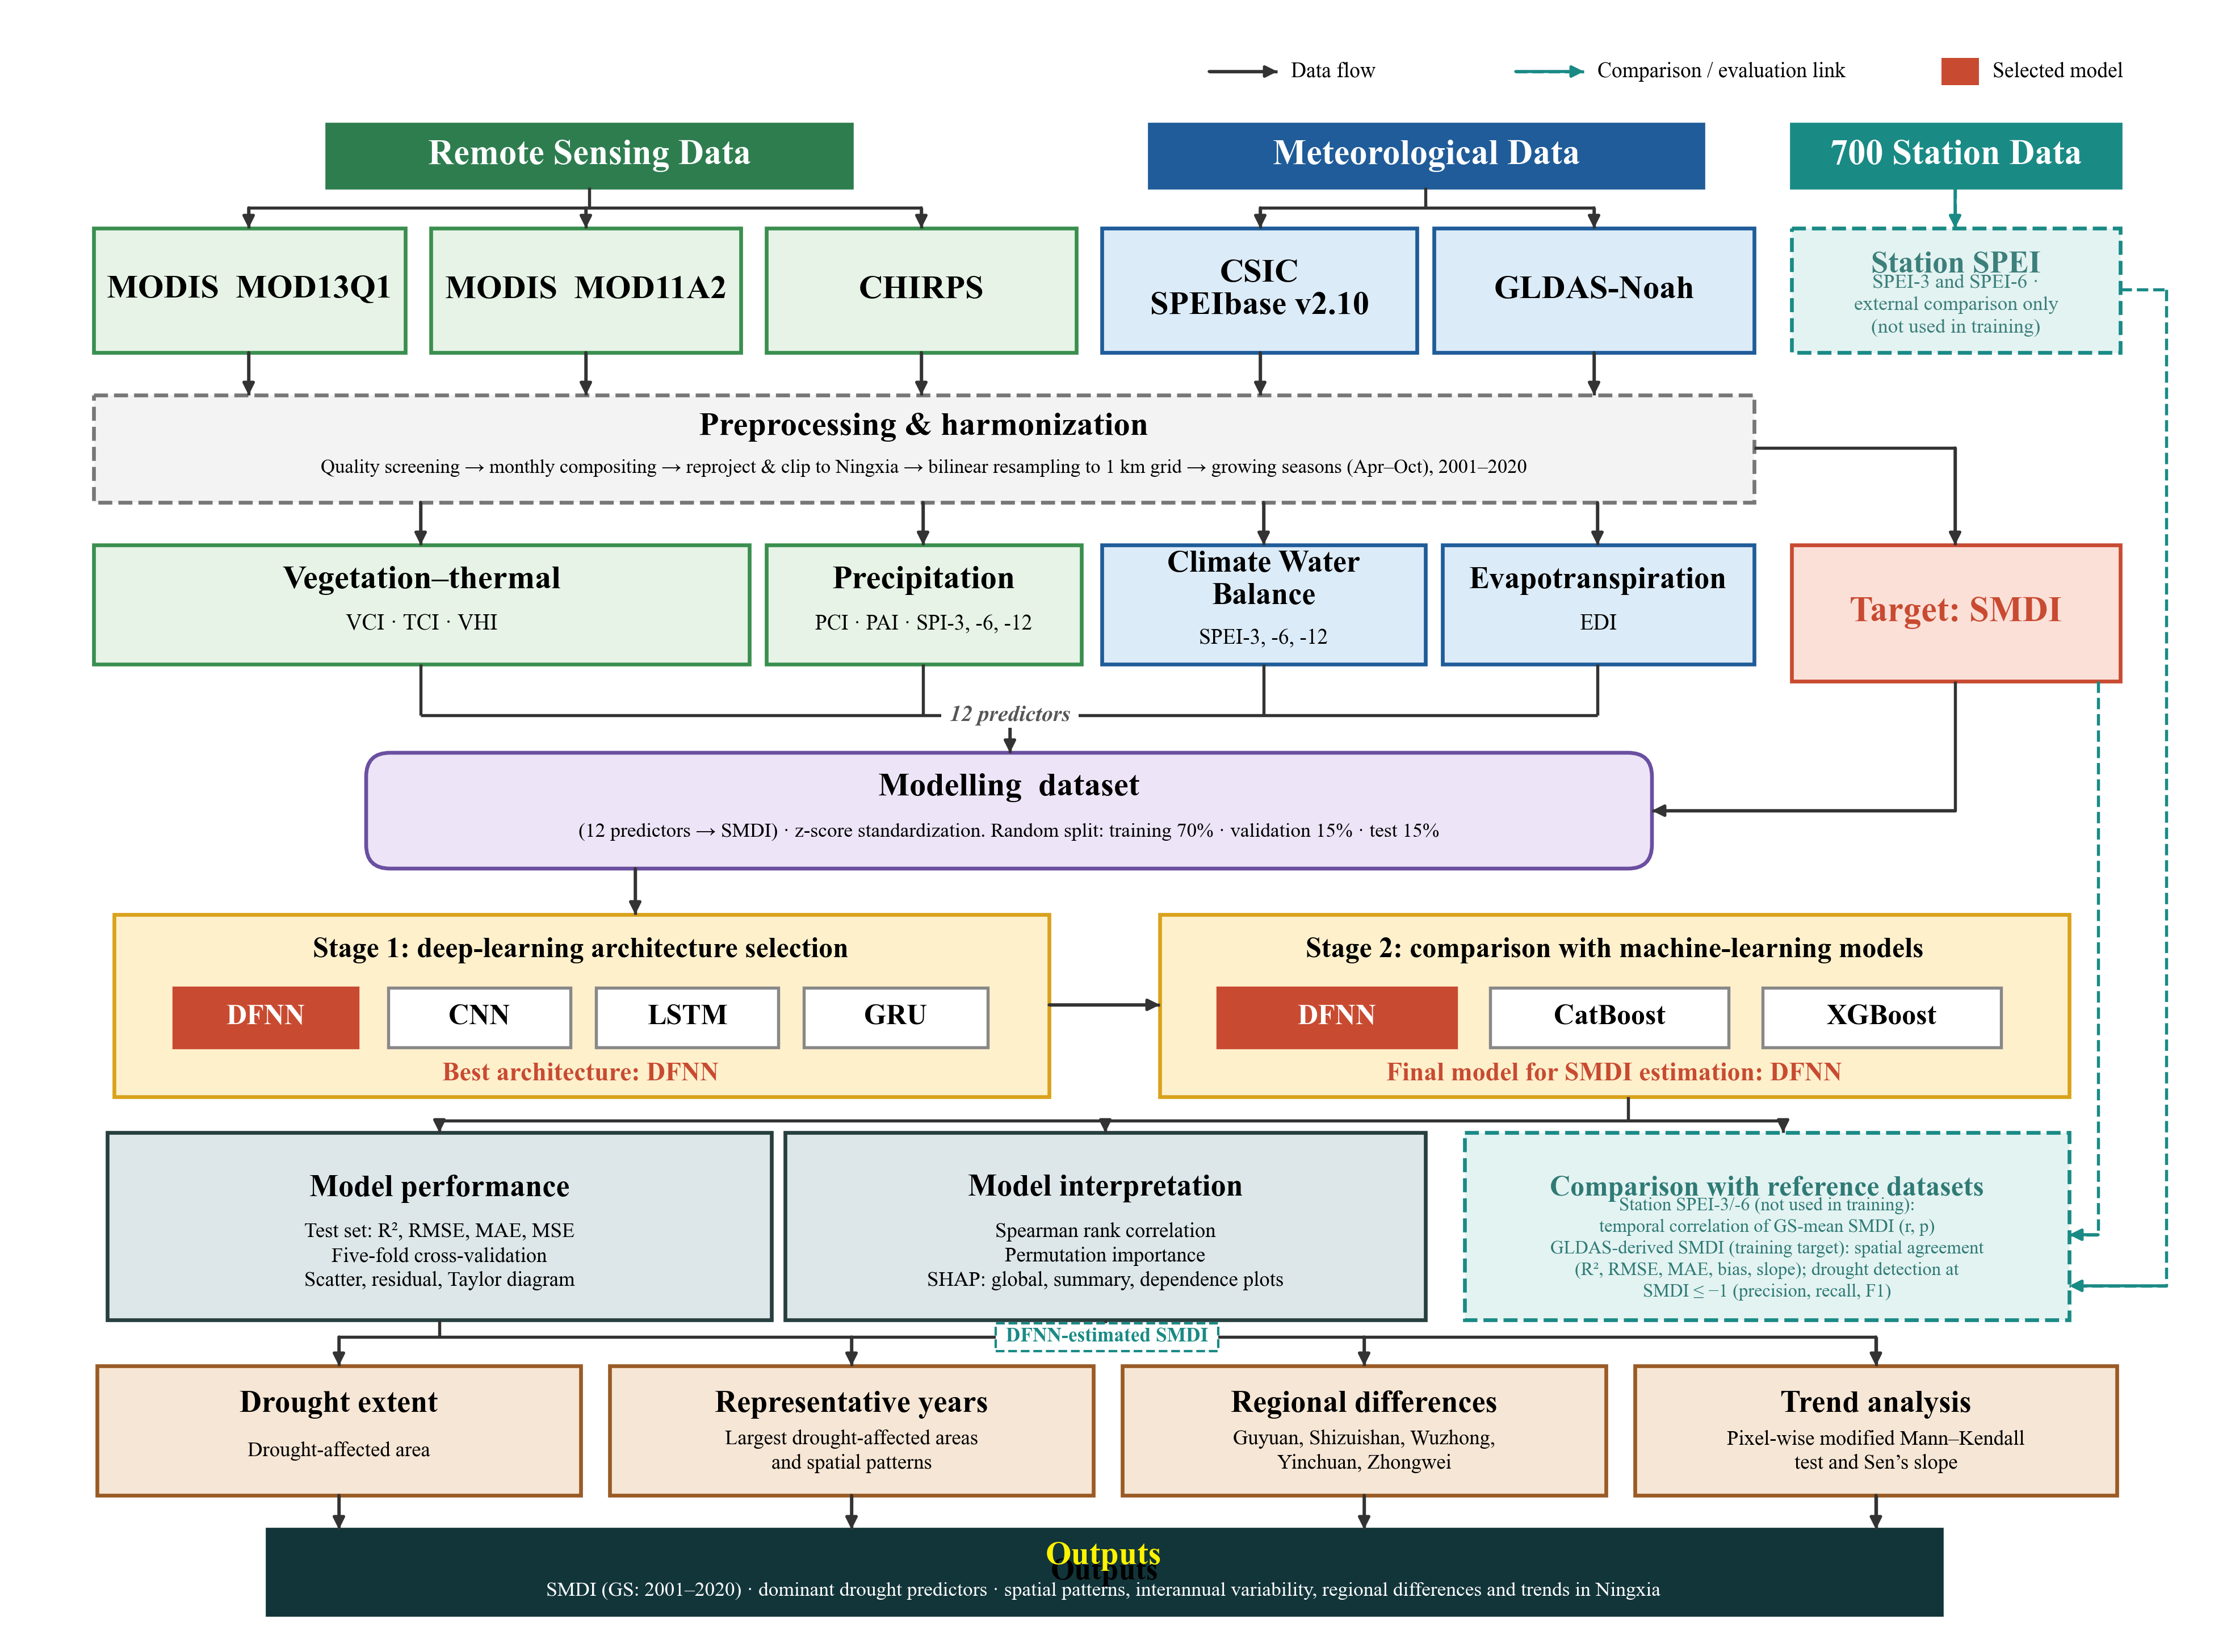

In [1]:
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Rectangle

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman', 'DejaVu Serif']

fig, ax = plt.subplots(figsize=(12.9, 9.5), dpi=300)
fig.subplots_adjust(0, 0, 1, 1)
ax.set_xlim(0, 1290); ax.set_ylim(950, 0); ax.axis('off')

TEAL = '#1A8A85'; DK = '#333333'

def box(x0, y0, x1, y1, title, sub=None, fc='white', ec='black', ls='-',
        tc='black', lw=1.6, rnd=0, tfs=13, sfs=8.5, sub_y=0.66):
    st = f'round,pad=0,rounding_size={rnd}' if rnd else 'square,pad=0'
    ax.add_patch(FancyBboxPatch((x0, y0), x1-x0, y1-y0, boxstyle=st,
                                fc=fc, ec=ec, ls=ls, lw=lw))
    cx, h = (x0+x1)/2, y1-y0
    if sub:
        ax.text(cx, y0+h*0.30, title, ha='center', va='center',
                fontsize=tfs, fontweight='bold', color=tc)
        ax.text(cx, y0+h*sub_y, sub, ha='center', va='center',
                fontsize=sfs, color=tc, linespacing=1.35)
    else:
        ax.text(cx, (y0+y1)/2, title, ha='center', va='center',
                fontsize=tfs, fontweight='bold', color=tc)

def arr(pts, color=DK, ls='-', lw=1.3, head=True):
    xs, ys = zip(*pts)
    ax.plot(xs, ys, color=color, ls=ls, lw=lw, solid_capstyle='butt')
    if head:
        ax.annotate('', xy=pts[-1], xytext=pts[-2],
                    arrowprops=dict(arrowstyle='-|>', color=color, lw=lw,
                                    shrinkA=0, shrinkB=0))

# ---------- legend ----------
arr([(700, 32), (740, 32)]); ax.text(748, 32, 'Data flow', va='center', fontsize=9)
arr([(880, 32), (920, 32)], color=TEAL, ls='--')
ax.text(928, 32, 'Comparison / evaluation link', va='center', fontsize=9)
ax.add_patch(Rectangle((1130, 24), 22, 16, fc='#C84B31', ec='none'))
ax.text(1160, 32, 'Selected model', va='center', fontsize=9)

# ---------- headers ----------
box(182, 63, 490, 100, 'Remote Sensing Data', fc='#2E7D4F', ec='#2E7D4F', tc='white', tfs=15)
box(665, 63, 990, 100, 'Meteorological Data', fc='#1F5C99', ec='#1F5C99', tc='white', tfs=15)
box(1042, 63, 1235, 100, '700 Station Data', fc=TEAL, ec=TEAL, tc='white', tfs=15)

# ---------- data boxes ----------
G = dict(fc='#E6F3E6', ec='#3A8F4F'); B = dict(fc='#DCEBF8', ec='#1F5C99')
box(45, 124, 228, 197, 'MODIS  MOD13Q1', tfs=14, **G)
box(243, 124, 425, 197, 'MODIS  MOD11A2', tfs=14, **G)
box(440, 124, 622, 197, 'CHIRPS', tfs=14, **G)
box(637, 124, 822, 197, 'CSIC\nSPEIbase v2.10', tfs=14, **B)
box(832, 124, 1020, 197, 'GLDAS-Noah', tfs=14, **B)
box(1042, 124, 1235, 197, 'Station SPEI',
    'SPEI-3 and SPEI-6 ·\nexternal comparison only\n(not used in training)',
    fc='#E3F3F2', ec=TEAL, ls='--', tc='#3C7F7B', tfs=13, sfs=8.5, sub_y=0.62)

arr([(336, 100), (336, 112)], head=False)
arr([(136, 112), (531, 112)], head=False)
for x in (136, 334, 531): arr([(x, 112), (x, 124)])
arr([(827, 100), (827, 112)], head=False)
arr([(730, 112), (926, 112)], head=False)
for x in (730, 926): arr([(x, 112), (x, 124)])
arr([(1138, 100), (1138, 124)], color=TEAL, ls='--')

# ---------- preprocessing ----------
box(45, 222, 1020, 285, 'Preprocessing & harmonization',
    'Quality screening → monthly compositing → reproject & clip to Ningxia → '
    'bilinear resampling to 1 km grid → growing seasons (Apr–Oct), 2001–2020',
    fc='#F3F3F3', ec='#777777', ls='--', tfs=14, sfs=8.3, sub_y=0.68)
for x in (136, 334, 531, 730, 926): arr([(x, 197), (x, 222)])

# ---------- feature groups ----------
box(45, 310, 430, 380, 'Vegetation–thermal', 'VCI · TCI · VHI', tfs=14, sfs=9.5, **G)
box(440, 310, 625, 380, 'Precipitation', 'PCI · PAI · SPI-3, -6, -12', tfs=14, sfs=9, **G)
box(637, 310, 827, 380, 'Climate Water\nBalance', 'SPEI-3, -6, -12', tfs=13, sfs=9, sub_y=0.78, **B)
box(837, 310, 1020, 380, 'Evapotranspiration', 'EDI', tfs=13, sfs=9.5, **B)
for x in (237, 532, 732, 928): arr([(x, 285), (x, 310)])

box(1042, 310, 1235, 390, 'Target: SMDI', fc='#FBE0D8', ec='#C84B31', tc='#C84B31', tfs=15)
arr([(1020, 253), (1138, 253), (1138, 310)])

# ---------- modelling dataset ----------
for x in (237, 532, 732, 928): arr([(x, 380), (x, 410)], head=False)
arr([(237, 410), (928, 410)], head=False)
arr([(583, 410), (583, 432)])
ax.text(583, 410, ' 12 predictors ', ha='center', va='center', fontsize=9.5,
        style='italic', fontweight='bold', color='#555555',
        bbox=dict(fc='white', ec='none', pad=1))
box(205, 432, 960, 500, 'Modelling  dataset',
    '(12 predictors → SMDI) · z-score standardization. Random split: '
    'training 70% · validation 15% · test 15%',
    fc='#EDE4F7', ec='#6B4FA0', rnd=14, tfs=14, sfs=8.5, sub_y=0.68)
arr([(1138, 390), (1138, 466), (960, 466)])

# ---------- stage 1 and 2 ----------
Y = dict(fc='#FFF0CC', ec='#D9A21B')
box(57, 527, 606, 634, '', **Y); box(671, 527, 1205, 634, '', **Y)
ax.text(331, 548, 'Stage 1: deep-learning architecture selection', ha='center', va='center', fontsize=12, fontweight='bold')
ax.text(938, 548, 'Stage 2: comparison with machine-learning models', ha='center', va='center', fontsize=12, fontweight='bold')
RED = '#C84B31'
def chip(x0, x1, t, sel=False):
    box(x0, 570, x1, 605, t, fc=RED if sel else 'white', ec=RED if sel else '#888888',
        tc='white' if sel else 'black', tfs=12, lw=1.3)
chip(92, 200, 'DFNN', True); chip(218, 325, 'CNN'); chip(340, 447, 'LSTM'); chip(462, 570, 'GRU')
chip(705, 845, 'DFNN', True); chip(865, 1005, 'CatBoost'); chip(1025, 1165, 'XGBoost')
ax.text(331, 621, 'Best architecture: DFNN', ha='center', va='center', color=RED, fontsize=11, fontweight='bold')
ax.text(938, 621, 'Final model for SMDI estimation: DFNN', ha='center', va='center', color=RED, fontsize=11, fontweight='bold')
arr([(363, 500), (363, 527)])
arr([(606, 580), (671, 580)])

# ---------- performance / interpretation / comparison ----------
arr([(946, 634), (946, 648)], head=False)
arr([(248, 648), (1037, 648)], head=False)
for x in (248, 639): arr([(x, 648), (x, 655)])
arr([(1037, 648), (1037, 655)], color=DK)
GR = dict(fc='#DDE6E8', ec='#27403F')
box(53, 655, 443, 765, 'Model performance',
    'Test set: R², RMSE, MAE, MSE\nFive-fold cross-validation\nScatter, residual, Taylor diagram',
    tfs=13, sfs=8.8, **GR)
box(451, 655, 827, 765, 'Model interpretation',
    'Spearman rank correlation\nPermutation importance\nSHAP: global, summary, dependence plots',
    tfs=13, sfs=8.8, **GR)
box(850, 655, 1205, 765, 'Comparison with reference datasets',
    'Station SPEI-3/-6 (not used in training):\ntemporal correlation of GS-mean SMDI (r, p)\n'
    'GLDAS-derived SMDI (training target): spatial agreement\n(R², RMSE, MAE, bias, slope); drought detection at\nSMDI ≤ −1 (precision, recall, F1)',
    fc='#E3F3F2', ec=TEAL, ls='--', tc='#2F7A75', tfs=12, sfs=7.8, sub_y=0.62)
# dashed reference links into comparison box
arr([(1262, 160), (1262, 745), (1205, 745)], color=TEAL, ls='--')
arr([(1235, 160), (1262, 160)], color=TEAL, ls='--', head=False)
arr([(1222, 390), (1222, 715), (1205, 715)], color=TEAL, ls='--')

# ---------- downstream analyses ----------
arr([(248, 765), (248, 775)], head=False); arr([(639, 765), (639, 775)], head=False)
arr([(189, 775), (1091, 775)], head=False)
ax.text(640, 775, ' DFNN-estimated SMDI ', ha='center', va='center', fontsize=8.5,
        fontweight='bold', color=TEAL, bbox=dict(fc='white', ec=TEAL, ls='--', pad=2))
BG = dict(fc='#F6E6D5', ec='#9A5B25')
items = [(47, 331, 'Drought extent', 'Drought-affected area'),
         (348, 632, 'Representative years', 'Largest drought-affected areas\nand spatial patterns'),
         (649, 933, 'Regional differences', 'Guyuan, Shizuishan, Wuzhong,\nYinchuan, Zhongwei'),
         (950, 1233, 'Trend analysis', 'Pixel-wise modified Mann–Kendall\ntest and Sen’s slope')]
for x0, x1, t, s in items:
    box(x0, 792, x1, 868, t, s, tfs=13, sfs=8.8, **BG)
    cx = (x0+x1)/2
    arr([(cx, 775), (cx, 792)]); arr([(cx, 868), (cx, 888)])

box(147, 888, 1130, 938, 'Outputs', '', fc='#12353A', ec='#12353A')
ax.text(638, 904, 'Outputs', ha='center', va='center', fontsize=14, fontweight='bold', color='#FFF200')
ax.text(638, 924, 'SMDI (GS: 2001–2020) · dominant drought predictors · spatial patterns, '
        'interannual variability, regional differences and trends in Ningxia',
        ha='center', va='center', fontsize=8.5, color='white')

fig.savefig('flowchart_300dpi.png', dpi=300)
fig.savefig('flowchart_300dpi.pdf')